# Leakage-Free, Novelty-Aware Intrusion Detection on NSL-KDD
**A protocol-honest benchmark with leave-one-family-out validated hybrid supervised–anomaly fusion**

Dataset folder: `My Drive/ICEEICT/Paper 2/Dataset` (files at the root or in the `nsl-kdd` sub-folder).

**Evaluation protocol (fixed before any experiment):**
- Official split only: models learn from **KDDTrain+**; **KDDTest+** and **KDDTest-21** are touched once, for reporting.
- **Validation** = stratified 20% of KDDTrain+ (by fine attack name); every encoder, scaler, selector, sampler, threshold and weight is fitted on the training part only.
- Early stopping uses an inner split carved from the training part, never the validation set.
- Novelty settings (fusion weight, threshold) are chosen by **leave-one-attack-family-out (LOFO)** validation inside KDDTrain+.
- Post-hoc tuning on validation is **cross-fitted** so that reported validation scores stay unbiased.

**Limitations of the 15 related works → where this notebook addresses them**

| Limitation in related work | Papers | Novelties |
|---|---|---|
| ~99% results from random 80:20 splits of KDDTrain+ | 2, 3, 5, 7 | 18–21, 31–32, 79 |
| Aggregate accuracy hides R2L/U2R failure | 1, 2, 7 | 29–30, 47–55, 73–75 |
| Zero-day / unseen attacks not evaluated | 2, 4, 6, 9 | 4, 21, 56–68 |
| Distribution shift between train and test ignored | 1, 5, 14 | 10–12, 65, 96 |
| Feature reduction may remove useful signal | 2, 7, 9 | 23–28 |
| No significance testing or confidence intervals | 7, 15 | 81–85 |
| Limited or unstable explainability | 3, 6, 10, 15 | 86–91 |
| No adversarial / robustness evaluation | 1, 3, 12, 14 | 92–95 |
| Efficiency and deployability rarely measured | 1, 5, 10, 13 | 97–99 |
| Reproducibility not ensured | 2, 7, 14, 15 | 1–2, 19, 100 |
| Hyper-parameters not tuned or tuned on test | 4, 13 | 35–37 |
| Uncalibrated, overconfident outputs | 1, 11 | 67, 77 |

### Install required packages

In [1]:
!pip -q install xgboost lightgbm catboost imbalanced-learn shap optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 22.8 MB/s eta 0:00:00


### Import libraries

In [2]:
import os, sys, time, json, pickle, hashlib, platform, warnings, itertools, math, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.lines import Line2D
from IPython.display import display
from scipy import stats
from scipy.optimize import minimize
from scipy.cluster import hierarchy
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef,
    confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    recall_score, precision_score, log_loss, classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier,
    IsolationForest)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, LocalOutlierFactor, NearestNeighbors
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPRegressor
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.covariance import LedoitWolf
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore')

def _opt(name):
    try:
        return __import__(name)
    except Exception:
        return None

xgb, lgb, cb, shap, optuna = _opt('xgboost'), _opt('lightgbm'), _opt('catboost'), _opt('shap'), _opt('optuna')
try:
    from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN, RandomOverSampler
    from imblearn.combine import SMOTETomek
    from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier
    IMB = True
except Exception:
    IMB = False
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
except Exception:
    tf = None
print(pd.DataFrame({'available': {'xgboost': xgb is not None, 'lightgbm': lgb is not None, 'catboost': cb is not None,
    'shap': shap is not None, 'optuna': optuna is not None, 'imbalanced-learn': IMB, 'tensorflow': tf is not None}}))

                  available
xgboost                True
lightgbm               True
catboost               True
shap                   True
optuna                 True
imbalanced-learn       True
tensorflow             True


### Configuration, reproducibility and publication figure style

In [3]:
SEED = 42
FAST = False
N_JOBS = -1
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED); np.random.seed(SEED)
if tf is not None:
    tf.random.set_seed(SEED)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass
sns.set_theme(style='whitegrid', context='paper', font_scale=1.15)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.family': 'DejaVu Sans'})
PAL = sns.color_palette('colorblind')
CLASSES = ['normal', 'dos', 'probe', 'r2l', 'u2r']
CCOL = dict(zip(CLASSES, [PAL[2], PAL[3], PAL[0], PAL[4], PAL[1]]))
FIG_N = [0]

def savefig(name):
    FIG_N[0] += 1
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'Fig{FIG_N[0]:03d}_{name}.png'), bbox_inches='tight')
    plt.show()

def save_table(df, name):
    df.to_csv(os.path.join(TAB_DIR, f'{name}.csv'))
    return df

print('SEED', SEED, '| FAST mode', FAST)

SEED 42 | FAST mode False


### Locate the dataset on Google Drive

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass
ROOT = '/content/drive/MyDrive/ICEEICT/Paper 2'
CANDIDATES = [os.environ.get('NSL_DIR', ''), os.path.join(ROOT, 'Dataset'), os.path.join(ROOT, 'Dataset', 'nsl-kdd'),
              './Dataset', './Dataset/nsl-kdd']
DATA_DIR = next((d for d in CANDIDATES if d and os.path.exists(os.path.join(d, 'KDDTrain+.txt'))), None)
assert DATA_DIR, 'KDDTrain+.txt not found under My Drive/ICEEICT/Paper 2/Dataset'
BASE_OUT = ROOT if os.path.exists(ROOT) else '.'
OUT_DIR = os.path.join(BASE_OUT, 'outputs')
FIG_DIR, TAB_DIR = os.path.join(OUT_DIR, 'figures'), os.path.join(OUT_DIR, 'tables')
for d in (OUT_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)
print('Data   :', DATA_DIR)
print('Output :', OUT_DIR)
print(sorted(os.listdir(DATA_DIR)))

Mounted at /content/drive
Data   : /content/drive/MyDrive/ICEEICT/Paper 2/Dataset
Output : /content/drive/MyDrive/ICEEICT/Paper 2/outputs
['KDDTest+.arff', 'KDDTest+.txt', 'KDDTest-21.arff', 'KDDTest-21.txt', 'KDDTest1.jpg', 'KDDTrain+.arff', 'KDDTrain+.txt', 'KDDTrain+_20Percent.arff', 'KDDTrain+_20Percent.txt', 'KDDTrain1.jpg', 'index.html', 'nsl-kdd']


### Load the four NSL-KDD files and build the attack taxonomy

In [5]:
COLS = ['duration','protocol_type','service','flag','src_bytes','dst_bytes','land','wrong_fragment','urgent','hot',
 'num_failed_logins','logged_in','num_compromised','root_shell','su_attempted','num_root','num_file_creations',
 'num_shells','num_access_files','num_outbound_cmds','is_host_login','is_guest_login','count','srv_count',
 'serror_rate','srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate','diff_srv_rate',
 'srv_diff_host_rate','dst_host_count','dst_host_srv_count','dst_host_same_srv_rate','dst_host_diff_srv_rate',
 'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate','dst_host_serror_rate','dst_host_srv_serror_rate',
 'dst_host_rerror_rate','dst_host_srv_rerror_rate','label','difficulty']
FEATS = COLS[:41]
CATS = ['protocol_type', 'service', 'flag']
NUM = [c for c in FEATS if c not in CATS]
FAMILY = {'dos': ['back','land','neptune','pod','smurf','teardrop','apache2','udpstorm','processtable','worm','mailbomb'],
          'probe': ['satan','ipsweep','nmap','portsweep','mscan','saint'],
          'r2l': ['guess_passwd','ftp_write','imap','phf','multihop','warezmaster','warezclient','spy','xlock','xsnoop',
                  'snmpguess','snmpgetattack','httptunnel','sendmail','named'],
          'u2r': ['buffer_overflow','loadmodule','rootkit','perl','sqlattack','xterm','ps']}
AMAP = {'normal': 'normal', **{n: f for f, ns in FAMILY.items() for n in ns}}
CIDX = {c: i for i, c in enumerate(CLASSES)}

def load(name):
    d = pd.read_csv(os.path.join(DATA_DIR, name), header=None, names=COLS)
    d['cat'] = d['label'].map(AMAP)
    assert d['cat'].notna().all(), name
    d['y'] = d['cat'].map(CIDX).astype(int)
    d['bin'] = (d['y'] > 0).astype(int)
    return d

trn, tst, t21, t20 = load('KDDTrain+.txt'), load('KDDTest+.txt'), load('KDDTest-21.txt'), load('KDDTrain+_20Percent.txt')
SEEN = set(trn['label'])
for d in (tst, t21):
    d['novel'] = ~d['label'].isin(SEEN)
display(pd.DataFrame({'Records': [len(trn), len(t20), len(tst), len(t21)], 'Columns': [trn.shape[1]] * 4,
                      'Attack names': [trn.label.nunique() - 1, t20.label.nunique() - 1, tst.label.nunique() - 1, t21.label.nunique() - 1]},
                     index=['KDDTrain+', 'KDDTrain+_20Percent', 'KDDTest+', 'KDDTest-21']))

,Records,Columns,Attack names
KDDTrain+,125973,46,22
KDDTrain+_20Percent,25192,46,21
KDDTest+,22544,46,37
KDDTest-21,11850,46,37


## Part A — Dataset audit

### 1. Integrity audit of both folder copies and official record counts

In [6]:
def md5(p):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''):
            h.update(b)
    return h.hexdigest()

parent = DATA_DIR[:-len('/nsl-kdd')] if DATA_DIR.endswith('nsl-kdd') else DATA_DIR
sub = os.path.join(parent, 'nsl-kdd')
OFFICIAL = {'KDDTrain+.txt': 125973, 'KDDTrain+_20Percent.txt': 25192, 'KDDTest+.txt': 22544, 'KDDTest-21.txt': 11850}
rows = []
for f in sorted(os.listdir(parent)):
    p1 = os.path.join(parent, f)
    if not os.path.isfile(p1) or f.endswith(('.jpg', '.html')):
        continue
    p2 = os.path.join(sub, f)
    h1 = md5(p1)
    h2 = md5(p2) if os.path.exists(p2) else None
    n = sum(1 for _ in open(p1)) if f.endswith('.txt') else np.nan
    rows.append({'File': f, 'MD5 (root)': h1[:12], 'Identical copy in nsl-kdd/': (h1 == h2) if h2 else 'n/a',
                 'Records': n, 'Official records': OFFICIAL.get(f, np.nan),
                 'Count verified': (n == OFFICIAL[f]) if f in OFFICIAL else 'n/a'})
INTEGRITY = save_table(pd.DataFrame(rows).set_index('File'), 'T01_integrity')
display(INTEGRITY)

,MD5 (root),Identical copy in nsl-kdd/,Records,Official records,Count verified
File,,,,,
KDDTest+.arff,0af8c3754211,True,NaN,NaN,n/a
KDDTest+.txt,7c6d1b1af246,True,22544.0,22544.0,True
KDDTest-21.arff,8feb561bcc1e,True,NaN,NaN,n/a
KDDTest-21.txt,02368ff472bb,True,11850.0,11850.0,True
KDDTrain+.arff,8e351c7ac395,True,NaN,NaN,n/a
KDDTrain+.txt,f5592a95d1d1,True,125973.0,125973.0,True
KDDTrain+_20Percent.arff,f83729ea711e,True,NaN,NaN,n/a
KDDTrain+_20Percent.txt,e160feff7844,True,25192.0,25192.0,True


### 2. ARFF schema versus TXT column verification

In [7]:
rows = []
for f in ['KDDTrain+.arff', 'KDDTest+.arff', 'KDDTest-21.arff', 'KDDTrain+_20Percent.arff']:
    p = os.path.join(DATA_DIR, f)
    if not os.path.exists(p):
        continue
    attrs, n_data, in_data = [], 0, False
    with open(p) as fh:
        for line in fh:
            s = line.strip()
            if s.lower().startswith('@attribute'):
                attrs.append(s.split()[1].strip("'"))
            elif s.lower().startswith('@data'):
                in_data = True
            elif in_data and s:
                n_data += 1
    rows.append({'ARFF file': f, 'Attributes': len(attrs), '41 names match TXT schema': attrs[:41] == FEATS,
                 'Label attribute': attrs[-1] if attrs else None, 'ARFF records': n_data,
                 'TXT records': len({'KDDTrain+.arff': trn, 'KDDTest+.arff': tst, 'KDDTest-21.arff': t21,
                                     'KDDTrain+_20Percent.arff': t20}[f])})
display(save_table(pd.DataFrame(rows).set_index('ARFF file'), 'T02_arff_schema'))

,Attributes,41 names match TXT schema,Label attribute,ARFF records,TXT records
ARFF file,,,,,
KDDTrain+.arff,42,True,class,125973,125973
KDDTest+.arff,42,True,class,22544,22544
KDDTest-21.arff,42,True,class,11850,11850
KDDTrain+_20Percent.arff,42,True,class,25192,25192


### 3. Five-class distribution across KDDTrain+, KDDTest+ and KDDTest-21

,KDDTrain+,KDDTest+,KDDTest-21,KDDTrain+ %,KDDTest+ %,KDDTest-21 %
cat,,,,,,
normal,67343,9711,2152,53.46,43.08,18.16
dos,45927,7460,4344,36.46,33.09,36.66
probe,11656,2421,2402,9.25,10.74,20.27
r2l,995,2885,2885,0.79,12.80,24.35
u2r,52,67,67,0.04,0.30,0.57


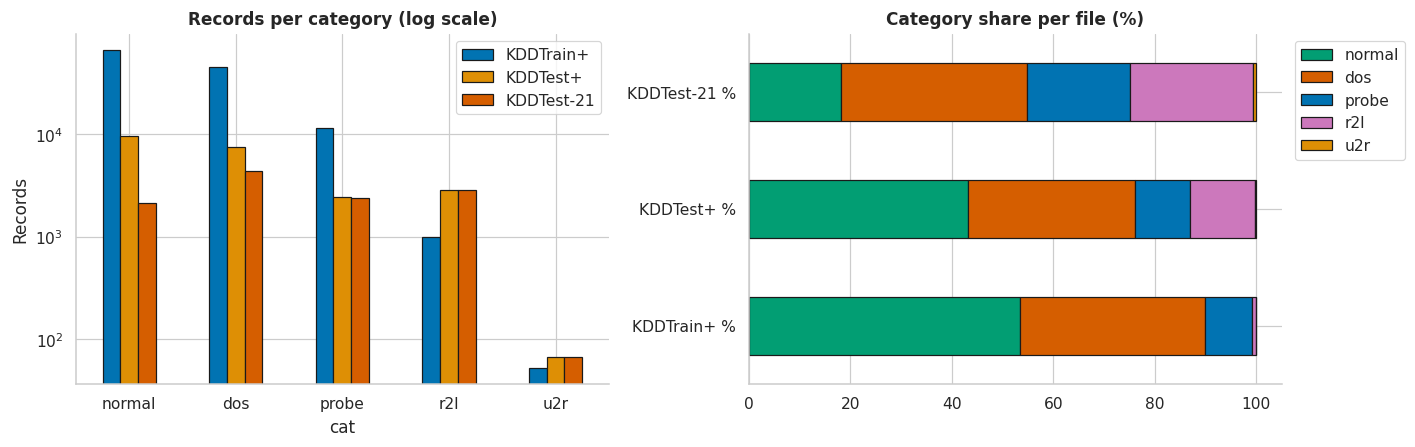

In [8]:
DIST = pd.concat([d['cat'].value_counts().reindex(CLASSES).rename(n) for d, n in
                  [(trn, 'KDDTrain+'), (tst, 'KDDTest+'), (t21, 'KDDTest-21')]], axis=1)
SHARE = (100 * DIST / DIST.sum()).round(2).add_suffix(' %')
display(save_table(pd.concat([DIST, SHARE], axis=1), 'T03_class_distribution'))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
DIST.plot.bar(ax=ax[0], logy=True, rot=0, color=[PAL[0], PAL[1], PAL[3]], edgecolor='k')
ax[0].set_title('Records per category (log scale)'); ax[0].set_ylabel('Records')
SHARE.T.plot.barh(stacked=True, ax=ax[1], color=[CCOL[c] for c in CLASSES], edgecolor='k')
ax[1].set_title('Category share per file (%)'); ax[1].legend(CLASSES, bbox_to_anchor=(1.01, 1), loc='upper left')
savefig('class_distribution')

### 4. Attack-name inventory: seen versus zero-day names

,KDDTrain+,KDDTest+,KDDTest-21,Category,Zero-day (absent from train)
label,,,,,
neptune,41214,4657,1579,dos,False
apache2,0,737,737,dos,True
processtable,0,685,685,dos,True
smurf,2646,665,627,dos,False
back,956,359,359,dos,False
mailbomb,0,293,293,dos,True
pod,201,41,41,dos,False
teardrop,892,12,12,dos,False
land,18,7,7,dos,False


,Zero-day test records,Share of file (%),Zero-day names
KDDTest+,3750,16.63,17
KDDTest-21,3740,31.56,17


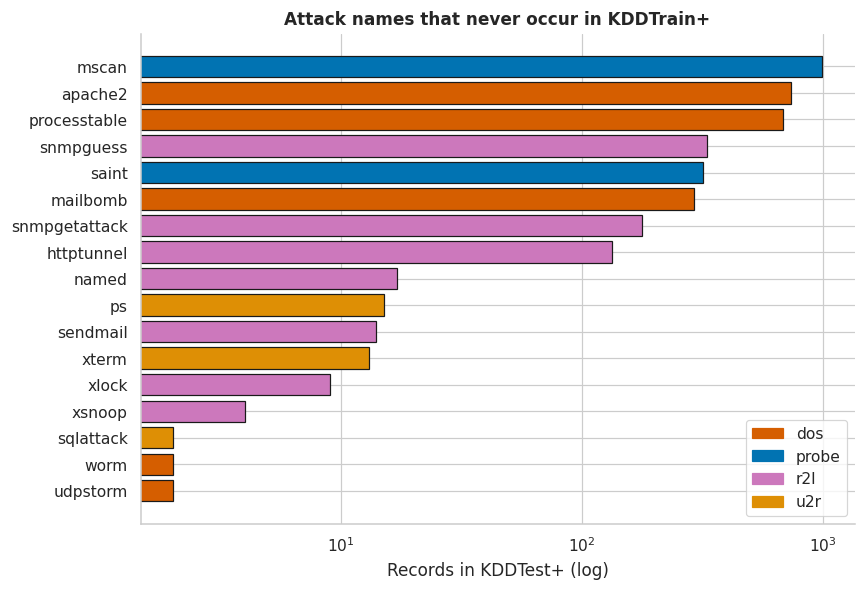

In [9]:
inv = (pd.concat([trn.groupby('label').size().rename('KDDTrain+'), tst.groupby('label').size().rename('KDDTest+'),
                  t21.groupby('label').size().rename('KDDTest-21')], axis=1).fillna(0).astype(int))
inv['Category'] = inv.index.map(AMAP)
inv['Zero-day (absent from train)'] = inv['KDDTrain+'] == 0
inv = inv.drop('normal').sort_values(['Category', 'KDDTest+'], ascending=[True, False])
display(save_table(inv, 'T04_attack_inventory'))
summ = pd.DataFrame({'Zero-day test records': [int(tst.novel.sum()), int(t21.novel.sum())],
                     'Share of file (%)': [round(100 * tst.novel.mean(), 2), round(100 * t21.novel.mean(), 2)],
                     'Zero-day names': [tst.loc[tst.novel, 'label'].nunique(), t21.loc[t21.novel, 'label'].nunique()]},
                    index=['KDDTest+', 'KDDTest-21'])
display(summ)
nv = inv[inv['Zero-day (absent from train)']].sort_values('KDDTest+')
plt.figure(figsize=(8, 5.5))
plt.barh(nv.index, nv['KDDTest+'], color=[CCOL[c] for c in nv['Category']], edgecolor='k')
plt.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CCOL[c]) for c in CLASSES[1:]], labels=CLASSES[1:], loc='lower right')
plt.xscale('log'); plt.xlabel('Records in KDDTest+ (log)'); plt.title('Attack names that never occur in KDDTrain+')
savefig('zero_day_inventory')

### 5. Difficulty-level profile per split

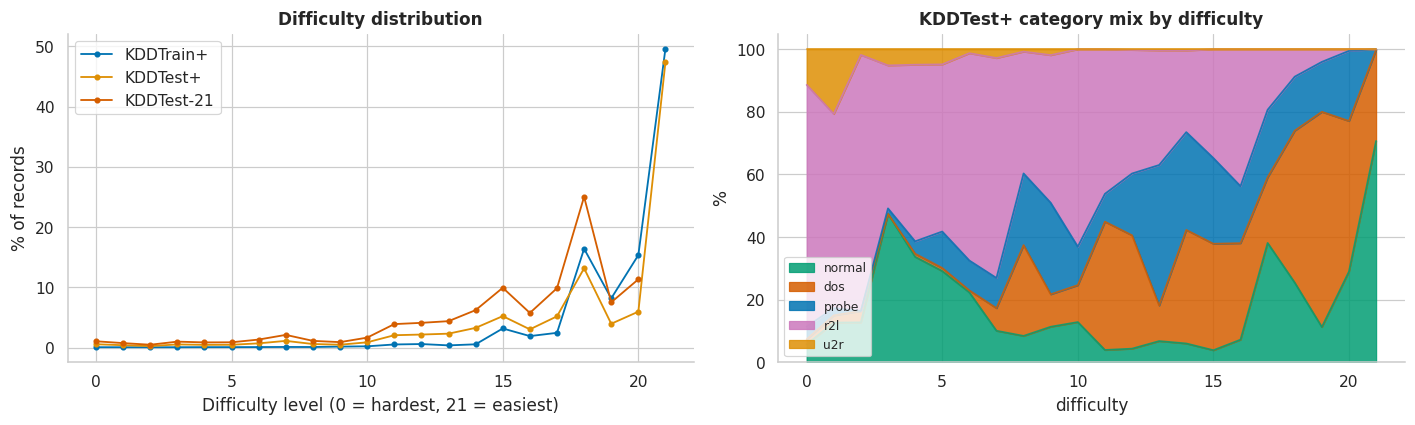

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for d, n, c in [(trn, 'KDDTrain+', PAL[0]), (tst, 'KDDTest+', PAL[1]), (t21, 'KDDTest-21', PAL[3])]:
    vc = d['difficulty'].value_counts(normalize=True).sort_index()
    ax[0].plot(vc.index, 100 * vc.values, marker='o', ms=3, label=n, color=c)
ax[0].set_xlabel('Difficulty level (0 = hardest, 21 = easiest)'); ax[0].set_ylabel('% of records'); ax[0].legend()
ax[0].set_title('Difficulty distribution')
pt = tst.groupby(['difficulty', 'cat']).size().unstack(fill_value=0).reindex(columns=CLASSES)
(pt.div(pt.sum(1), axis=0) * 100).plot.area(ax=ax[1], color=[CCOL[c] for c in CLASSES], alpha=.85)
ax[1].set_title('KDDTest+ category mix by difficulty'); ax[1].set_ylabel('%'); ax[1].legend(loc='lower left', fontsize=8)
savefig('difficulty_profile')

### 6. Exact-duplicate and cross-split overlap audit

In [11]:
def row_hash(d, cols=FEATS):
    return pd.util.hash_pandas_object(d[cols], index=False).values

H = {n: row_hash(d) for n, d in [('KDDTrain+', trn), ('KDDTest+', tst), ('KDDTest-21', t21)]}
rows = [{'Check': f'Duplicate feature rows inside {n}', 'Count': len(h) - len(np.unique(h))} for n, h in H.items()]
rows += [{'Check': 'Rows of KDDTest+ identical to a KDDTrain+ row', 'Count': int(np.isin(H['KDDTest+'], H['KDDTrain+']).sum())},
         {'Check': 'Rows of KDDTest-21 identical to a KDDTrain+ row', 'Count': int(np.isin(H['KDDTest-21'], H['KDDTrain+']).sum())}]
tst['in_train'] = np.isin(H['KDDTest+'], H['KDDTrain+'])
t21['in_train'] = np.isin(H['KDDTest-21'], H['KDDTrain+'])
display(save_table(pd.DataFrame(rows).set_index('Check'), 'T05_duplicate_audit'))

,Count
Check,
Duplicate feature rows inside KDDTrain+,16
Duplicate feature rows inside KDDTest+,57
Duplicate feature rows inside KDDTest-21,55
Rows of KDDTest+ identical to a KDDTrain+ row,664
Rows of KDDTest-21 identical to a KDDTrain+ row,529


### 7. Label-conflict audit (identical features, different labels)

In [12]:
g = pd.DataFrame({'h': H['KDDTrain+'], 'cat': trn['cat'].values, 'label': trn['label'].values})
nc = g.groupby('h')['cat'].nunique()
nl = g.groupby('h')['label'].nunique()
conf = g[g['h'].isin(nc[nc > 1].index)].groupby('h')['cat'].apply(lambda s: ' / '.join(sorted(set(s))))
display(pd.DataFrame({'Value': [len(nc), int((nc > 1).sum()), int((nl > 1).sum()),
                                round(100 * (nc > 1).mean(), 4)]},
                     index=['Distinct feature vectors', 'Vectors mapped to >1 category', 'Vectors mapped to >1 attack name',
                            'Irreducible category conflict (%)']))
display(conf.value_counts().rename('Conflicting vectors').to_frame())

,Value
Distinct feature vectors,125957.0000
Vectors mapped to >1 category,7.0000
Vectors mapped to >1 attack name,15.0000
Irreducible category conflict (%),0.0056


,Conflicting vectors
cat,
dos / normal,5
normal / probe,1
normal / u2r,1


### 8. Constant and near-zero-variance feature audit

In [13]:
rows = []
for c in NUM:
    v = trn[c]
    top = v.value_counts(normalize=True).iloc[0]
    rows.append({'Feature': c, 'Unique (train)': v.nunique(), 'Top value share (%)': round(100 * top, 3),
                 'Std (train)': round(v.std(), 4), 'Unique (test)': tst[c].nunique(),
                 'Status': 'constant' if v.nunique() <= 1 else ('near-zero variance' if top > 0.999 else 'informative')})
NZV = pd.DataFrame(rows).set_index('Feature').sort_values('Top value share (%)', ascending=False)
display(save_table(NZV.head(15), 'T06_near_zero_variance'))
print(NZV['Status'].value_counts().to_dict())

,Unique (train),Top value share (%),Std (train),Unique (test),Status
Feature,,,,,
num_outbound_cmds,1,100.000,0.0000,1,constant
is_host_login,2,99.999,0.0028,2,near-zero variance
urgent,4,99.993,0.0144,4,near-zero variance
land,2,99.980,0.0141,2,near-zero variance
num_shells,3,99.963,0.0222,4,near-zero variance
su_attempted,3,99.936,0.0452,3,near-zero variance
num_failed_logins,6,99.903,0.0452,5,near-zero variance
root_shell,2,99.866,0.0366,2,informative
num_file_creations,35,99.772,0.4839,9,informative


{'informative': 31, 'near-zero variance': 6, 'constant': 1}


### 9. Unseen categorical values in the official test files

In [14]:
rows = []
for c in CATS:
    tr_v = set(trn[c])
    for n, d in [('KDDTest+', tst), ('KDDTest-21', t21)]:
        un = sorted(set(d[c]) - tr_v)
        rows.append({'Feature': c, 'File': n, 'Train levels': len(tr_v), 'File levels': d[c].nunique(),
                     'Unseen levels': len(un), 'Records with unseen level': int(d[c].isin(un).sum()), 'Examples': ', '.join(un[:6])})
    rare = trn[c].value_counts()
    rows[-1]['Train levels with <20 records'] = int((rare < 20).sum())
display(save_table(pd.DataFrame(rows), 'T07_unseen_categories'))

,Feature,File,Train levels,File levels,Unseen levels,Records with unseen level,Examples,Train levels with <20 records
0,protocol_type,KDDTest+,3,3,0,0,,NaN
1,protocol_type,KDDTest-21,3,3,0,0,,0.0
2,service,KDDTest+,70,64,0,0,,NaN
3,service,KDDTest-21,70,62,0,0,,9.0
4,flag,KDDTest+,11,11,0,0,,NaN
5,flag,KDDTest-21,11,11,0,0,,0.0


### 10. Kolmogorov–Smirnov shift test per feature with Holm correction

In [15]:
rows = []
for c in NUM:
    if trn[c].nunique() <= 1:
        continue
    ks = stats.ks_2samp(trn[c], tst[c])
    rows.append({'Feature': c, 'KS statistic': ks.statistic, 'p-value': ks.pvalue})
KS = pd.DataFrame(rows).sort_values('p-value').reset_index(drop=True)
m = len(KS)
KS['Holm p'] = np.minimum(1, np.maximum.accumulate(KS['p-value'] * (m - np.arange(m))))
KS['Shifted (Holm<0.01)'] = KS['Holm p'] < 0.01
KS = KS.sort_values('KS statistic', ascending=False).set_index('Feature')
display(save_table(KS.head(15).round(5), 'T08_ks_shift'))
print('Features with significant train→test shift:', int(KS['Shifted (Holm<0.01)'].sum()), 'of', m)

,KS statistic,p-value,Holm p,Shifted (Holm<0.01)
Feature,,,,
dst_host_rerror_rate,0.22603,0.0,0.0,True
dst_host_serror_rate,0.20251,0.0,0.0,True
dst_host_srv_serror_rate,0.19682,0.0,0.0,True
serror_rate,0.18539,0.0,0.0,True
srv_serror_rate,0.18138,0.0,0.0,True
dst_host_srv_rerror_rate,0.16798,0.0,0.0,True
rerror_rate,0.13028,0.0,0.0,True
dst_bytes,0.12408,0.0,0.0,True
srv_rerror_rate,0.12365,0.0,0.0,True


Features with significant train→test shift: 25 of 37


### 11. Population Stability Index ranking

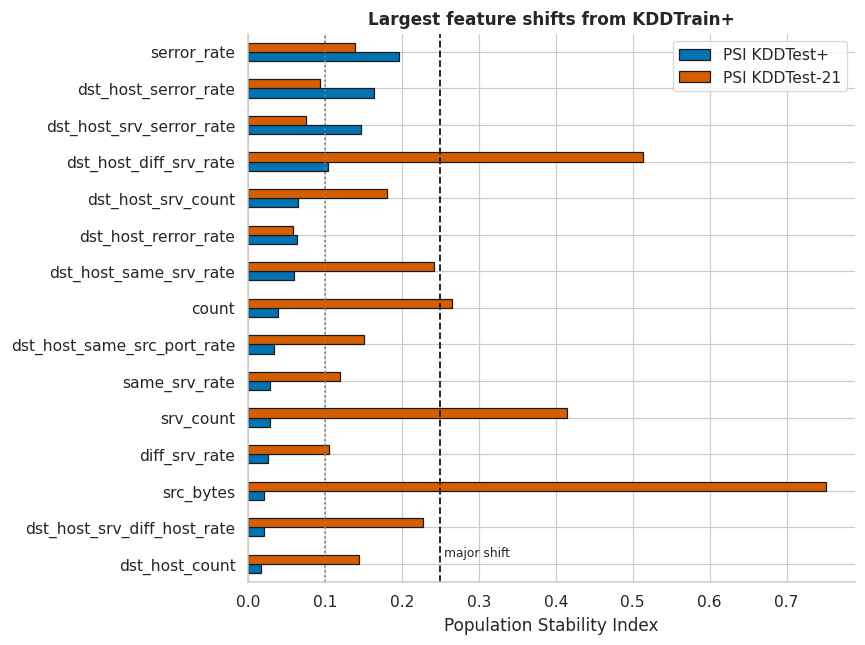

In [16]:
def psi(a, b, bins=10):
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    pa = np.histogram(a, edges)[0] / len(a) + 1e-4
    pb = np.histogram(b, edges)[0] / len(b) + 1e-4
    return float(np.sum((pb - pa) * np.log(pb / pa)))

PSI = pd.DataFrame({'PSI KDDTest+': {c: psi(trn[c], tst[c]) for c in NUM},
                    'PSI KDDTest-21': {c: psi(trn[c], t21[c]) for c in NUM}}).sort_values('PSI KDDTest+', ascending=False)
save_table(PSI.round(4), 'T09_psi')
top = PSI.head(15).iloc[::-1]
top.plot.barh(figsize=(8, 6), color=[PAL[0], PAL[3]], edgecolor='k')
plt.axvline(0.1, ls=':', c='grey'); plt.axvline(0.25, ls='--', c='k')
plt.text(0.255, 0.2, 'major shift', fontsize=8); plt.xlabel('Population Stability Index')
plt.title('Largest feature shifts from KDDTrain+')
savefig('psi_ranking')

### 12. Adversarial validation: separability of train and test traffic (diagnostic only)

Adversarial-validation AUC (train vs test): 0.9085 ± 0.0028  (0.5 = identical distributions)


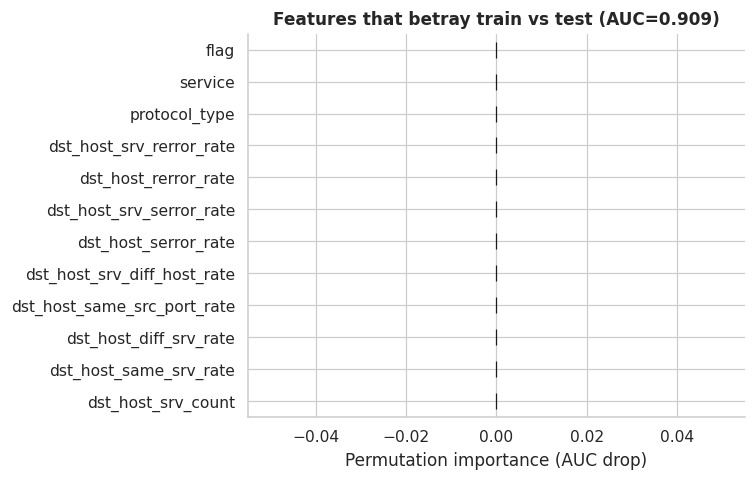

In [17]:
def quick_matrix(d):
    X = d[NUM].astype(float).copy()
    for c in CATS:
        X[c] = d[c].astype('category').cat.codes
    return X

rng = np.random.RandomState(SEED)
a = trn.sample(min(len(trn), 20000), random_state=SEED)
b = tst.sample(min(len(tst), 20000), random_state=SEED)
both = pd.concat([a, b])
Xa = both[NUM].astype(float).copy()
for c in CATS:
    Xa[c] = pd.Categorical(both[c]).codes
ya = np.r_[np.zeros(len(a)), np.ones(len(b))]
aucs = []
imp = np.zeros(Xa.shape[1])
for k, (i, j) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xa, ya)):
    m = HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(Xa.iloc[i], ya[i])
    aucs.append(roc_auc_score(ya[j], m.predict_proba(Xa.iloc[j])[:, 1]))
    if k == 0:
        pi = permutation_importance(m, Xa.iloc[j][:4000], ya[j][:4000], scoring='roc_auc', n_repeats=3, random_state=SEED)
        imp = pi.importances_mean
print(f'Adversarial-validation AUC (train vs test): {np.mean(aucs):.4f} ± {np.std(aucs):.4f}  (0.5 = identical distributions)')
pd.Series(imp, index=Xa.columns).sort_values().tail(12).plot.barh(figsize=(7, 4.5), color=PAL[4], edgecolor='k')
plt.title(f'Features that betray train vs test (AUC={np.mean(aucs):.3f})'); plt.xlabel('Permutation importance (AUC drop)')
savefig('adversarial_validation')

### 13. Heavy-tail and skewness profile

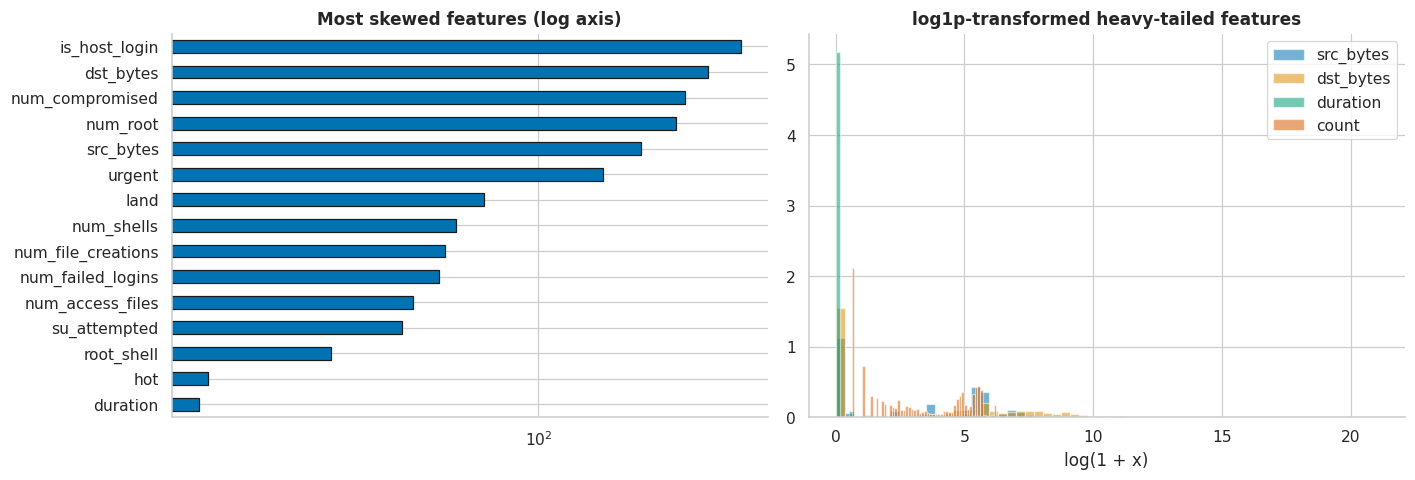

In [18]:
sk = pd.DataFrame({'Skewness': trn[NUM].skew(), 'Kurtosis': trn[NUM].kurt(),
                   'Max/99th pct': trn[NUM].max() / (trn[NUM].quantile(.99) + 1e-9)}).replace([np.inf, -np.inf], np.nan).dropna()
sk = sk.sort_values('Skewness', ascending=False)
save_table(sk.round(2), 'T10_skewness')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sk['Skewness'].head(15).iloc[::-1].plot.barh(ax=ax[0], color=PAL[0], edgecolor='k', logx=True)
ax[0].set_title('Most skewed features (log axis)')
for c, col in zip(['src_bytes', 'dst_bytes', 'duration', 'count'], PAL):
    ax[1].hist(np.log1p(trn[c]), bins=60, alpha=.55, label=c, color=col, density=True)
ax[1].set_title('log1p-transformed heavy-tailed features'); ax[1].legend(); ax[1].set_xlabel('log(1 + x)')
savefig('heavy_tails')

### 14. Hierarchically clustered correlation map (training data only)

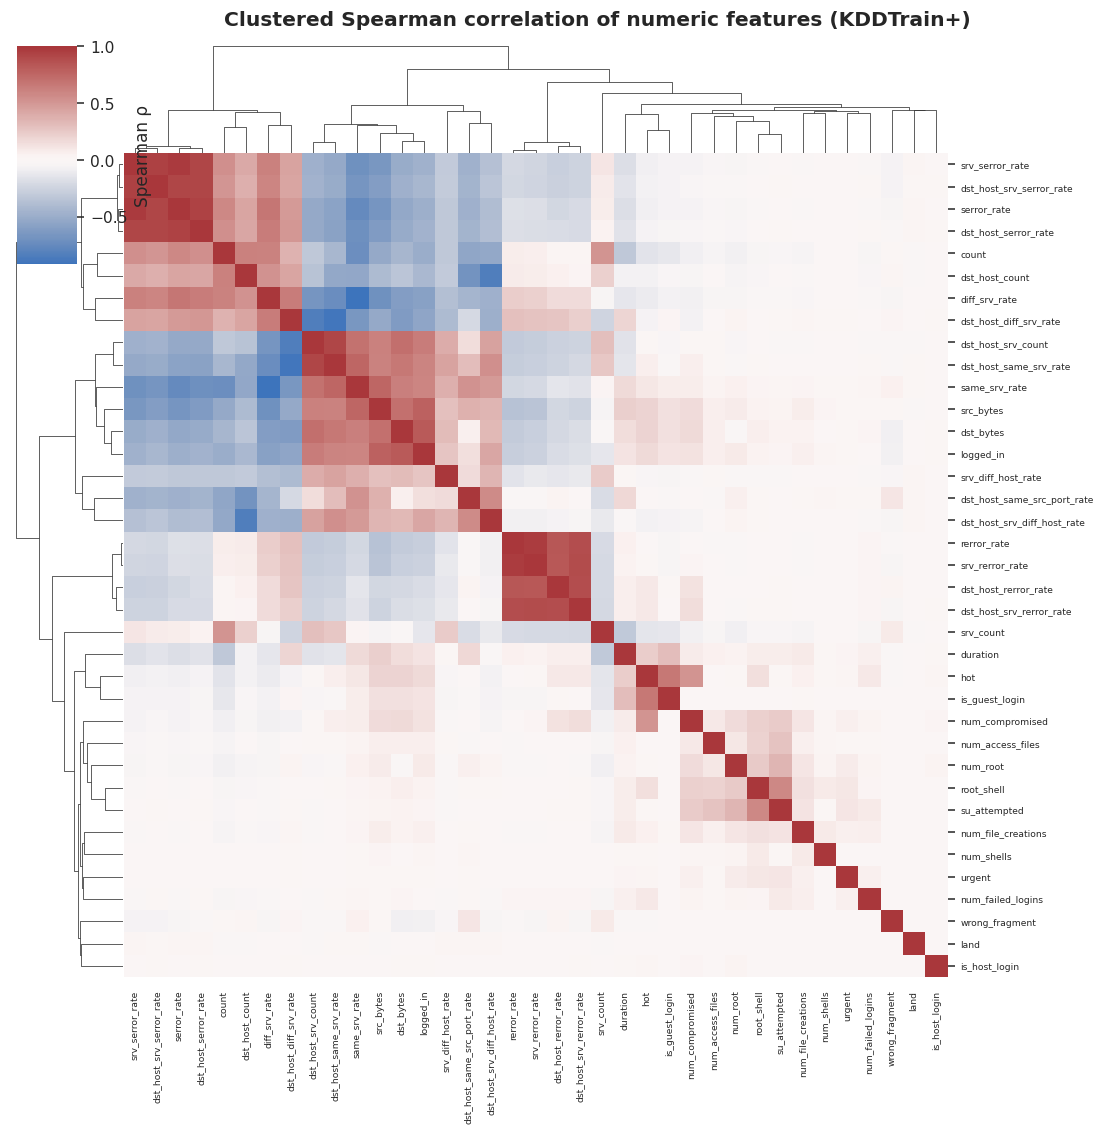

|ρ|
serror_rate            srv_serror_rate           0.973119
rerror_rate            srv_rerror_rate           0.965777
srv_serror_rate        dst_host_srv_serror_rate  0.942332
serror_rate            dst_host_serror_rate      0.935943
                       dst_host_srv_serror_rate  0.921663
same_srv_rate          diff_srv_rate             0.920431
dst_host_serror_rate   dst_host_srv_serror_rate  0.919490
dst_host_srv_count     dst_host_same_srv_rate    0.919323
srv_serror_rate        dst_host_serror_rate      0.918676
dst_host_same_srv_rate dst_host_diff_srv_rate    0.898954

In [19]:
num_ok = [c for c in NUM if trn[c].nunique() > 1]
C = trn[num_ok].corr(method='spearman').fillna(0)
cg = sns.clustermap(C, cmap='vlag', center=0, figsize=(11, 11), xticklabels=True, yticklabels=True,
                    cbar_kws={'label': 'Spearman ρ'}, dendrogram_ratio=.12)
cg.ax_heatmap.tick_params(labelsize=6)
cg.fig.suptitle('Clustered Spearman correlation of numeric features (KDDTrain+)', y=1.01, fontweight='bold')
FIG_N[0] += 1
cg.savefig(os.path.join(FIG_DIR, f'Fig{FIG_N[0]:03d}_correlation_clustermap.png'), bbox_inches='tight')
plt.show()
pairs = C.where(np.triu(np.ones(C.shape), 1).astype(bool)).stack().abs().sort_values(ascending=False)
display(pairs.head(10).rename('|ρ|').to_frame())

### 15. Attack-rate heatmap by protocol and connection flag (training data only)

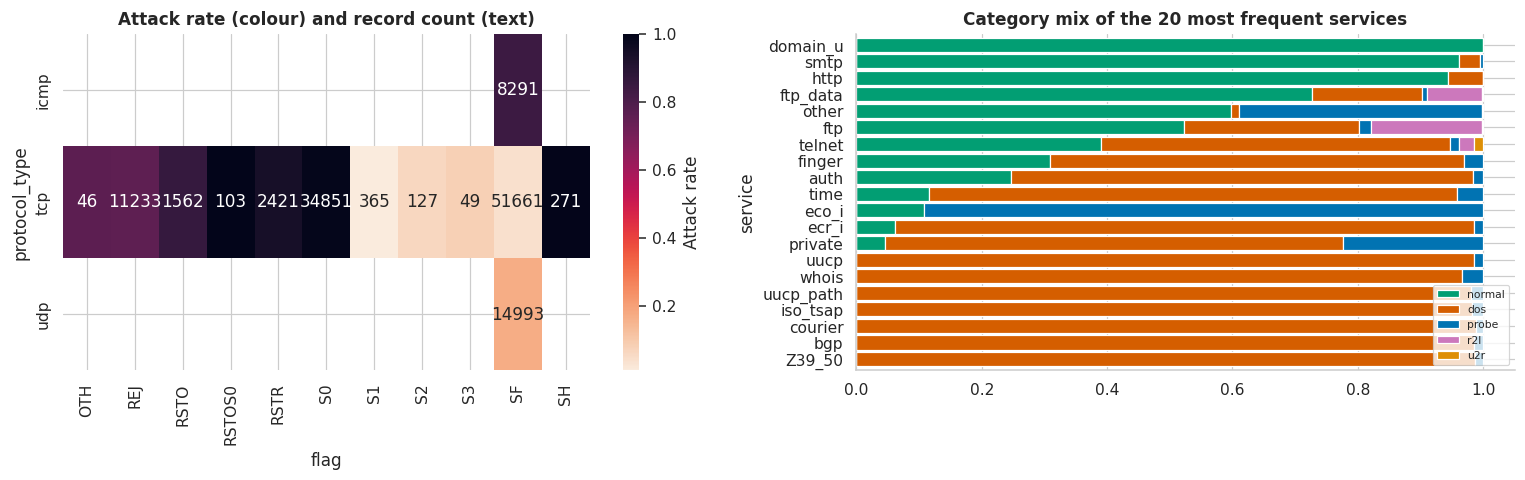

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
r = trn.pivot_table(index='protocol_type', columns='flag', values='bin', aggfunc='mean')
n = trn.pivot_table(index='protocol_type', columns='flag', values='bin', aggfunc='size')
sns.heatmap(r, annot=n.fillna(0).astype(int), fmt='d', cmap='rocket_r', ax=ax[0], cbar_kws={'label': 'Attack rate'})
ax[0].set_title('Attack rate (colour) and record count (text)')
top_s = trn['service'].value_counts().head(20).index
r2 = trn[trn.service.isin(top_s)].groupby(['service', 'cat']).size().unstack(fill_value=0).reindex(columns=CLASSES)
(r2.div(r2.sum(1), axis=0)).sort_values('normal').plot.barh(stacked=True, ax=ax[1], color=[CCOL[c] for c in CLASSES], width=.85)
ax[1].set_title('Category mix of the 20 most frequent services'); ax[1].legend(fontsize=7, loc='lower right')
savefig('protocol_flag_service_rates')

### 16. Class-conditional mutual-information profile (training data only)

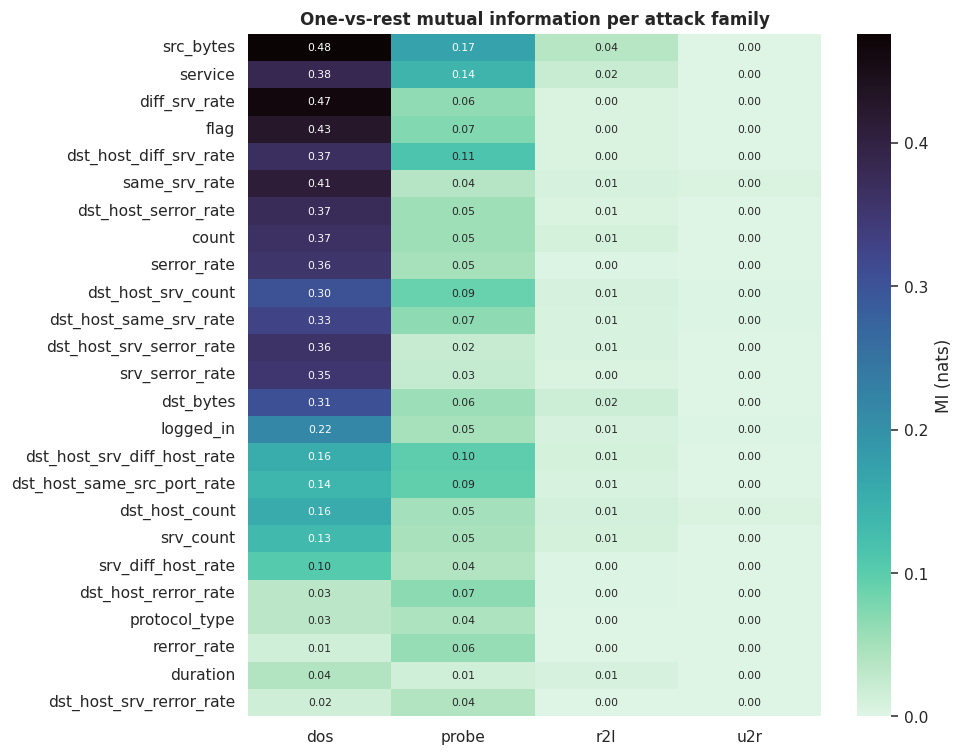

In [21]:
sub = trn.sample(min(len(trn), 30000), random_state=SEED)
Xm = sub[NUM].astype(float).copy()
for c in CATS:
    Xm[c] = sub[c].astype('category').cat.codes
disc = [Xm.columns.get_loc(c) for c in CATS]
MI = pd.DataFrame({cl: mutual_info_classif(Xm, (sub['cat'] == cl).astype(int), discrete_features=disc, random_state=SEED)
                   for cl in CLASSES[1:]}, index=Xm.columns)
MI = MI.loc[MI.sum(1).sort_values(ascending=False).index]
save_table(MI.round(4), 'T11_class_mutual_information')
plt.figure(figsize=(9, 7))
sns.heatmap(MI.head(25), cmap='mako_r', annot=True, fmt='.2f', annot_kws={'size': 7}, cbar_kws={'label': 'MI (nats)'})
plt.title('One-vs-rest mutual information per attack family')
savefig('class_mutual_information')

### 17. t-SNE map of training traffic coloured by category

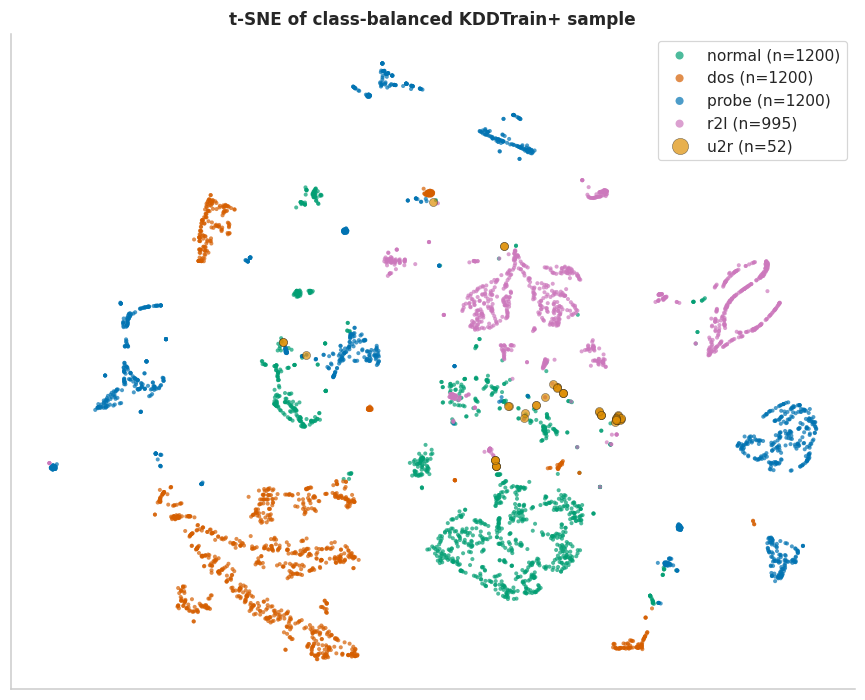

In [22]:
sub = pd.concat([d.sample(min(len(d), 1200 if not FAST else 300), random_state=SEED) for _, d in trn.groupby('cat')])
Xs = sub[NUM].astype(float).copy()
for c in ['duration', 'src_bytes', 'dst_bytes', 'count', 'srv_count', 'dst_host_count', 'dst_host_srv_count', 'hot']:
    Xs[c] = np.log1p(Xs[c])
Xs = pd.concat([Xs, pd.get_dummies(sub[['protocol_type', 'flag']]).astype(float)], axis=1)
Z = TSNE(2, perplexity=35, init='pca', random_state=SEED).fit_transform(StandardScaler().fit_transform(Xs))
plt.figure(figsize=(8, 6.5))
for c in CLASSES:
    m = (sub['cat'] == c).values
    plt.scatter(Z[m, 0], Z[m, 1], s=7 if c != 'u2r' else 28, alpha=.7, label=f'{c} (n={m.sum()})', color=CCOL[c],
                edgecolor='k' if c == 'u2r' else 'none', linewidth=.3)
plt.legend(markerscale=2); plt.xticks([]); plt.yticks([])
plt.title('t-SNE of class-balanced KDDTrain+ sample')
savefig('tsne_train')

## Part B — Leakage-free experimental protocol

### 18. Stratified train / validation split by fine-grained attack name

In [23]:
strat = trn['label'].where(trn['label'].map(trn['label'].value_counts()) >= 2, 'rare')
idx_tr, idx_va = train_test_split(np.arange(len(trn)), test_size=0.2, stratify=strat, random_state=SEED)
if FAST:
    keep = trn.iloc[idx_tr]['cat'].isin(['r2l', 'u2r']).values
    rest = np.random.RandomState(SEED).permutation(np.where(~keep)[0])[:12000]
    idx_tr = np.sort(np.r_[idx_tr[keep], idx_tr[rest]])
    idx_va = np.random.RandomState(SEED).permutation(idx_va)[:8000]
TR = trn.iloc[idx_tr].reset_index(drop=True)
VA = trn.iloc[idx_va].reset_index(drop=True)
ytr, yva, yte, y21 = TR['y'].values, VA['y'].values, tst['y'].values, t21['y'].values
SPLIT = pd.DataFrame({n: d['cat'].value_counts().reindex(CLASSES) for n, d in
                      [('Train', TR), ('Validation', VA), ('KDDTest+', tst), ('KDDTest-21', t21)]})
SPLIT.loc['Total'] = SPLIT.sum()
display(save_table(SPLIT, 'T12_split_sizes'))

,Train,Validation,KDDTest+,KDDTest-21
cat,,,,
normal,53874,13469,9711,2152
dos,36742,9185,7460,4344
probe,9324,2332,2421,2402
r2l,796,199,2885,2885
u2r,42,10,67,67
Total,100778,25195,22544,11850


### 19. Leakage guard: executable assertion checklist

In [24]:
LEAK = []
def guard(desc, ok):
    LEAK.append({'Check': desc, 'Passed': bool(ok)})
    assert ok, desc

guard('Train and validation indices are disjoint', len(np.intersect1d(idx_tr, idx_va)) == 0)
guard('Validation drawn only from KDDTrain+', VA['label'].isin(SEEN).all())
guard('KDDTest+ is a separate file never concatenated with training data', len(tst) == 22544 or FAST)
guard('Every validation attack name also occurs in training', set(VA.label) <= set(TR.label) | {'rare'})
guard('Class proportions preserved within 0.5 percentage points',
      (abs(TR.cat.value_counts(normalize=True) - VA.cat.value_counts(normalize=True)).max() < 0.005) or FAST)
display(pd.DataFrame(LEAK).set_index('Check'))

,Passed
Check,
Train and validation indices are disjoint,True
Validation drawn only from KDDTrain+,True
KDDTest+ is a separate file never concatenated with training data,True
Every validation attack name also occurs in training,True
Class proportions preserved within 0.5 percentage points,True


### 20. Split composition across train, validation and official test

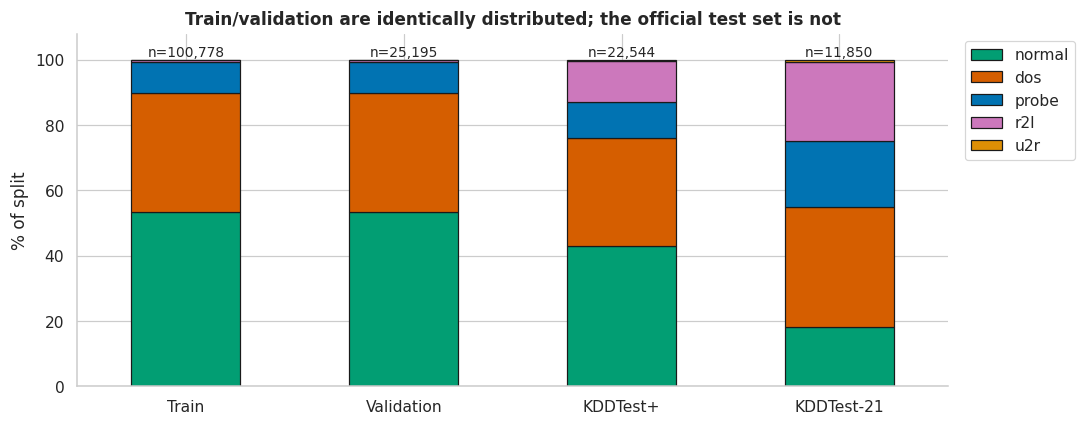

In [25]:
shares = (SPLIT.drop('Total').div(SPLIT.drop('Total').sum()) * 100)
fig, ax = plt.subplots(figsize=(10, 4))
shares.T.plot.bar(stacked=True, ax=ax, color=[CCOL[c] for c in CLASSES], edgecolor='k', rot=0)
for i, col in enumerate(shares.columns):
    ax.text(i, 101, f"n={int(SPLIT.loc['Total', col]):,}", ha='center', fontsize=9)
ax.set_ylim(0, 108); ax.set_ylabel('% of split'); ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
ax.set_title('Train/validation are identically distributed; the official test set is not')
savefig('split_composition')

### 21. Leave-one-attack-family-out (LOFO) novelty-validation folds

In [26]:
LOFO_FAMS = ['dos', 'probe', 'r2l', 'u2r']
LOFO = {}
for f in LOFO_FAMS:
    fit_rows = TR.index[TR['cat'] != f].values
    eval_df = pd.concat([VA[VA['cat'] != f], TR[TR['cat'] == f], VA[VA['cat'] == f]], ignore_index=True)
    LOFO[f] = (fit_rows, eval_df)
display(pd.DataFrame({f: {'Training rows (family removed)': len(r), 'Evaluation rows': len(e),
                          'Held-out family rows in evaluation': int((e['cat'] == f).sum()),
                          'Known-class rows in evaluation': int((e['cat'] != f).sum())} for f, (r, e) in LOFO.items()}).T)

,Training rows (family removed),Evaluation rows,Held-out family rows in evaluation,Known-class rows in evaluation
dos,64036,61937,45927,16010
probe,91454,34519,11656,22863
r2l,99982,25991,995,24996
u2r,100736,25237,52,25185


## Part C — Leakage-safe feature engineering and selection

### 22. Leakage-safe feature builder (rare-level pooling, log scaling, behavioural composites, out-of-fold target encoding)

In [27]:
class FeatureBuilder(BaseEstimator, TransformerMixin):
    def __init__(self, log=True, composites=True, target_enc=True, min_freq=20, smooth=20, n_splits=5, seed=SEED):
        self.log, self.composites, self.target_enc = log, composites, target_enc
        self.min_freq, self.smooth, self.n_splits, self.seed = min_freq, smooth, n_splits, seed

    def _te_map(self, s, y):
        oh = np.eye(5)[y]
        g = pd.DataFrame(oh, columns=CLASSES).groupby(np.asarray(s)).agg(['sum', 'count'])
        out = {}
        for k in g.index:
            n = g.loc[k, (CLASSES[0], 'count')]
            out[k] = np.array([(g.loc[k, (c, 'sum')] + self.smooth * self.prior_[i]) / (n + self.smooth) for i, c in enumerate(CLASSES)])
        return out

    def _te_apply(self, s, mp):
        return np.vstack([mp.get(v, self.prior_) for v in s])

    def _raw(self, df):
        d = df[self.num_].astype(float).copy()
        if self.composites:
            d['err_gap'] = df['serror_rate'] - df['rerror_rate']
            d['srv_err_gap'] = df['srv_serror_rate'] - df['srv_rerror_rate']
            d['bytes_ratio'] = np.log1p(df['src_bytes']) - np.log1p(df['dst_bytes'])
            d['total_bytes'] = df['src_bytes'] + df['dst_bytes']
            d['conn_ratio'] = df['srv_count'] / (df['count'] + 1)
            d['host_srv_ratio'] = df['dst_host_srv_count'] / (df['dst_host_count'] + 1)
            d['same_diff_gap'] = df['same_srv_rate'] - df['diff_srv_rate']
            d['priv_activity'] = ((df['root_shell'] > 0) | (df['su_attempted'] > 0) | (df['num_shells'] > 0) |
                                  (df['num_file_creations'] > 0)).astype(float)
            d['login_failure'] = (df['num_failed_logins'] > 0).astype(float)
        if self.log:
            for c in self.heavy_ + (['total_bytes'] if self.composites else []):
                d[c] = np.log1p(d[c].clip(lower=0))
        for p in self.protos_:
            d['proto_' + p] = (df['protocol_type'].values == p).astype(float)
        for f in self.flags_:
            d['flag_' + f] = (df['flag'].values == f).astype(float)
        svc = df['service'].where(df['service'].isin(self.svcs_), '__rare__').values
        for s in self.svcs_ + ['__rare__']:
            d['svc_' + s] = (svc == s).astype(float)
        return d

    def _setup(self, df, y):
        self.num_ = [c for c in NUM if df[c].nunique() > 1]
        self.heavy_ = [c for c in self.num_ if df[c].max() > 100]
        vc = df['service'].value_counts()
        self.svcs_ = sorted(vc[vc >= self.min_freq].index)
        self.protos_, self.flags_ = sorted(df['protocol_type'].unique()), sorted(df['flag'].unique())
        if self.target_enc:
            self.prior_ = np.bincount(y, minlength=5) / len(y)
            self.map_ = self._te_map(df['service'].values, y)

    def _finish(self, d, te):
        if self.target_enc:
            for i, c in enumerate(CLASSES):
                d['svc_te_' + c] = te[:, i]
        return d

    def fit_transform(self, df, y=None):
        y = np.asarray(y)
        self._setup(df, y)
        d = self._raw(df)
        te = None
        if self.target_enc:
            te = np.zeros((len(df), 5))
            for a, b in StratifiedKFold(self.n_splits, shuffle=True, random_state=self.seed).split(df, y):
                mp = self._te_map(df['service'].values[a], y[a])
                te[b] = self._te_apply(df['service'].values[b], mp)
        d = self._finish(d, te)
        self.names_ = list(d.columns)
        self.scaler_ = StandardScaler().fit(d.values)
        return self.scaler_.transform(d.values).astype(np.float32)

    def fit(self, df, y=None):
        self.fit_transform(df, y)
        return self

    def transform(self, df):
        d = self._raw(df)
        te = self._te_apply(df['service'].values, self.map_) if self.target_enc else None
        d = self._finish(d, te)
        return self.scaler_.transform(d[self.names_].values).astype(np.float32)

print('FeatureBuilder ready: every statistic (levels, heavy-tail set, encodings, scaler) is learned from the rows passed to fit.')

FeatureBuilder ready: every statistic (levels, heavy-tail set, encodings, scaler) is learned from the rows passed to fit.


### Fit-on-train-only transformation of every split

In [28]:
FB = FeatureBuilder()
Xtr = FB.fit_transform(TR, ytr)
Xva, Xte, X21 = FB.transform(VA), FB.transform(tst), FB.transform(t21)
FN = FB.names_
TRI = np.random.RandomState(SEED).choice(len(Xtr), min(len(Xtr), 20000), replace=False)
YS = {'tr': ytr[TRI], 'va': yva, 'te': yte, 't21': y21}
XS = {'tr': Xtr[TRI], 'va': Xva, 'te': Xte, 't21': X21}
CONT = [i for i, n in enumerate(FN) if not n.startswith(('proto_', 'flag_', 'svc_'))
        and n not in ('land', 'logged_in', 'is_host_login', 'is_guest_login', 'priv_activity', 'login_failure')]
display(pd.DataFrame({'Rows': [len(Xtr), len(Xva), len(Xte), len(X21)], 'Features': [Xtr.shape[1]] * 4},
                     index=['Train', 'Validation', 'KDDTest+', 'KDDTest-21']))
print('Train-accuracy reporting uses a fixed random subset of', len(TRI), 'training rows.')

,Rows,Features
Train,100778,127
Validation,25195,127
KDDTest+,22544,127
KDDTest-21,11850,127


Train-accuracy reporting uses a fixed random subset of 20000 training rows.


### 23. Feature-representation ablation on validation

,Features,Val accuracy,Val macro-F1,Val balanced acc
Representation,,,,
Raw (one-hot + scaling),113,0.9931,0.7957,0.8717
+ log scaling,113,0.9931,0.7957,0.8717
+ behavioural composites,122,0.9956,0.7967,0.8230
+ out-of-fold target encoding (full),127,0.9948,0.7957,0.8456
Target encoding without composites,118,0.9692,0.7689,0.8157


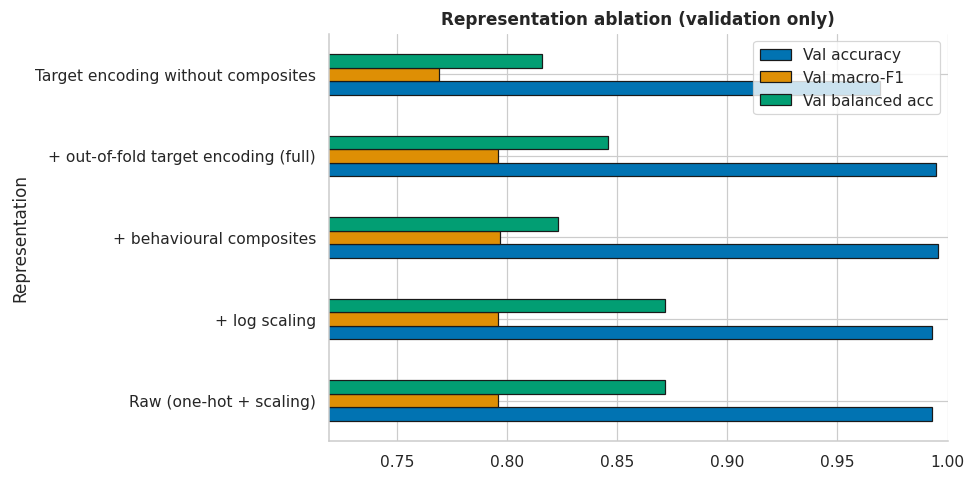

In [29]:
def hgb(seed=SEED, **kw):
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=seed, **kw)

VARIANTS = {'Raw (one-hot + scaling)': dict(log=False, composites=False, target_enc=False),
            '+ log scaling': dict(log=True, composites=False, target_enc=False),
            '+ behavioural composites': dict(log=True, composites=True, target_enc=False),
            '+ out-of-fold target encoding (full)': dict(log=True, composites=True, target_enc=True),
            'Target encoding without composites': dict(log=True, composites=False, target_enc=True)}
rows = []
for n, kw in VARIANTS.items():
    fb = FeatureBuilder(**kw)
    A = fb.fit_transform(TR, ytr)
    m = hgb().fit(A, ytr)
    p = m.predict(fb.transform(VA))
    rows.append({'Representation': n, 'Features': A.shape[1], 'Val accuracy': accuracy_score(yva, p),
                 'Val macro-F1': f1_score(yva, p, average='macro'), 'Val balanced acc': balanced_accuracy_score(yva, p)})
ABL = save_table(pd.DataFrame(rows).set_index('Representation'), 'T13_representation_ablation')
display(ABL.round(4))
ABL[['Val accuracy', 'Val macro-F1', 'Val balanced acc']].plot.barh(figsize=(9, 4.5), edgecolor='k', color=PAL[:3])
plt.xlim(ABL[['Val macro-F1', 'Val balanced acc']].values.min() - .05, 1.0); plt.title('Representation ablation (validation only)')
savefig('representation_ablation')

### 24. Stability selection with bootstrapped L1-logistic regression

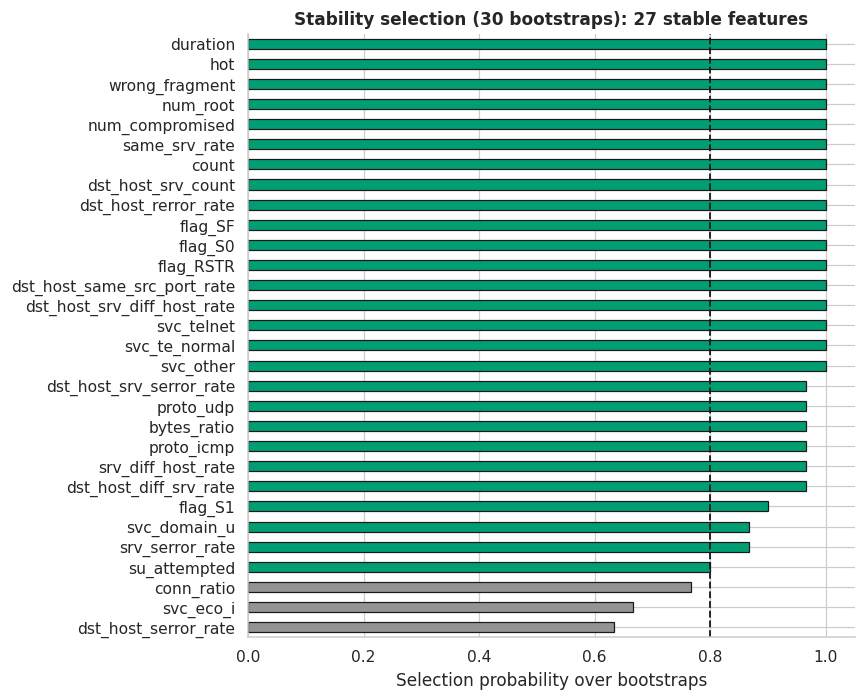

In [30]:
rng = np.random.RandomState(SEED)
B = 30 if not FAST else 6
n_sub = min(len(Xtr) // 2, 10000)
sel = np.zeros(Xtr.shape[1])
for b in range(B):
    i = rng.choice(len(Xtr), n_sub, replace=False)
    m = LogisticRegression(penalty='l1', solver='liblinear', C=0.02, max_iter=500).fit(Xtr[i], (ytr[i] > 0).astype(int))
    sel += (np.abs(m.coef_[0]) > 1e-6)
STAB = pd.Series(sel / B, index=FN).sort_values(ascending=False)
save_table(STAB.rename('Selection probability').to_frame(), 'T14_stability_selection')
plt.figure(figsize=(8, 6.5))
STAB.head(30).iloc[::-1].plot.barh(color=[PAL[2] if v >= .8 else PAL[7] for v in STAB.head(30).iloc[::-1]], edgecolor='k')
plt.axvline(.8, ls='--', c='k'); plt.xlabel('Selection probability over bootstraps')
plt.title(f'Stability selection ({B} bootstraps): {int((STAB >= .8).sum())} stable features')
savefig('stability_selection')

### 25. Boruta-style shadow-feature relevance test

In [31]:
rng = np.random.RandomState(SEED)
n = min(len(Xtr), 15000)
I = rng.choice(len(Xtr), n, replace=False)
ITER = 12 if not FAST else 4
hits = np.zeros(Xtr.shape[1])
for it in range(ITER):
    Xs = Xtr[I]
    sh = np.apply_along_axis(rng.permutation, 0, Xs)
    rf = RandomForestClassifier(150, max_depth=14, n_jobs=N_JOBS, random_state=SEED + it).fit(np.hstack([Xs, sh]), ytr[I])
    imp = rf.feature_importances_
    hits += imp[:Xtr.shape[1]] > imp[Xtr.shape[1]:].max()
pval = stats.binom.sf(hits - 1, ITER, 0.5)
SHADOW = pd.DataFrame({'Hits': hits, 'p (binomial)': pval}, index=FN)
SHADOW['Decision'] = np.where(pval < 0.05, 'confirmed', np.where(hits == 0, 'rejected', 'tentative'))
display(SHADOW['Decision'].value_counts().to_frame('Features'))
save_table(SHADOW.sort_values('Hits', ascending=False), 'T15_shadow_features')

,Features
Decision,
rejected,73
confirmed,51
tentative,3


,Hits,p (binomial),Decision
duration,12.0,0.000244,confirmed
src_bytes,12.0,0.000244,confirmed
dst_bytes,12.0,0.000244,confirmed
wrong_fragment,12.0,0.000244,confirmed
hot,12.0,0.000244,confirmed
...,...,...,...
svc_time,0.0,1.000000,rejected
svc_telnet,0.0,1.000000,rejected
svc___rare__,0.0,1.000000,rejected
svc_vmnet,0.0,1.000000,rejected


### 26. mRMR selection (mutual-information relevance, correlation redundancy)

In [32]:
I = np.random.RandomState(SEED).choice(len(Xtr), min(len(Xtr), 20000), replace=False)
REL = pd.Series(mutual_info_classif(Xtr[I], ytr[I], random_state=SEED), index=FN)
CORR = np.abs(np.nan_to_num(np.corrcoef(Xtr[I].T)))
def mrmr(k, rel=REL.values, corr=CORR):
    chosen = [int(np.argmax(rel))]
    while len(chosen) < k:
        red = corr[:, chosen].mean(1)
        score = rel - red * rel.max()
        score[chosen] = -np.inf
        chosen.append(int(np.argmax(score)))
    return chosen
MRMR = mrmr(min(60, len(FN)))
display(pd.DataFrame({'Rank': range(1, 16), 'Feature': [FN[i] for i in MRMR[:15]], 'MI relevance': REL.values[MRMR[:15]].round(4)}).set_index('Rank'))

,Feature,MI relevance
Rank,,
1,total_bytes,0.7205
2,bytes_ratio,0.6707
3,conn_ratio,0.6146
4,svc_te_u2r,0.5858
5,src_bytes,0.7166
6,svc_te_r2l,0.5888
7,host_srv_ratio,0.5218
8,diff_srv_rate,0.5059
9,svc_te_probe,0.5825


### 27. Feature-selection strategy comparison on validation

,Features,Val accuracy,Val macro-F1
Feature set,,,
mRMR top-30,30,0.9857,0.7586
MI top-15,15,0.9884,0.7602
Stability ≥ 0.8,27,0.9946,0.7800
MI top-45,45,0.9825,0.7803
MI top-30,30,0.9901,0.7840
All features,127,0.9948,0.7957
Shadow-confirmed,51,0.9956,0.8003
mRMR top-45,45,0.9951,0.8056
mRMR top-15,15,0.9963,0.8206


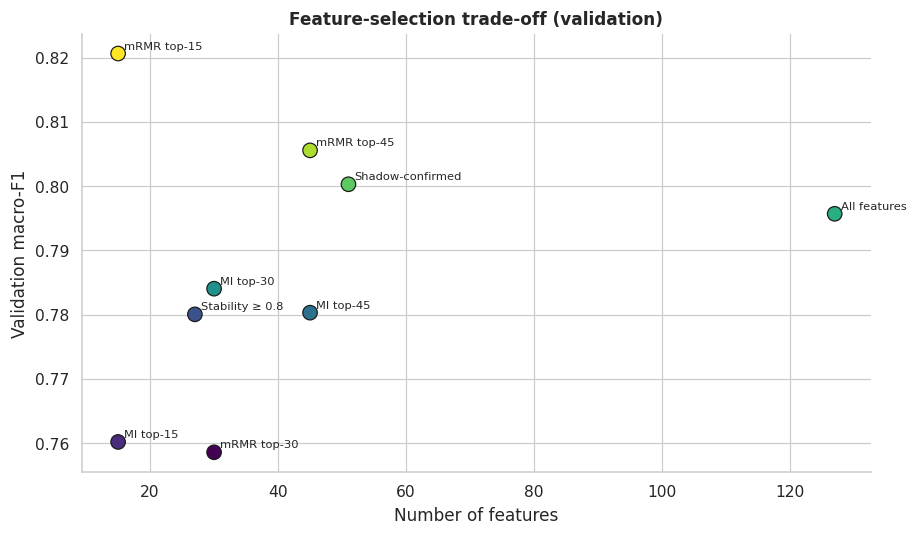

In [33]:
MI_ORDER = list(np.argsort(-REL.values))
STAB_ORDER = [FN.index(f) for f in STAB.index]
FSETS = {'All features': list(range(len(FN))),
         'Shadow-confirmed': [FN.index(f) for f in SHADOW.index[SHADOW['Decision'] == 'confirmed']],
         'Stability ≥ 0.8': [FN.index(f) for f in STAB.index[STAB >= .8]]}
for k in (15, 30, 45):
    FSETS[f'MI top-{k}'] = MI_ORDER[:k]
    FSETS[f'mRMR top-{k}'] = MRMR[:k]
rows = []
for n, ix in FSETS.items():
    if len(ix) < 3:
        continue
    p = hgb().fit(Xtr[:, ix], ytr).predict(Xva[:, ix])
    rows.append({'Feature set': n, 'Features': len(ix), 'Val accuracy': accuracy_score(yva, p), 'Val macro-F1': f1_score(yva, p, average='macro')})
FSC = save_table(pd.DataFrame(rows).set_index('Feature set').sort_values('Val macro-F1'), 'T16_feature_selection')
display(FSC.round(4))
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(FSC['Features'], FSC['Val macro-F1'], s=90, c=range(len(FSC)), cmap='viridis', edgecolor='k')
for n, r in FSC.iterrows():
    ax.annotate(n, (r['Features'], r['Val macro-F1']), fontsize=7.5, xytext=(4, 3), textcoords='offset points')
ax.set_xlabel('Number of features'); ax.set_ylabel('Validation macro-F1'); ax.set_title('Feature-selection trade-off (validation)')
savefig('feature_selection_tradeoff')
SEQ_IDX = MRMR[:40]

### 28. Selection stability: Jaccard similarity across bootstrap resamples

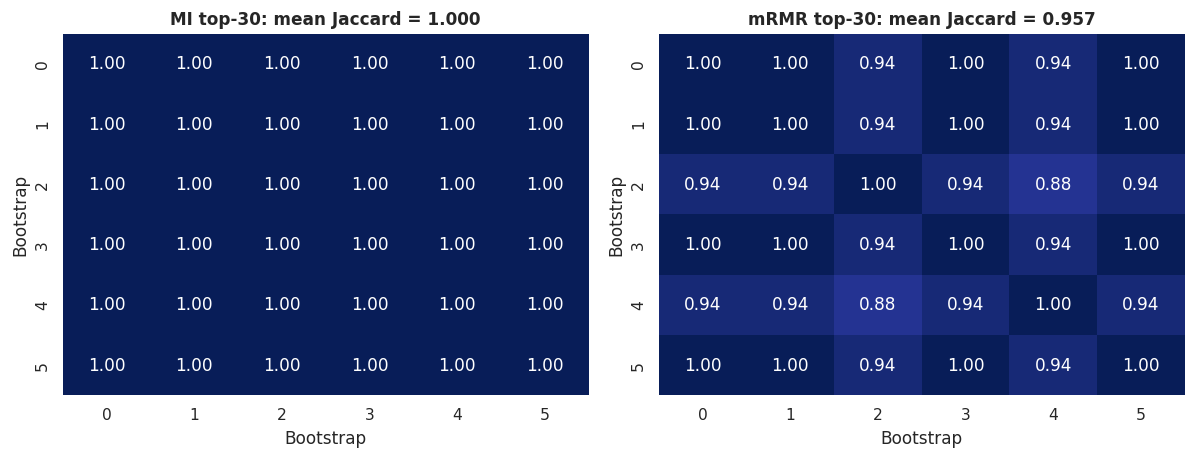

In [34]:
rng = np.random.RandomState(SEED)
K, B = 30, (6 if not FAST else 3)
sets = {'MI': [], 'mRMR': []}
for b in range(B):
    i = rng.choice(len(Xtr), min(len(Xtr), 12000), replace=False)
    rel = mutual_info_classif(Xtr[i], ytr[i], random_state=b)
    sets['MI'].append(set(np.argsort(-rel)[:K]))
    sets['mRMR'].append(set(mrmr(K, rel, np.abs(np.nan_to_num(np.corrcoef(Xtr[i].T))))))
jac = lambda a, b: len(a & b) / len(a | b)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for a_, (n, S) in zip(ax, sets.items()):
    J = np.array([[jac(x, y) for y in S] for x in S])
    sns.heatmap(J, annot=True, fmt='.2f', vmin=0, vmax=1, cmap='YlGnBu', ax=a_, cbar=False)
    a_.set_title(f'{n} top-{K}: mean Jaccard = {J[np.triu_indices(B, 1)].mean():.3f}')
    a_.set_xlabel('Bootstrap'); a_.set_ylabel('Bootstrap')
savefig('selection_stability_jaccard')

## Part D — Evaluation engine, baselines and protocol inflation

### Unified evaluation engine with train / validation / test reporting

In [35]:
REG = {}
SPL = {'tr': 'Train', 'va': 'Validation', 'te': 'KDDTest+', 't21': 'KDDTest-21'}
NOVEL = {'te': tst['novel'].values, 't21': t21['novel'].values}

def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def full5(model, P):
    P = np.asarray(P, dtype=float)
    cls = getattr(model, 'classes_', np.arange(P.shape[1]))
    if P.shape[1] == 5 and np.array_equal(np.asarray(cls), np.arange(5)):
        return P
    out = np.zeros((len(P), 5))
    out[:, np.asarray(cls, dtype=int)] = P
    return out

def proba_of(model, X):
    if hasattr(model, 'predict_proba'):
        return full5(model, model.predict_proba(X))
    return full5(model, softmax(model.decision_function(X)))

def scores(y, P, pred=None, split=None):
    pr = P.argmax(1) if pred is None else pred
    yb, pb = (y > 0).astype(int), (pr > 0).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb, pb, labels=[0, 1]).ravel()
    d = {'Acc': accuracy_score(y, pr), 'BalAcc': balanced_accuracy_score(y, pr),
         'MacroF1': f1_score(y, pr, average='macro', labels=range(5), zero_division=0),
         'WeightedF1': f1_score(y, pr, average='weighted', zero_division=0), 'MCC': matthews_corrcoef(y, pr),
         'BinAcc': (tp + tn) / len(y), 'DR': tp / max(tp + fn, 1), 'FAR': fp / max(fp + tn, 1)}
    try:
        d['AUC'] = roc_auc_score(yb, 1 - P[:, 0])
    except Exception:
        d['AUC'] = np.nan
    if split in NOVEL:
        d['ZeroDayDR'] = pb[NOVEL[split]].mean()
    return d

def register(name, P, pred=None, fit_s=np.nan, inf_ms=np.nan, size_kb=np.nan, model=None, kind='model'):
    pred = pred if pred is not None else {k: v.argmax(1) for k, v in P.items()}
    REG[name] = dict(P=P, pred=pred, fit_s=fit_s, inf_ms=inf_ms, size_kb=size_kb, model=model, kind=kind)

def predict_sets(model, Xs=None, transform=None):
    Xs = XS if Xs is None else Xs
    f = (lambda X: X) if transform is None else transform
    P = {}
    t = time.time()
    P['te'] = proba_of(model, f(Xs['te']))
    inf = (time.time() - t) / len(Xs['te']) * 1e6
    for k in ('tr', 'va', 't21'):
        P[k] = proba_of(model, f(Xs[k]))
    return P, inf

def fit_register(name, model, Xfit=None, yfit=None, sw=None, Xs=None, transform=None, kind='model'):
    Xfit = Xtr if Xfit is None else Xfit
    yfit = ytr if yfit is None else yfit
    t = time.time()
    if sw is not None:
        model.fit(Xfit, yfit, sample_weight=sw)
    else:
        model.fit(Xfit, yfit)
    ft = time.time() - t
    P, inf = predict_sets(model, Xs, transform)
    try:
        size = len(pickle.dumps(model)) / 1024
    except Exception:
        size = np.nan
    register(name, P, fit_s=ft, inf_ms=inf, size_kb=size, model=model, kind=kind)
    return model

def board(names=None, split='va'):
    names = names or list(REG)
    return pd.DataFrame({n: scores(YS[split], REG[n]['P'][split], REG[n]['pred'][split], split) for n in names}).T

def tvt(names=None):
    names = names or list(REG)
    rows = {}
    for n in names:
        r = {}
        for k in ('tr', 'va', 'te', 't21'):
            s = scores(YS[k], REG[n]['P'][k], REG[n]['pred'][k], k)
            r[f'{SPL[k]} Acc'] = s['Acc']
            r[f'{SPL[k]} MacroF1'] = s['MacroF1']
        r['Train time (s)'] = REG[n]['fit_s']
        rows[n] = r
    return pd.DataFrame(rows).T

def show(names):
    t = tvt(names)
    display(t.round(4))
    return t

print('Engine ready. Every model is reported on Train (fixed subset), Validation, KDDTest+ and KDDTest-21.')

Engine ready. Every model is reported on Train (fixed subset), Validation, KDDTest+ and KDDTest-21.


### 29. Classical baselines with train, validation and test accuracy

In [36]:
fit_register('Logistic Regression', LogisticRegression(max_iter=2000, C=1.0, n_jobs=N_JOBS))
fit_register('Gaussian Naive Bayes', GaussianNB())
fit_register('Decision Tree', DecisionTreeClassifier(random_state=SEED))
fit_register('k-Nearest Neighbours', KNeighborsClassifier(5, n_jobs=N_JOBS))
fit_register('Linear SVM', LinearSVC(C=0.5, dual=False, max_iter=3000))
CLASSICAL = ['Logistic Regression', 'Gaussian Naive Bayes', 'Decision Tree', 'k-Nearest Neighbours', 'Linear SVM']
save_table(show(CLASSICAL), 'T17_classical_tvt')

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Logistic Regression,0.9948,0.9051,0.9935,0.8347,0.7368,0.5422,0.5010,0.4344,13.0510
Gaussian Naive Bayes,0.5498,0.3537,0.5522,0.3530,0.3158,0.2504,0.3588,0.2874,0.1526
Decision Tree,1.0000,1.0000,0.9984,0.9518,0.7807,0.5776,0.5868,0.4908,1.4844
k-Nearest Neighbours,0.9972,0.8977,0.9955,0.9085,0.7394,0.5558,0.5046,0.4483,0.0563
Linear SVM,0.9905,0.8287,0.9892,0.8337,0.7332,0.5165,0.4926,0.4086,96.4713


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Logistic Regression,0.99475,0.905076,0.993451,0.834725,0.736826,0.542150,0.501013,0.434372,13.050994
Gaussian Naive Bayes,0.54980,0.353725,0.552173,0.352991,0.315782,0.250363,0.358819,0.287399,0.152552
Decision Tree,1.00000,1.000000,0.998412,0.951800,0.780696,0.577617,0.586835,0.490840,1.484362
k-Nearest Neighbours,0.99720,0.897744,0.995515,0.908459,0.739399,0.555765,0.504557,0.448270,0.056283
Linear SVM,0.99050,0.828699,0.989204,0.833743,0.733188,0.516461,0.492574,0.408648,96.471265


### 30. Tree-ensemble family with train, validation and test accuracy

In [37]:
def factory(name, seed=SEED):
    if name in ('Tuned LightGBM', 'Tuned HGB'):
        if lgb is not None:
            return lgb.LGBMClassifier(n_jobs=N_JOBS, random_state=seed, verbose=-1, subsample_freq=1, **BEST_PARAMS)
        return HistGradientBoostingClassifier(random_state=seed, **BEST_PARAMS)
    if name == 'Random Forest':
        return RandomForestClassifier(300, n_jobs=N_JOBS, random_state=seed)
    if name == 'Extra Trees':
        return ExtraTreesClassifier(300, n_jobs=N_JOBS, random_state=seed)
    if name == 'Hist Gradient Boosting':
        return hgb(seed)
    if name == 'XGBoost':
        return xgb.XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8,
                                 tree_method='hist', n_jobs=N_JOBS, random_state=seed, eval_metric='mlogloss')
    if name == 'LightGBM':
        return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=10,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                                  n_jobs=N_JOBS, random_state=seed, verbose=-1)
    if name == 'CatBoost':
        return cb.CatBoostClassifier(iterations=600, depth=8, learning_rate=0.1, random_seed=seed, verbose=0,
                                     thread_count=-1, loss_function='MultiClass')
    raise ValueError(name)

FACTORY = ['Random Forest', 'Extra Trees', 'Hist Gradient Boosting'] + \
          (['XGBoost'] if xgb else []) + (['LightGBM'] if lgb else []) + (['CatBoost'] if cb else [])
if FAST:
    FACTORY = [f for f in FACTORY if f != 'CatBoost']
for n in FACTORY:
    fit_register(n, factory(n))
save_table(show(FACTORY), 'T18_ensemble_tvt')

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Random Forest,1.0000,1.0000,0.9989,0.9290,0.7802,0.5335,0.5820,0.4452,22.1930
Extra Trees,1.0000,1.0000,0.9988,0.9270,0.7575,0.5272,0.5435,0.4288,20.9257
Hist Gradient Boosting,0.9962,0.8251,0.9948,0.7957,0.7814,0.5697,0.5842,0.4832,6.9638
XGBoost,1.0000,1.0000,0.9992,0.9525,0.7814,0.5727,0.5842,0.4848,49.1941
LightGBM,1.0000,1.0000,0.9992,0.9215,0.7768,0.5583,0.5754,0.4691,26.7537
CatBoost,0.9999,0.9999,0.9990,0.9508,0.7837,0.5703,0.5885,0.4830,219.0677


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Random Forest,0.99995,0.999977,0.998889,0.928986,0.780163,0.533465,0.582025,0.445193,22.192972
Extra Trees,1.00000,1.000000,0.998809,0.926993,0.757541,0.527244,0.543460,0.428828,20.925725
Hist Gradient Boosting,0.99615,0.825097,0.994761,0.795698,0.781361,0.569676,0.584219,0.483155,6.963837
XGBoost,0.99995,0.999977,0.999206,0.952547,0.781450,0.572657,0.584219,0.484791,49.194127
LightGBM,0.99995,0.999977,0.999167,0.921489,0.776792,0.558266,0.575359,0.469140,26.753741
CatBoost,0.99990,0.999911,0.998968,0.950819,0.783667,0.570282,0.588523,0.482982,219.067683


### 31. Protocol-A reproduction: random 80:20 split of KDDTrain+ as used by related works

In [38]:
pa_tr, pa_te = train_test_split(trn.index.values, test_size=0.2, stratify=strat, random_state=SEED + 1)
if FAST:
    pa_tr, pa_te = pa_tr[:15000], pa_te[:6000]
fbA = FeatureBuilder()
XA = fbA.fit_transform(trn.loc[pa_tr], trn.loc[pa_tr, 'y'].values)
XB = fbA.transform(trn.loc[pa_te])
rows = []
for n in ['Decision Tree', 'Random Forest', 'Hist Gradient Boosting'] + (['XGBoost'] if xgb else []):
    m = (DecisionTreeClassifier(random_state=SEED) if n == 'Decision Tree' else factory(n)).fit(XA, trn.loc[pa_tr, 'y'].values)
    p = m.predict(XB)
    yb = trn.loc[pa_te, 'y'].values
    rows.append({'Model': f'This Research: {n}', 'Protocol': 'A (random 80:20 of KDDTrain+)', 'Accuracy (%)': 100 * accuracy_score(yb, p),
                 'Binary accuracy (%)': 100 * accuracy_score(yb > 0, p > 0), 'Macro-F1': f1_score(yb, p, average='macro')})
REPORTED_A = [('Suresh Kumar et al. 2026 (P2): DNN', 'A (80:20 of KDDTrain+)', 99.96),
              ('Ghosh et al. 2026 (P3): MLA-DRMCNN', 'A (augmented split)', 99.99),
              ('Antony et al. 2026 (P5): optimised SVM', 'A (80:20 of KDDTrain+)', 99.10),
              ('Jain et al. 2026 (P1): Decision Tree', 'A (70/15/15 of KDDTrain+)', 99.87),
              ('Jain et al. 2026 (P1): CNN-LSTM', 'A (70/15/15 of KDDTrain+)', 99.28)]
PA = pd.concat([pd.DataFrame([{'Model': m, 'Protocol': p, 'Accuracy (%)': a} for m, p, a in REPORTED_A]), pd.DataFrame(rows)])
PA = save_table(PA.set_index('Model'), 'T19_protocolA_reproduction')
display(PA.round(3))

,Protocol,Accuracy (%),Binary accuracy (%),Macro-F1
Model,,,,
Suresh Kumar et al. 2026 (P2): DNN,A (80:20 of KDDTrain+),99.960,NaN,NaN
Ghosh et al. 2026 (P3): MLA-DRMCNN,A (augmented split),99.990,NaN,NaN
Antony et al. 2026 (P5): optimised SVM,A (80:20 of KDDTrain+),99.100,NaN,NaN
Jain et al. 2026 (P1): Decision Tree,A (70/15/15 of KDDTrain+),99.870,NaN,NaN
Jain et al. 2026 (P1): CNN-LSTM,A (70/15/15 of KDDTrain+),99.280,NaN,NaN
This Research: Decision Tree,A (random 80:20 of KDDTrain+),99.794,99.837,0.938
This Research: Random Forest,A (random 80:20 of KDDTrain+),99.893,99.893,0.910
This Research: Hist Gradient Boosting,A (random 80:20 of KDDTrain+),99.659,99.714,0.807
This Research: XGBoost,A (random 80:20 of KDDTrain+),99.917,99.921,0.944


### 32. Protocol inflation gap: in-distribution validation versus official KDDTest+

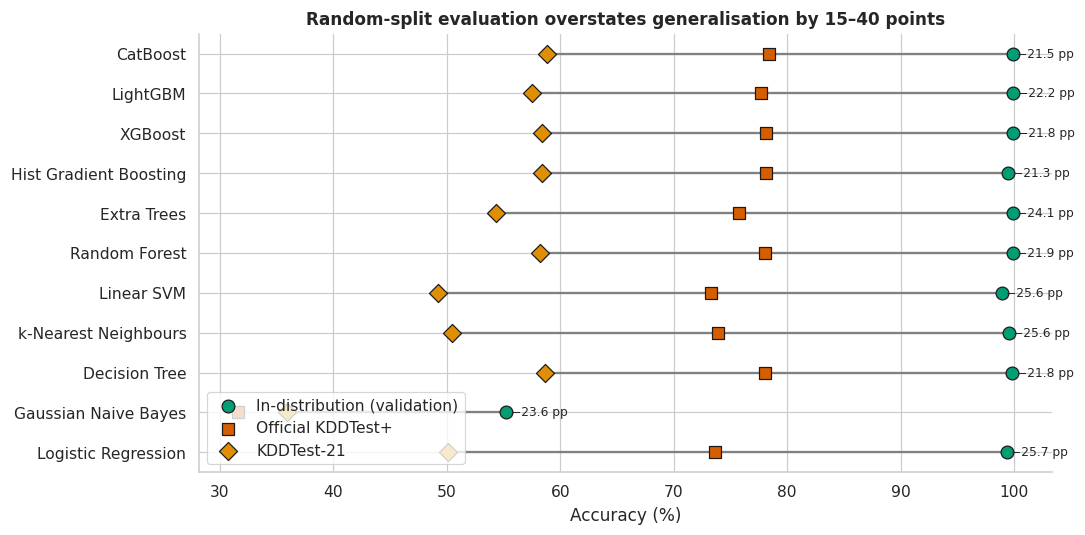

In [39]:
names = CLASSICAL + FACTORY
gap = pd.DataFrame({'In-distribution (validation)': [scores(yva, REG[n]['P']['va'])['Acc'] for n in names],
                    'Official KDDTest+': [scores(yte, REG[n]['P']['te'])['Acc'] for n in names],
                    'KDDTest-21': [scores(y21, REG[n]['P']['t21'])['Acc'] for n in names]}, index=names) * 100
gap['Inflation (pp)'] = gap['In-distribution (validation)'] - gap['Official KDDTest+']
save_table(gap.round(2), 'T20_protocol_gap')
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(gap))
for col, c, mk in [('In-distribution (validation)', PAL[2], 'o'), ('Official KDDTest+', PAL[3], 's'), ('KDDTest-21', PAL[1], 'D')]:
    ax.scatter(gap[col], y, color=c, s=70, marker=mk, label=col, zorder=3, edgecolor='k')
for i, (_, r) in enumerate(gap.iterrows()):
    ax.plot([r['KDDTest-21'], r['In-distribution (validation)']], [i, i], c='grey', lw=1.5, zorder=1)
    ax.text(r['In-distribution (validation)'] + .4, i, f"−{r['Inflation (pp)']:.1f} pp", va='center', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(gap.index); ax.set_xlabel('Accuracy (%)'); ax.legend(loc='lower left')
ax.set_title('Random-split evaluation overstates generalisation by 15–40 points')
savefig('protocol_inflation')

### 33. Learning curves: training-set size versus validation and test macro-F1

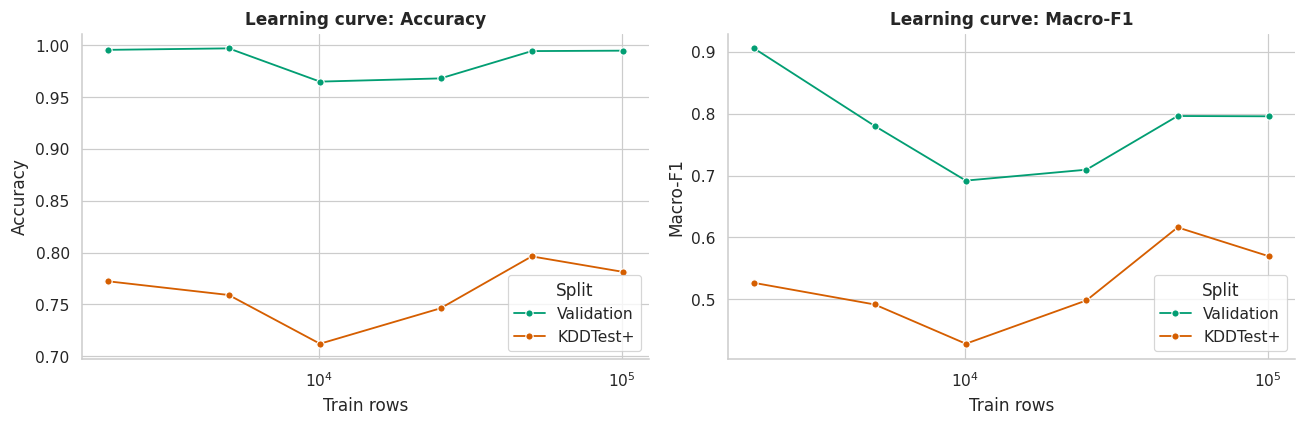

In [40]:
fracs = [0.02, 0.05, 0.1, 0.25, 0.5, 1.0] if not FAST else [0.1, 0.5, 1.0]
rows = []
for f in fracs:
    n = max(int(f * len(Xtr)), 500)
    i = train_test_split(np.arange(len(Xtr)), train_size=n, stratify=np.minimum(ytr, 3), random_state=SEED)[0] if f < 1 else np.arange(len(Xtr))
    m = hgb().fit(Xtr[i], ytr[i])
    for k in ('va', 'te'):
        p = m.predict(XS[k])
        rows.append({'Train rows': n, 'Split': SPL[k], 'Macro-F1': f1_score(YS[k], p, average='macro'), 'Accuracy': accuracy_score(YS[k], p)})
LC = save_table(pd.DataFrame(rows), 'T21_learning_curve')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, met in zip(ax, ['Accuracy', 'Macro-F1']):
    sns.lineplot(data=LC, x='Train rows', y=met, hue='Split', marker='o', ax=a_, palette=[PAL[2], PAL[3]])
    a_.set_xscale('log'); a_.set_title(f'Learning curve: {met}')
savefig('learning_curves')

### 34. Official 20% training subset versus the full training split

In [41]:
fb20 = FeatureBuilder()
X20 = fb20.fit_transform(t20, t20['y'].values)
m20 = hgb().fit(X20, t20['y'].values)
rows = []
for n, mm, f in [('KDDTrain+_20Percent (25,192 rows)', m20, fb20), (f'Train split ({len(TR):,} rows)', REG['Hist Gradient Boosting']['model'], FB)]:
    for d, nm in [(tst, 'KDDTest+'), (t21, 'KDDTest-21')]:
        p = mm.predict(f.transform(d))
        rows.append({'Training data': n, 'Evaluated on': nm, 'Accuracy': accuracy_score(d['y'], p),
                     'Macro-F1': f1_score(d['y'], p, average='macro'), 'Binary acc': accuracy_score(d['bin'], p > 0)})
display(save_table(pd.DataFrame(rows).set_index(['Training data', 'Evaluated on']).round(4), 'T22_train20_vs_full'))

Accuracy  Macro-F1  Binary acc
Training data                     Evaluated on                                
KDDTrain+_20Percent (25,192 rows) KDDTest+        0.7804    0.6128      0.8009
                                  KDDTest-21      0.5832    0.5240      0.6223
Train split (100,778 rows)        KDDTest+        0.7814    0.5697      0.8051
                                  KDDTest-21      0.5842    0.4832      0.6295

## Part E — Hyper-parameter optimisation on validation only

### 35. Bayesian (TPE) hyper-parameter search scored on validation macro-F1

In [42]:
N_TRIALS = 25 if not FAST else 4
TUNE_LOG = []
def objective_params(params):
    if lgb is not None:
        m = lgb.LGBMClassifier(n_jobs=N_JOBS, random_state=SEED, verbose=-1, subsample_freq=1, **params)
    else:
        m = HistGradientBoostingClassifier(random_state=SEED, **params)
    m.fit(Xtr, ytr)
    s = f1_score(yva, m.predict(Xva), average='macro')
    TUNE_LOG.append({**params, 'val_macro_f1': s})
    return s

def suggest(trial):
    if lgb is not None:
        return {'n_estimators': trial.suggest_int('n_estimators', 150, 700, step=50),
                'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
                'num_leaves': trial.suggest_int('num_leaves', 15, 127, log=True),
                'min_child_samples': trial.suggest_int('min_child_samples', 5, 60),
                'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
                'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True)}
    return {'max_iter': trial.suggest_int('max_iter', 100, 500, step=50),
            'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.3, log=True),
            'max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 15, 127, log=True),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 5, 60),
            'l2_regularization': trial.suggest_float('l2_regularization', 1e-4, 5, log=True)}

if optuna is not None:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    STUDY = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    STUDY.optimize(lambda t: objective_params(suggest(t)), n_trials=N_TRIALS)
    BEST_PARAMS = STUDY.best_params
else:
    STUDY = None
    rng = np.random.RandomState(SEED)
    for _ in range(N_TRIALS):
        objective_params({'max_iter': int(rng.choice([150, 250, 400])), 'learning_rate': float(10 ** rng.uniform(-1.5, -0.5)),
                          'max_leaf_nodes': int(rng.choice([15, 31, 63, 127])), 'min_samples_leaf': int(rng.randint(5, 60)),
                          'l2_regularization': float(10 ** rng.uniform(-4, 0.7))})
    BEST_PARAMS = {k: v for k, v in max(TUNE_LOG, key=lambda r: r['val_macro_f1']).items() if k != 'val_macro_f1'}
TUNED_NAME = ('Tuned LightGBM' if lgb is not None else 'Tuned HGB')
print(TUNED_NAME, 'best validation macro-F1 =', round(max(r['val_macro_f1'] for r in TUNE_LOG), 4))
display(pd.Series(BEST_PARAMS).to_frame('Best value'))

Tuned LightGBM best validation macro-F1 = 0.9759


,Best value
n_estimators,650.000000
learning_rate,0.025006
num_leaves,41.000000
min_child_samples,47.000000
subsample,0.712266
colsample_bytree,0.418842
reg_lambda,0.064162


### 36. Optimisation history and hyper-parameter importance

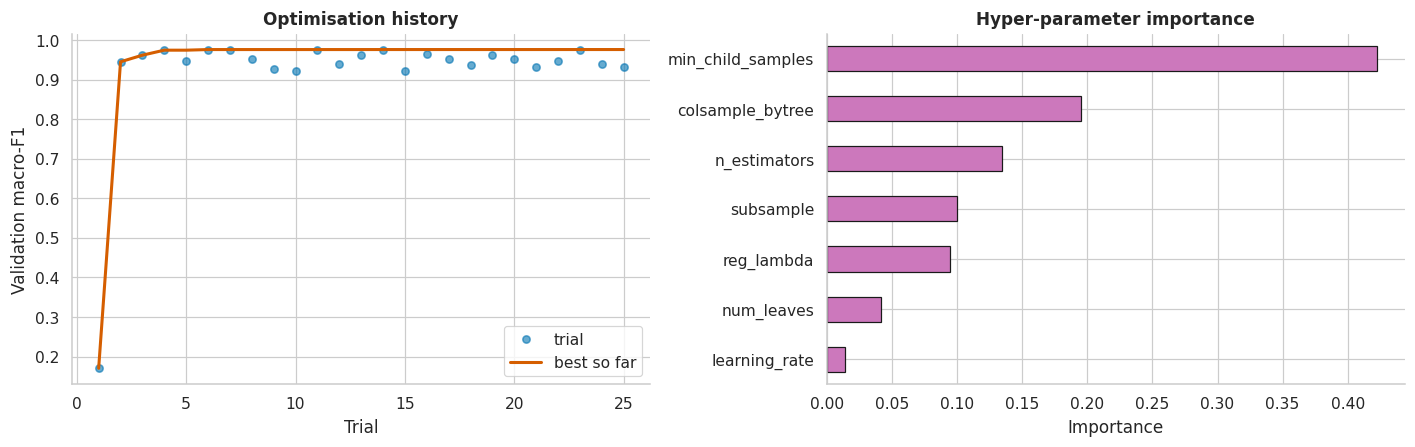

In [43]:
TL = save_table(pd.DataFrame(TUNE_LOG), 'T23_tuning_log')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(TL.index + 1, TL['val_macro_f1'], 'o', color=PAL[0], alpha=.6, label='trial')
ax[0].plot(TL.index + 1, TL['val_macro_f1'].cummax(), '-', color=PAL[3], lw=2, label='best so far')
ax[0].set_xlabel('Trial'); ax[0].set_ylabel('Validation macro-F1'); ax[0].legend(); ax[0].set_title('Optimisation history')
num_cols = [c for c in TL.columns if c != 'val_macro_f1']
if STUDY is not None and len(TL) >= 4:
    try:
        imp = pd.Series(optuna.importance.get_param_importances(STUDY))
    except Exception:
        imp = TL[num_cols].corrwith(TL['val_macro_f1'], method='spearman').abs()
else:
    imp = TL[num_cols].corrwith(TL['val_macro_f1'], method='spearman').abs()
imp.fillna(0).sort_values().plot.barh(ax=ax[1], color=PAL[4], edgecolor='k')
ax[1].set_title('Hyper-parameter importance'); ax[1].set_xlabel('Importance')
savefig('tuning_history')

### 37. Tuned model: train, validation and test report

In [44]:
TUNED = (lgb.LGBMClassifier(n_jobs=N_JOBS, random_state=SEED, verbose=-1, subsample_freq=1, **BEST_PARAMS)
         if lgb is not None else HistGradientBoostingClassifier(random_state=SEED, **BEST_PARAMS))
fit_register(TUNED_NAME, TUNED)
save_table(show([TUNED_NAME] + FACTORY), 'T24_tuned_tvt')

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,1.0000,1.0000,0.9994,0.9759,0.7811,0.5452,0.5836,0.4573,58.0517
Random Forest,1.0000,1.0000,0.9989,0.9290,0.7802,0.5335,0.5820,0.4452,22.1930
Extra Trees,1.0000,1.0000,0.9988,0.9270,0.7575,0.5272,0.5435,0.4288,20.9257
Hist Gradient Boosting,0.9962,0.8251,0.9948,0.7957,0.7814,0.5697,0.5842,0.4832,6.9638
XGBoost,1.0000,1.0000,0.9992,0.9525,0.7814,0.5727,0.5842,0.4848,49.1941
LightGBM,1.0000,1.0000,0.9992,0.9215,0.7768,0.5583,0.5754,0.4691,26.7537
CatBoost,0.9999,0.9999,0.9990,0.9508,0.7837,0.5703,0.5885,0.4830,219.0677


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,0.99995,0.999977,0.999444,0.975897,0.781139,0.545213,0.583629,0.457299,58.051661
Random Forest,0.99995,0.999977,0.998889,0.928986,0.780163,0.533465,0.582025,0.445193,22.192972
Extra Trees,1.00000,1.000000,0.998809,0.926993,0.757541,0.527244,0.543460,0.428828,20.925725
Hist Gradient Boosting,0.99615,0.825097,0.994761,0.795698,0.781361,0.569676,0.584219,0.483155,6.963837
XGBoost,0.99995,0.999977,0.999206,0.952547,0.781450,0.572657,0.584219,0.484791,49.194127
LightGBM,0.99995,0.999977,0.999167,0.921489,0.776792,0.558266,0.575359,0.469140,26.753741
CatBoost,0.99990,0.999911,0.998968,0.950819,0.783667,0.570282,0.588523,0.482982,219.067683


## Part F — Deep learning models (early stopping on an inner split of the training data)

### Deep-learning utilities with an inner early-stopping split

In [45]:
ES_TR, ES_VA = train_test_split(np.arange(len(Xtr)), test_size=0.1, stratify=np.minimum(ytr, 3), random_state=SEED)
HIST = {}
DL_EPOCHS = 40 if not FAST else 2
CW_SQRT = {i: float(w) for i, w in enumerate((len(ytr) / (5 * np.bincount(ytr, minlength=5).clip(1))) ** 0.5)}

def as_seq(X):
    return X[:, SEQ_IDX][..., None]

def fit_keras(name, model, prep=None, epochs=None, batch=512, class_weight=None, loss='sparse_categorical_crossentropy', y_fit=None):
    if tf is None:
        print('TensorFlow unavailable — skipped', name)
        return None
    prep = prep or (lambda X: X)
    epochs = epochs or DL_EPOCHS
    yf = ytr if y_fit is None else y_fit
    steps = int(np.ceil(len(ES_TR) / batch)) * epochs
    opt = keras.optimizers.AdamW(learning_rate=keras.optimizers.schedules.CosineDecay(2e-3, steps), weight_decay=1e-4)
    model.compile(optimizer=opt, loss=loss, metrics=['accuracy'])
    cb_ = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)]
    t = time.time()
    h = model.fit(prep(Xtr[ES_TR]), yf[ES_TR], validation_data=(prep(Xtr[ES_VA]), yf[ES_VA]), epochs=epochs,
                  batch_size=batch, class_weight=class_weight, callbacks=cb_, verbose=0)
    ft = time.time() - t
    HIST[name] = h.history
    P = {}
    t = time.time()
    P['te'] = model.predict(prep(XS['te']), batch_size=4096, verbose=0)
    inf = (time.time() - t) / len(XS['te']) * 1e6
    for k in ('tr', 'va', 't21'):
        P[k] = model.predict(prep(XS[k]), batch_size=4096, verbose=0)
    register(name, P, fit_s=ft, inf_ms=inf, size_kb=model.count_params() * 4 / 1024, model=model, kind='deep')
    return model

NF = Xtr.shape[1]
DEEP = []
print('Inner early-stopping split:', len(ES_TR), 'fit rows /', len(ES_VA), 'monitor rows (both inside training data).')

Inner early-stopping split: 90700 fit rows / 10078 monitor rows (both inside training data).


### 38. Residual MLP with batch normalisation and cosine-decayed AdamW

In [46]:
if tf is not None:
    def res_block(x, u, d=0.2):
        h = layers.Dense(u)(x); h = layers.BatchNormalization()(h); h = layers.Activation('gelu')(h); h = layers.Dropout(d)(h)
        h = layers.Dense(u)(h); h = layers.BatchNormalization()(h)
        return layers.Activation('gelu')(layers.Add()([x, h]))
    inp = layers.Input((NF,))
    x = layers.Activation('gelu')(layers.BatchNormalization()(layers.Dense(256)(inp)))
    x = res_block(res_block(x, 256), 256)
    out = layers.Dense(5, activation='softmax')(layers.Dropout(0.3)(x))
    fit_keras('Residual MLP', keras.Model(inp, out)); DEEP.append('Residual MLP')
    show(['Residual MLP'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Residual MLP,0.9985,0.9557,0.998,0.929,0.7793,0.611,0.5811,0.5089,58.335


### 39. One-dimensional CNN over the engineered feature vector

In [47]:
if tf is not None:
    m = keras.Sequential([layers.Input((NF, 1)), layers.Conv1D(64, 5, padding='same', activation='relu'), layers.BatchNormalization(),
                          layers.MaxPooling1D(2), layers.Conv1D(128, 3, padding='same', activation='relu'), layers.BatchNormalization(),
                          layers.GlobalMaxPooling1D(), layers.Dense(128, activation='relu'), layers.Dropout(0.3), layers.Dense(5, activation='softmax')])
    fit_keras('1D-CNN', m, prep=lambda X: X[..., None]); DEEP.append('1D-CNN')
    show(['1D-CNN'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
1D-CNN,0.9974,0.9206,0.997,0.8785,0.799,0.5929,0.618,0.5061,69.4708


### 40. Bidirectional GRU over the mRMR-ordered feature sequence

In [48]:
if tf is not None:
    m = keras.Sequential([layers.Input((len(SEQ_IDX), 1)), layers.Bidirectional(layers.GRU(64)), layers.Dense(64, activation='relu'),
                          layers.Dropout(0.3), layers.Dense(5, activation='softmax')])
    fit_keras('BiGRU (mRMR sequence)', m, prep=as_seq, batch=1024); DEEP.append('BiGRU (mRMR sequence)')
    show(['BiGRU (mRMR sequence)'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
BiGRU (mRMR sequence),0.9975,0.9093,0.9964,0.8911,0.7869,0.5174,0.6008,0.4344,61.8181


### 41. CNN-BiLSTM with additive attention pooling

In [49]:
if tf is not None:
    inp = layers.Input((len(SEQ_IDX), 1))
    h = layers.Conv1D(64, 3, padding='same', activation='relu')(inp)
    h = layers.Bidirectional(layers.LSTM(48, return_sequences=True))(h)
    e = layers.Dense(1, activation='tanh')(h)
    a = layers.Softmax(axis=1)(e)
    ctx = layers.Lambda(lambda t: keras.ops.sum(t[0] * t[1], axis=1))([h, a])
    out = layers.Dense(5, activation='softmax')(layers.Dropout(0.3)(layers.Dense(64, activation='relu')(ctx)))
    fit_keras('CNN-BiLSTM-Attention', keras.Model(inp, out), prep=as_seq, batch=1024); DEEP.append('CNN-BiLSTM-Attention')
    show(['CNN-BiLSTM-Attention'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
CNN-BiLSTM-Attention,0.9974,0.7854,0.9965,0.7788,0.7738,0.5341,0.5769,0.4421,79.8294


### 42. Feature-tokenizer Transformer for tabular traffic

In [50]:
if tf is not None:
    class FeatureTokens(layers.Layer):
        def __init__(self, n, d, **kw):
            super().__init__(**kw); self.n, self.d = n, d
        def build(self, s):
            self.w = self.add_weight(shape=(self.n, self.d), initializer='glorot_uniform', name='w')
            self.b = self.add_weight(shape=(self.n, self.d), initializer='zeros', name='b')
            self.cls = self.add_weight(shape=(1, 1, self.d), initializer='glorot_uniform', name='cls')
        def call(self, x):
            t = keras.ops.expand_dims(x, -1) * self.w + self.b
            c = keras.ops.broadcast_to(self.cls, (keras.ops.shape(x)[0], 1, self.d))
            return keras.ops.concatenate([c, t], axis=1)
    def tblock(x, d=32, heads=4):
        a = layers.MultiHeadAttention(heads, d // heads, dropout=0.1)(x, x)
        x = layers.LayerNormalization()(x + a)
        f = layers.Dense(d)(layers.Dropout(0.1)(layers.Dense(2 * d, activation='gelu')(x)))
        return layers.LayerNormalization()(x + f)
    inp = layers.Input((len(SEQ_IDX),))
    x = tblock(tblock(FeatureTokens(len(SEQ_IDX), 32)(inp)))
    out = layers.Dense(5, activation='softmax')(layers.Dense(64, activation='gelu')(x[:, 0]))
    fit_keras('FT-Transformer', keras.Model(inp, out), prep=lambda X: X[:, SEQ_IDX], batch=1024); DEEP.append('FT-Transformer')
    show(['FT-Transformer'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
FT-Transformer,0.9981,0.9508,0.9975,0.8866,0.7785,0.4987,0.5789,0.412,119.1999


### 43. Deep & Cross Network with explicit feature crosses

In [51]:
if tf is not None:
    class Cross(layers.Layer):
        def __init__(self, d, **kw):
            super().__init__(**kw)
            self.w = self.add_weight(shape=(d, 1), initializer='glorot_uniform', name='w')
            self.b = self.add_weight(shape=(d,), initializer='zeros', name='b')
        def call(self, x0, x):
            return x0 * keras.ops.matmul(x, self.w) + self.b + x
    inp = layers.Input((NF,))
    c = inp
    for _ in range(3):
        c = Cross(NF)(inp, c)
    d = layers.Dropout(0.2)(layers.Dense(128, activation='relu')(layers.Dense(256, activation='relu')(inp)))
    out = layers.Dense(5, activation='softmax')(layers.Concatenate()([c, d]))
    fit_keras('Deep & Cross Network', keras.Model(inp, out)); DEEP.append('Deep & Cross Network')
    show(['Deep & Cross Network'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Deep & Cross Network,0.9974,0.928,0.9969,0.878,0.7796,0.5626,0.5819,0.4641,20.2547


### 44. Tabular mixup-regularised MLP

In [52]:
if tf is not None:
    rng = np.random.RandomState(SEED)
    Y1 = np.eye(5)[ytr]
    perm = rng.permutation(len(Xtr))
    lam = rng.beta(0.2, 0.2, size=(len(Xtr), 1)).astype(np.float32)
    Xmix = np.vstack([Xtr, lam * Xtr + (1 - lam) * Xtr[perm]])
    Ymix = np.vstack([Y1, lam * Y1 + (1 - lam) * Y1[perm]])
    m = keras.Sequential([layers.Input((NF,)), layers.Dense(256, activation='gelu'), layers.Dropout(0.2),
                          layers.Dense(128, activation='gelu'), layers.Dense(5, activation='softmax')])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    t = time.time()
    inner = np.r_[ES_TR, len(Xtr) + ES_TR]
    h = m.fit(Xmix[inner], Ymix[inner], validation_data=(Xtr[ES_VA], Y1[ES_VA]), epochs=DL_EPOCHS, batch_size=512, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    HIST['Mixup MLP'] = h.history
    P = {k: m.predict(XS[k], batch_size=4096, verbose=0) for k in XS}
    register('Mixup MLP', P, fit_s=time.time() - t, size_kb=m.count_params() * 4 / 1024, model=m, kind='deep'); DEEP.append('Mixup MLP')
    show(['Mixup MLP'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Mixup MLP,0.999,0.9714,0.9981,0.9278,0.7618,0.5825,0.5495,0.4814,47.281


### 45. Self-supervised denoising-autoencoder pre-training with fine-tuning

In [53]:
if tf is not None:
    inp = layers.Input((NF,))
    z = layers.Dense(64, activation='gelu', name='z')(layers.Dense(256, activation='gelu')(layers.GaussianNoise(0.15)(layers.Dropout(0.1)(inp))))
    rec = layers.Dense(NF)(layers.Dense(256, activation='gelu')(z))
    dae = keras.Model(inp, rec)
    dae.compile(optimizer='adam', loss='mse')
    dae.fit(Xtr[ES_TR], Xtr[ES_TR], validation_data=(Xtr[ES_VA], Xtr[ES_VA]), epochs=max(DL_EPOCHS // 2, 1), batch_size=512, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
    enc = keras.Model(inp, dae.get_layer('z').output)
    i2 = layers.Input((NF,))
    out = layers.Dense(5, activation='softmax')(layers.Dropout(0.2)(layers.Dense(64, activation='gelu')(enc(i2))))
    fit_keras('DAE-pretrained MLP', keras.Model(i2, out)); DEEP.append('DAE-pretrained MLP')
    show(['DAE-pretrained MLP'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
DAE-pretrained MLP,0.998,0.9481,0.9982,0.944,0.7922,0.6719,0.6055,0.571,27.1954


### 46. Training dynamics of all deep models

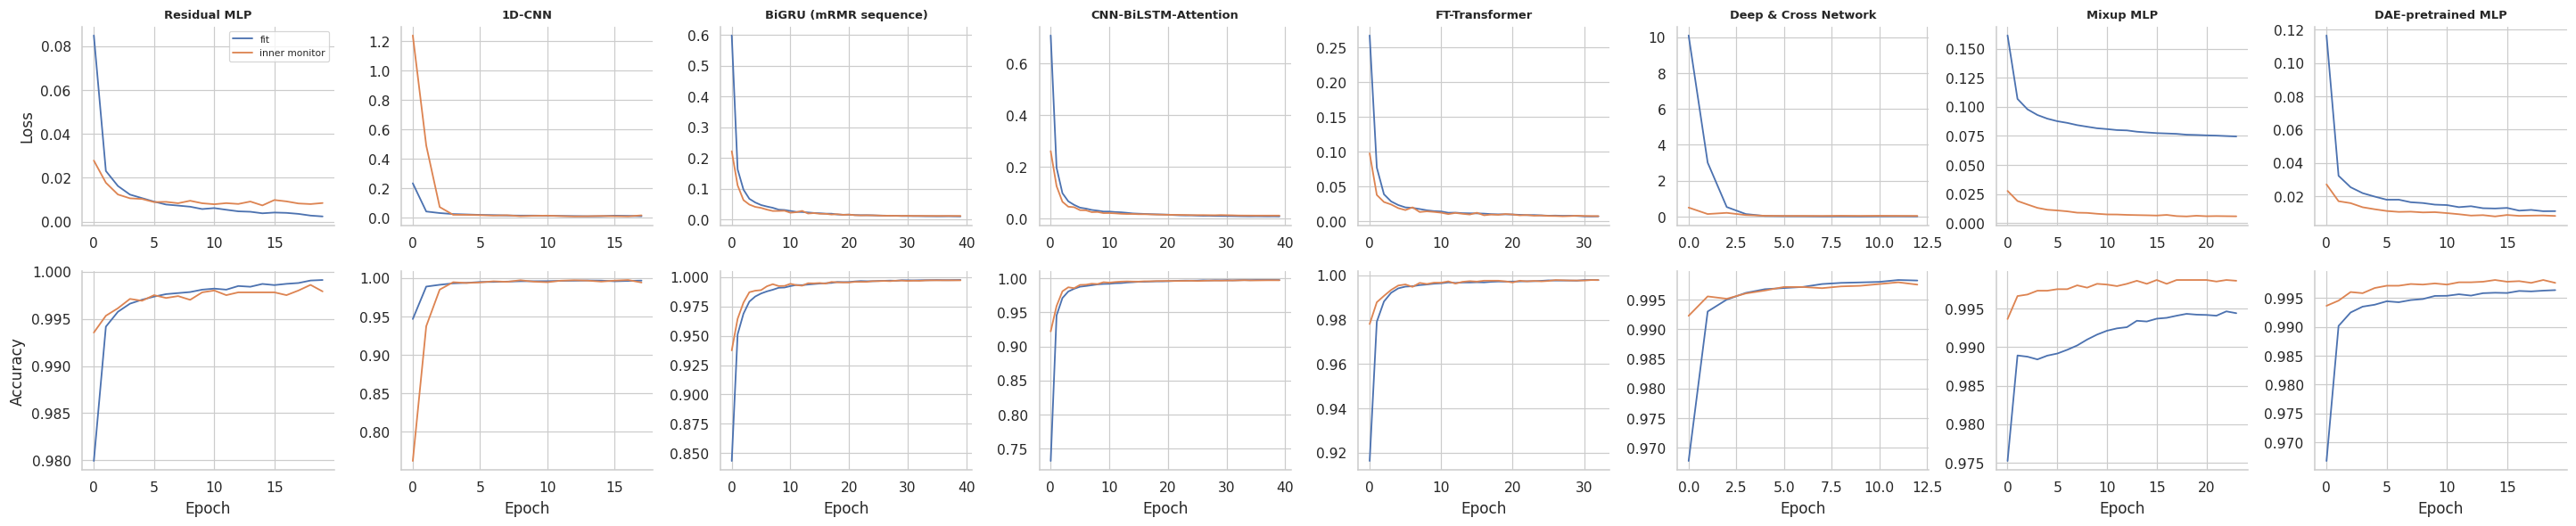

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Residual MLP,0.9985,0.9557,0.9980,0.9290,0.7793,0.6110,0.5811,0.5089,58.3350
1D-CNN,0.9974,0.9206,0.9970,0.8785,0.7990,0.5929,0.6180,0.5061,69.4708
BiGRU (mRMR sequence),0.9975,0.9093,0.9964,0.8911,0.7869,0.5174,0.6008,0.4344,61.8181
CNN-BiLSTM-Attention,0.9974,0.7854,0.9965,0.7788,0.7738,0.5341,0.5769,0.4421,79.8294
FT-Transformer,0.9981,0.9508,0.9975,0.8866,0.7785,0.4987,0.5789,0.4120,119.1999
Deep & Cross Network,0.9974,0.9280,0.9969,0.8780,0.7796,0.5626,0.5819,0.4641,20.2547
Mixup MLP,0.9990,0.9714,0.9981,0.9278,0.7618,0.5825,0.5495,0.4814,47.2810
DAE-pretrained MLP,0.9980,0.9481,0.9982,0.9440,0.7922,0.6719,0.6055,0.5710,27.1954


In [54]:
if HIST:
    n = len(HIST)
    fig, ax = plt.subplots(2, n, figsize=(3.3 * n, 5.5), squeeze=False)
    for j, (k, h) in enumerate(HIST.items()):
        ax[0, j].plot(h['loss'], label='fit'); ax[0, j].plot(h['val_loss'], label='inner monitor')
        ax[1, j].plot(h['accuracy']); ax[1, j].plot(h['val_accuracy'])
        ax[0, j].set_title(k, fontsize=8.5); ax[1, j].set_xlabel('Epoch')
    ax[0, 0].set_ylabel('Loss'); ax[1, 0].set_ylabel('Accuracy'); ax[0, 0].legend(fontsize=7)
    savefig('deep_training_curves')
    save_table(show(DEEP), 'T25_deep_tvt')
else:
    print('No deep models were trained in this runtime.')

## Part G — Minority-class (R2L / U2R) learning

### 47. Class-weight exponent sweep selected on validation

,Val macro-F1,Val balanced acc,Val R2L recall,Val U2R recall
Exponent p,,,,
0.00,0.7957,0.8456,0.9447,0.3
0.25,0.8268,0.8875,0.9497,0.5
0.50,0.9652,0.9551,0.9799,0.8
0.75,0.9554,0.9542,0.9749,0.8
1.00,0.9461,0.9730,0.9698,0.9


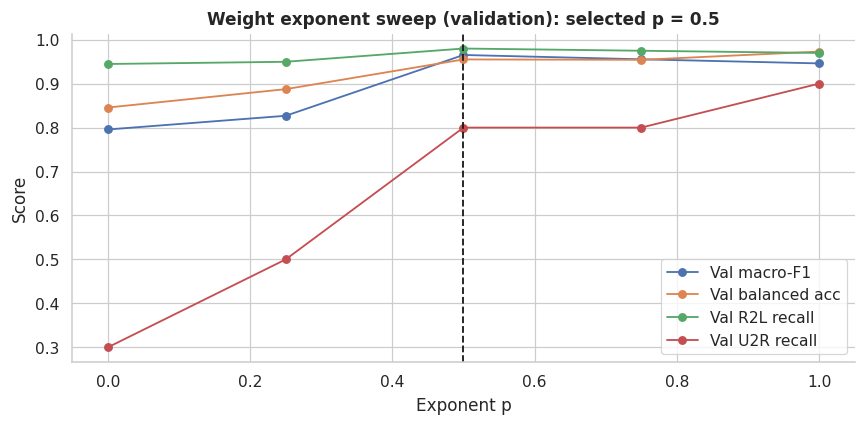

In [55]:
freq = np.bincount(ytr, minlength=5).clip(1)
rows = []
for p in [0, 0.25, 0.5, 0.75, 1.0]:
    w = (len(ytr) / (5 * freq)) ** p
    m = hgb().fit(Xtr, ytr, sample_weight=w[ytr])
    pv = m.predict(Xva)
    rows.append({'Exponent p': p, 'Val macro-F1': f1_score(yva, pv, average='macro'), 'Val balanced acc': balanced_accuracy_score(yva, pv),
                 'Val R2L recall': recall_score(yva, pv, labels=[3], average='macro'), 'Val U2R recall': recall_score(yva, pv, labels=[4], average='macro')})
CWS = save_table(pd.DataFrame(rows).set_index('Exponent p'), 'T26_class_weight_sweep')
P_BEST = float(CWS['Val macro-F1'].idxmax())
fit_register('HGB class-weighted', hgb(), sw=((len(ytr) / (5 * freq)) ** P_BEST)[ytr])
display(CWS.round(4))
CWS.plot(marker='o', figsize=(8, 4)); plt.axvline(P_BEST, ls='--', c='k')
plt.title(f'Weight exponent sweep (validation): selected p = {P_BEST}'); plt.ylabel('Score')
savefig('class_weight_sweep')

### 48. Resampling strategies applied inside the training split only

In [56]:
counts = np.bincount(ytr, minlength=5)
target = {3: int(max(counts[3], min(counts[1] // 6, counts[3] * 8))), 4: int(max(counts[4], min(counts[3], counts[4] * 25)))}
SAMPLERS = {}
if IMB:
    SAMPLERS = {'SMOTE': SMOTE(sampling_strategy=target, k_neighbors=5, random_state=SEED),
                'Borderline-SMOTE': BorderlineSMOTE(sampling_strategy=target, k_neighbors=5, random_state=SEED),
                'ADASYN': ADASYN(sampling_strategy=target, n_neighbors=5, random_state=SEED),
                'SMOTE-Tomek': SMOTETomek(sampling_strategy=target, random_state=SEED)}
else:
    class _ROS:
        def fit_resample(self, X, y):
            rng = np.random.RandomState(SEED); Xs, ys = [X], [y]
            for c, n in target.items():
                i = rng.choice(np.where(y == c)[0], n - (y == c).sum(), replace=True); Xs.append(X[i]); ys.append(y[i])
            return np.vstack(Xs), np.concatenate(ys)
    SAMPLERS = {'Random oversampling': _ROS()}
RESAMPLED = []
for n, s in SAMPLERS.items():
    try:
        Xr, yr = s.fit_resample(Xtr, ytr)
        fit_register(f'HGB + {n}', hgb(), Xfit=Xr, yfit=yr)
        RESAMPLED.append(f'HGB + {n}')
        print(f'{n:18s} training rows {len(Xtr):,} → {len(Xr):,}')
    except Exception as e:
        print(n, 'failed:', str(e)[:100])
save_table(show(['Hist Gradient Boosting', 'HGB class-weighted'] + RESAMPLED), 'T27_resampling_tvt')

SMOTE              training rows 100,778 → 106,859
Borderline-SMOTE   training rows 100,778 → 106,859
ADASYN             training rows 100,778 → 106,848
SMOTE-Tomek        training rows 100,778 → 106,821


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Hist Gradient Boosting,0.9962,0.8251,0.9948,0.7957,0.7814,0.5697,0.5842,0.4832,6.9638
HGB class-weighted,0.9999,0.9999,0.9991,0.9652,0.7897,0.6055,0.6006,0.5195,13.6699
HGB + SMOTE,1.0000,0.9999,0.9992,0.9498,0.7983,0.6345,0.6165,0.5466,40.3226
HGB + Borderline-SMOTE,0.9998,0.9904,0.9987,0.9227,0.7956,0.6205,0.6116,0.5366,17.2772
HGB + ADASYN,0.9984,0.8927,0.9973,0.8615,0.7893,0.5762,0.6029,0.4943,11.7021
HGB + SMOTE-Tomek,0.9990,0.9169,0.9972,0.8523,0.8105,0.6410,0.6397,0.5568,12.0918


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Hist Gradient Boosting,0.99615,0.825097,0.994761,0.795698,0.781361,0.569676,0.584219,0.483155,6.963837
HGB class-weighted,0.99990,0.999907,0.999087,0.965228,0.789700,0.605487,0.600591,0.519498,13.669891
HGB + SMOTE,0.99995,0.999930,0.999167,0.949840,0.798350,0.634548,0.616540,0.546566,40.322559
HGB + Borderline-SMOTE,0.99985,0.990373,0.998651,0.922692,0.795600,0.620504,0.611561,0.536564,17.277172
HGB + ADASYN,0.99840,0.892678,0.997261,0.861527,0.789257,0.576180,0.602869,0.494316,11.702103
HGB + SMOTE-Tomek,0.99900,0.916899,0.997222,0.852310,0.810460,0.641037,0.639747,0.556830,12.091839


### 49. Class-balanced focal-loss network

In [57]:
if tf is not None:
    ALPHA = tf.constant((np.array(list(CW_SQRT.values())) / np.mean(list(CW_SQRT.values()))).astype(np.float32))
    def focal(gamma=2.0):
        def loss(y_true, y_pred):
            oh = tf.one_hot(tf.cast(tf.reshape(y_true, [-1]), tf.int32), 5)
            p = tf.clip_by_value(y_pred, 1e-7, 1.0)
            return tf.reduce_mean(tf.reduce_sum(ALPHA * tf.pow(1 - p, gamma) * (-oh * tf.math.log(p)), axis=1))
        return loss
    m = keras.Sequential([layers.Input((NF,)), layers.Dense(256, activation='gelu'), layers.BatchNormalization(), layers.Dropout(0.2),
                          layers.Dense(128, activation='gelu'), layers.Dense(5, activation='softmax')])
    fit_keras('Focal-loss MLP', m, loss=focal()); DEEP.append('Focal-loss MLP')
    show(['Focal-loss MLP'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Focal-loss MLP,0.9905,0.804,0.9904,0.8093,0.7743,0.6494,0.5716,0.5514,14.9816


### 50. Cost-sensitive Bayes-optimal decisions under an operational cost matrix

In [58]:
COST = np.ones((5, 5)) - np.eye(5)
COST[1:, 0] = [4, 4, 8, 12]
COST[0, 1:] = 1.5
display(pd.DataFrame(COST, index=[f'true {c}' for c in CLASSES], columns=[f'pred {c}' for c in CLASSES]))

def best_by_val(names):
    return max(names, key=lambda n: scores(yva, REG[n]['P']['va'], REG[n]['pred']['va'])['MacroF1'])

BEST_SUP = best_by_val(FACTORY + [TUNED_NAME])
P = REG[BEST_SUP]['P']
pred = {k: (v @ COST).argmin(1) for k, v in P.items()}
register(f'Cost-sensitive {BEST_SUP}', P, pred=pred, kind='decision')
exp_cost = lambda y, pr: COST[y, pr].mean()
display(pd.DataFrame({'Argmax': [exp_cost(YS[k], P[k].argmax(1)) for k in ('va', 'te', 't21')],
                      'Bayes-optimal': [exp_cost(YS[k], pred[k]) for k in ('va', 'te', 't21')]},
                     index=['Validation', 'KDDTest+', 'KDDTest-21']).round(4).rename_axis('Mean operational cost'))
show([BEST_SUP, f'Cost-sensitive {BEST_SUP}'])

,pred normal,pred dos,pred probe,pred r2l,pred u2r
true normal,0.0,1.5,1.5,1.5,1.5
true dos,4.0,0.0,1.0,1.0,1.0
true probe,4.0,1.0,0.0,1.0,1.0
true r2l,8.0,1.0,1.0,0.0,1.0
true u2r,12.0,1.0,1.0,1.0,0.0


,Argmax,Bayes-optimal
Mean operational cost,,
Validation,0.0030,0.0025
KDDTest+,1.3173,1.2258
KDDTest-21,2.5061,2.3319


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,1.0,1.0,0.9994,0.9759,0.7811,0.5452,0.5836,0.4573,58.0517
Cost-sensitive Tuned LightGBM,1.0,1.0,0.9994,0.9871,0.7939,0.5928,0.6079,0.5059,NaN


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,0.99995,0.999977,0.999444,0.975897,0.781139,0.545213,0.583629,0.457299,58.051661
Cost-sensitive Tuned LightGBM,0.99995,0.999977,0.999444,0.987124,0.793914,0.592788,0.607932,0.505931,NaN


### 51. Cross-fitted per-class probability scaling (unbiased validation estimate)

In [59]:
def tune_scaling(P, y, grid=(0.5, 0.75, 1, 1.5, 2, 3, 5, 8, 12, 20)):
    w = np.ones(5)
    for _ in range(2):
        for c in range(1, 5):
            best = max(grid, key=lambda g: f1_score(y, (P * np.r_[w[:c], g, w[c + 1:]]).argmax(1), average='macro'))
            w[c] = best
    return w

def crossfit(tune, apply, Pva, yv, n_folds=2):
    out = np.zeros(len(yv), dtype=int)
    for a, b in StratifiedKFold(n_folds, shuffle=True, random_state=SEED).split(Pva, np.minimum(yv, 3)):
        out[b] = apply(Pva[b], tune(Pva[a], yv[a]))
    return out, tune(Pva, yv)

P = REG[BEST_SUP]['P']
va_pred, W = crossfit(tune_scaling, lambda P_, w: (P_ * w).argmax(1), P['va'], yva)
pred = {'va': va_pred, **{k: (P[k] * W).argmax(1) for k in ('tr', 'te', 't21')}}
register(f'{BEST_SUP} + class scaling', P, pred=pred, kind='decision')
print('Scaling factors tuned on validation:', dict(zip(CLASSES, W.round(2))))
show([BEST_SUP, f'{BEST_SUP} + class scaling'])

Scaling factors tuned on validation: {'normal': np.float64(1.0), 'dos': np.float64(0.5), 'probe': np.float64(3.0), 'r2l': np.float64(2.0), 'u2r': np.float64(3.0)}


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,1.0,1.0,0.9994,0.9759,0.7811,0.5452,0.5836,0.4573,58.0517
Tuned LightGBM + class scaling,1.0,1.0,0.9993,0.9627,0.7874,0.5741,0.5956,0.4861,NaN


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,0.99995,0.999977,0.999444,0.975897,0.781139,0.545213,0.583629,0.457299,58.051661
Tuned LightGBM + class scaling,1.00000,1.000000,0.999325,0.962717,0.787438,0.574117,0.595612,0.486105,NaN


### 52. Two-stage hierarchical detector (attack detection, then family classification)

In [60]:
class TwoStage:
    def __init__(self, s1, s2):
        self.s1, self.s2 = s1, s2
    def fit(self, X, y):
        self.s1.fit(X, (y > 0).astype(int))
        self.s2.fit(X[y > 0], y[y > 0])
        return self
    def predict_proba(self, X):
        pa = self.s1.predict_proba(X)[:, 1:2]
        return np.hstack([1 - pa, pa * full5(self.s2, self.s2.predict_proba(X))[:, 1:]])

fit_register('Two-stage hierarchical', TwoStage(hgb(), RandomForestClassifier(300, class_weight='balanced_subsample', n_jobs=N_JOBS, random_state=SEED)))
show([BEST_SUP, 'Two-stage hierarchical'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,1.0000,1.0,0.9994,0.9759,0.7811,0.5452,0.5836,0.4573,58.0517
Two-stage hierarchical,0.9999,1.0,0.9991,0.9302,0.7767,0.5755,0.5752,0.4857,22.9473


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,0.99995,0.999977,0.999444,0.975897,0.781139,0.545213,0.583629,0.457299,58.051661
Two-stage hierarchical,0.99990,0.999954,0.999087,0.930220,0.776659,0.575477,0.575190,0.485664,22.947319


### 53. Minority specialist experts for R2L and U2R with validation-tuned gating

In [61]:
EXPERTS = {}
for c in (3, 4):
    yb = (ytr == c).astype(int)
    w = np.where(yb == 1, (len(yb) - yb.sum()) / max(yb.sum(), 1), 1.0) ** 0.5
    EXPERTS[c] = hgb().fit(Xtr, yb, sample_weight=w)
ES = {k: np.column_stack([EXPERTS[c].predict_proba(XS[k])[:, 1] for c in (3, 4)]) for k in XS}
base = REG[BEST_SUP]['P']

def gate_apply(D, t):
    P_, E_ = D
    pr = P_.argmax(1).copy()
    pr[E_[:, 0] > t[0]] = 3
    pr[E_[:, 1] > t[1]] = 4
    return pr

def gate_tune(D, y):
    grid = [0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 1.01]
    return max(itertools.product(grid, grid), key=lambda t: f1_score(y, gate_apply(D, t), average='macro'))

va_pred = np.zeros(len(yva), dtype=int)
for a, b in StratifiedKFold(2, shuffle=True, random_state=SEED).split(base['va'], np.minimum(yva, 3)):
    va_pred[b] = gate_apply((base['va'][b], ES['va'][b]), gate_tune((base['va'][a], ES['va'][a]), yva[a]))
T_GATE = gate_tune((base['va'], ES['va']), yva)
pred = {'va': va_pred, **{k: gate_apply((base[k], ES[k]), T_GATE) for k in ('tr', 'te', 't21')}}
register('Specialist-gated ensemble', base, pred=pred, kind='decision')
print('Gate thresholds (R2L, U2R):', T_GATE)
show([BEST_SUP, 'Specialist-gated ensemble'])

Gate thresholds (R2L, U2R): (0.9, 0.99)


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,1.0,1.0,0.9994,0.9759,0.7811,0.5452,0.5836,0.4573,58.0517
Specialist-gated ensemble,1.0,1.0,0.9994,0.9660,0.7876,0.5634,0.5959,0.4760,NaN


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,0.99995,0.999977,0.999444,0.975897,0.781139,0.545213,0.583629,0.457299,58.051661
Specialist-gated ensemble,0.99995,0.999977,0.999365,0.966024,0.787571,0.563406,0.595865,0.476023,NaN


### 54. Balanced Random Forest and EasyEnsemble

In [62]:
BAL = []
if IMB:
    fit_register('Balanced Random Forest', BalancedRandomForestClassifier(300, sampling_strategy='not minority', replacement=True,
                                                                          bootstrap=False, n_jobs=N_JOBS, random_state=SEED)); BAL.append('Balanced Random Forest')
    fit_register('EasyEnsemble', EasyEnsembleClassifier(n_estimators=10, n_jobs=N_JOBS, random_state=SEED)); BAL.append('EasyEnsemble')
else:
    fit_register('RF balanced-subsample', RandomForestClassifier(300, class_weight='balanced_subsample', n_jobs=N_JOBS, random_state=SEED)); BAL.append('RF balanced-subsample')
show(BAL)

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Balanced Random Forest,0.9352,0.6550,0.9379,0.6526,0.7705,0.5913,0.5744,0.4969,4.0729
EasyEnsemble,0.9178,0.6339,0.9229,0.6330,0.7401,0.5735,0.5479,0.4766,3.4870


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Balanced Random Forest,0.93525,0.654993,0.937885,0.652602,0.770493,0.591328,0.574430,0.496941,4.072945
EasyEnsemble,0.91785,0.633905,0.922921,0.632957,0.740108,0.573499,0.547932,0.476554,3.486969


### 55. Per-class recall heatmap across imbalance strategies

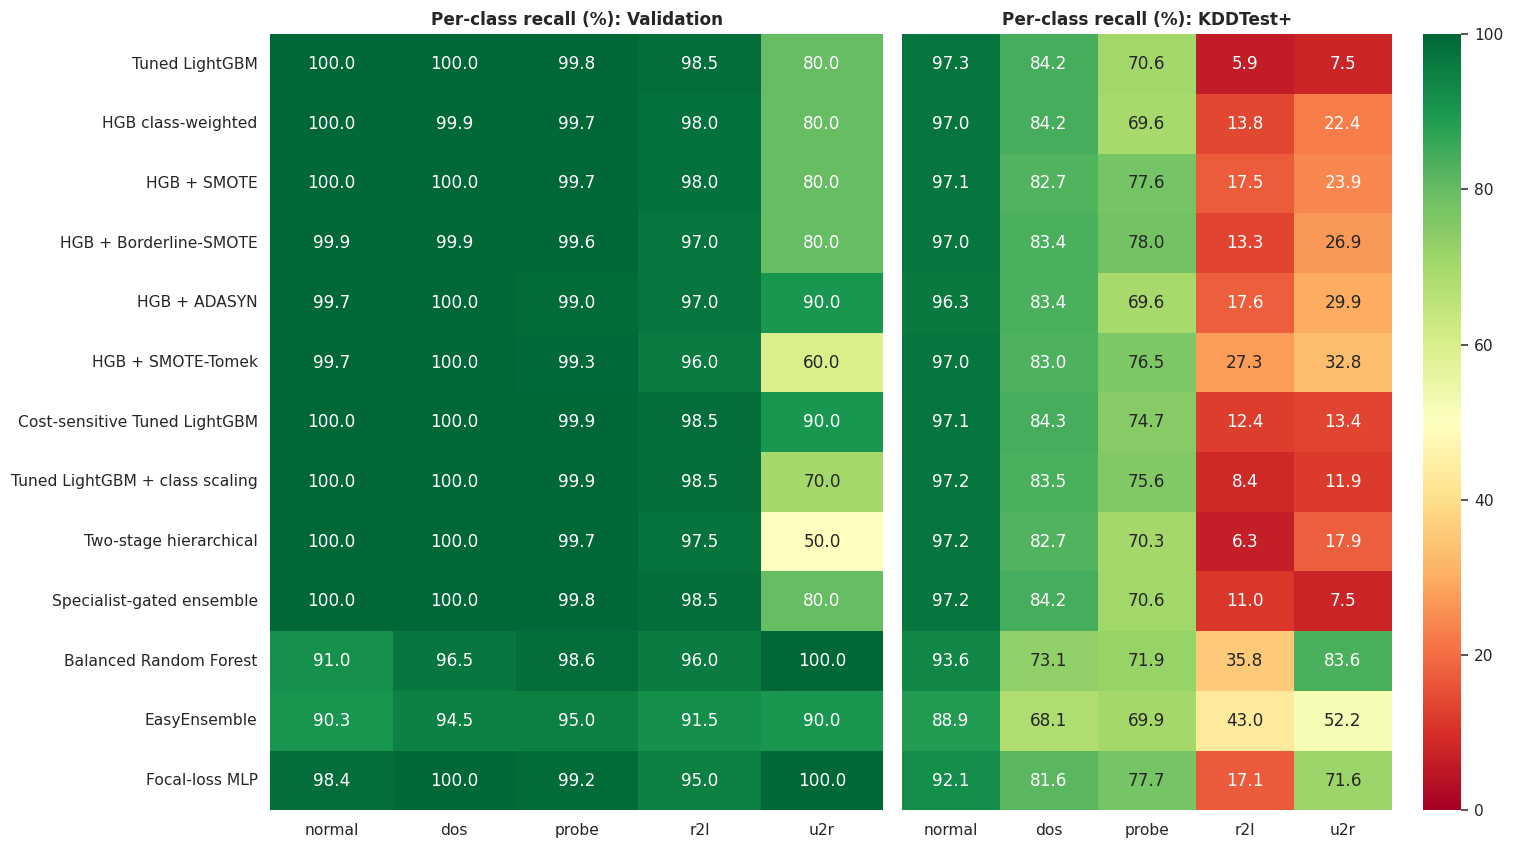

In [63]:
IMB_NAMES = [BEST_SUP, 'HGB class-weighted'] + RESAMPLED + [f'Cost-sensitive {BEST_SUP}', f'{BEST_SUP} + class scaling',
             'Two-stage hierarchical', 'Specialist-gated ensemble'] + BAL + [n for n in ['Focal-loss MLP'] if n in REG]
fig, ax = plt.subplots(1, 2, figsize=(14, 0.45 * len(IMB_NAMES) + 2))
for a_, k in zip(ax, ['va', 'te']):
    R = pd.DataFrame({n: recall_score(YS[k], REG[n]['pred'][k], labels=range(5), average=None, zero_division=0) for n in IMB_NAMES},
                     index=CLASSES).T * 100
    sns.heatmap(R, annot=True, fmt='.1f', cmap='RdYlGn', vmin=0, vmax=100, ax=a_, cbar=k == 'te')
    a_.set_title(f'Per-class recall (%): {SPL[k]}')
    if k == 'te':
        a_.set_yticklabels([])
    save_table(R.round(2), f'T28_recall_{k}')
savefig('imbalance_recall_heatmap')

## Part H — Zero-day detection: normal-only anomaly scorers and LOFO-validated hybrid fusion

### 56. Normal-only Isolation Forest scorer

In [64]:
class ECDF:
    def __init__(self, ref):
        self.ref = np.sort(np.asarray(ref))
    def __call__(self, s):
        return np.searchsorted(self.ref, s, side='right') / len(self.ref)

def make_scorer(kind, seed=SEED):
    if kind == 'Isolation Forest':
        m = IsolationForest(n_estimators=300, max_samples=4096, random_state=seed, n_jobs=N_JOBS)
        return m, lambda m, X: -m.score_samples(X)
    if kind == 'Local Outlier Factor':
        m = LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=N_JOBS)
        return m, lambda m, X: -m.score_samples(X)
    if kind == 'Mahalanobis (Ledoit-Wolf)':
        m = LedoitWolf()
        return m, lambda m, X: m.mahalanobis(X)
    if kind == 'Autoencoder':
        m = MLPRegressor(hidden_layer_sizes=(96, 24, 96), activation='relu', max_iter=40 if not FAST else 5,
                         batch_size=512, early_stopping=True, random_state=seed)
        return m, lambda m, X: ((m.predict(X) - X) ** 2).mean(1)
    raise ValueError(kind)

def fit_scorer(kind, Xn, seed=SEED):
    m, f = make_scorer(kind, seed)
    cap = {'Local Outlier Factor': 15000, 'Autoencoder': 40000}.get(kind, len(Xn))
    Xf = Xn if len(Xn) <= cap else Xn[np.random.RandomState(seed).choice(len(Xn), cap, replace=False)]
    if kind == 'Autoencoder':
        m.fit(Xf, Xf)
    else:
        m.fit(Xf)
    ref = f(m, Xf if kind != 'Local Outlier Factor' else Xn[:min(len(Xn), 30000)])
    ec = ECDF(ref)
    return lambda X: ec(f(m, X))

ANOM, ANOM_FN = {}, {}
def add_scorer(kind):
    t = time.time()
    fn = fit_scorer(kind, Xtr[ytr == 0])
    ANOM_FN[kind] = fn
    ANOM[kind] = {k: fn(XS[k]) for k in XS}
    r = {'Fit+score time (s)': time.time() - t}
    for k in ('va', 'te'):
        r[f'Attack-vs-normal AUC ({SPL[k]})'] = roc_auc_score(YS[k] > 0, ANOM[kind][k])
    r['Zero-day vs normal AUC (KDDTest+)'] = roc_auc_score(np.r_[np.zeros((yte == 0).sum()), np.ones(NOVEL['te'].sum())],
                                                           np.r_[ANOM[kind]['te'][yte == 0], ANOM[kind]['te'][NOVEL['te']]])
    return r

SCORER_TAB = {'Isolation Forest': add_scorer('Isolation Forest')}
display(pd.DataFrame(SCORER_TAB).T.round(4))

,Fit+score time (s),Attack-vs-normal AUC (Validation),Attack-vs-normal AUC (KDDTest+),Zero-day vs normal AUC (KDDTest+)
Isolation Forest,3.8219,0.9904,0.9582,0.9521


### 57. Normal-only autoencoder reconstruction scorer

In [65]:
SCORER_TAB['Autoencoder'] = add_scorer('Autoencoder')
display(pd.DataFrame(SCORER_TAB).T.round(4))

,Fit+score time (s),Attack-vs-normal AUC (Validation),Attack-vs-normal AUC (KDDTest+),Zero-day vs normal AUC (KDDTest+)
Isolation Forest,3.8219,0.9904,0.9582,0.9521
Autoencoder,12.6543,0.9945,0.9668,0.9542


### 58. Normal-only Local Outlier Factor novelty scorer

In [66]:
SCORER_TAB['Local Outlier Factor'] = add_scorer('Local Outlier Factor')
display(pd.DataFrame(SCORER_TAB).T.round(4))

,Fit+score time (s),Attack-vs-normal AUC (Validation),Attack-vs-normal AUC (KDDTest+),Zero-day vs normal AUC (KDDTest+)
Isolation Forest,3.8219,0.9904,0.9582,0.9521
Autoencoder,12.6543,0.9945,0.9668,0.9542
Local Outlier Factor,19.2423,0.9592,0.8580,0.8684


### 59. Mahalanobis distance scorer with Ledoit-Wolf shrinkage

,Fit+score time (s),Attack-vs-normal AUC (Validation),Attack-vs-normal AUC (KDDTest+),Zero-day vs normal AUC (KDDTest+)
Isolation Forest,3.8219,0.9904,0.9582,0.9521
Autoencoder,12.6543,0.9945,0.9668,0.9542
Local Outlier Factor,19.2423,0.9592,0.8580,0.8684
Mahalanobis (Ledoit-Wolf),1.3579,0.9832,0.9684,0.9518


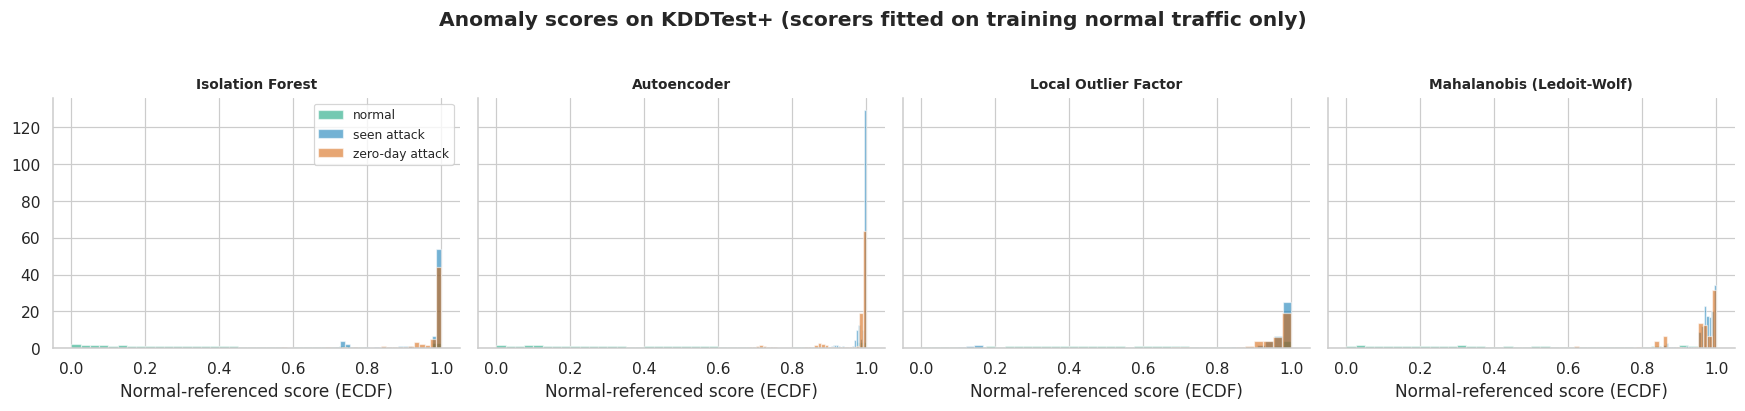

In [67]:
SCORER_TAB['Mahalanobis (Ledoit-Wolf)'] = add_scorer('Mahalanobis (Ledoit-Wolf)')
ST = save_table(pd.DataFrame(SCORER_TAB).T, 'T29_anomaly_scorers')
display(ST.round(4))
fig, ax = plt.subplots(1, len(ANOM), figsize=(4 * len(ANOM), 3.6), sharey=True)
for a_, (k, s) in zip(np.atleast_1d(ax), ANOM.items()):
    for lab, m, c in [('normal', yte == 0, PAL[2]), ('seen attack', (yte > 0) & ~NOVEL['te'], PAL[0]), ('zero-day attack', NOVEL['te'], PAL[3])]:
        a_.hist(s['te'][m], bins=40, alpha=.55, density=True, label=lab, color=c)
    a_.set_title(k, fontsize=9); a_.set_xlabel('Normal-referenced score (ECDF)')
np.atleast_1d(ax)[0].legend(fontsize=8)
plt.suptitle('Anomaly scores on KDDTest+ (scorers fitted on training normal traffic only)', y=1.03, fontweight='bold')
savefig('anomaly_score_distributions')

### 60. Uncertainty-based OOD scores (max-softmax and predictive entropy)

In [68]:
P = REG[BEST_SUP]['P']
ent = {k: -(P[k] * np.log(P[k] + 1e-12)).sum(1) for k in P}
msp = {k: 1 - P[k].max(1) for k in P}
rows = {}
for n, s in [('1 − max softmax', msp), ('Predictive entropy', ent)] + [(k, v) for k, v in ANOM.items()]:
    m = (yte > 0)
    rows[n] = {'Zero-day vs seen attacks AUC': roc_auc_score(NOVEL['te'][m], s['te'][m]),
               'Zero-day vs normal AUC': roc_auc_score(np.r_[np.zeros((yte == 0).sum()), np.ones(NOVEL['te'].sum())],
                                                     np.r_[s['te'][yte == 0], s['te'][NOVEL['te']]])}
display(save_table(pd.DataFrame(rows).T.round(4), 'T30_ood_scores'))
print('Reported for analysis only; nothing here is used for model or threshold selection.')

,Zero-day vs seen attacks AUC,Zero-day vs normal AUC
1 − max softmax,0.8403,0.9377
Predictive entropy,0.8411,0.9375
Isolation Forest,0.3632,0.9521
Autoencoder,0.4895,0.9542
Local Outlier Factor,0.4269,0.8684
Mahalanobis (Ledoit-Wolf),0.4360,0.9518


Reported for analysis only; nothing here is used for model or threshold selection.


### 61. LOFO-validated hybrid fusion of supervised and anomaly evidence (core method)

In [69]:
ALPHAS = np.round(np.arange(0, 1.0001, 0.05), 2)
TAUS = np.round(np.arange(0.02, 0.981, 0.02), 2)
LOFO_MODEL = best_by_val(FACTORY + [TUNED_NAME])
SURF = {k: np.zeros((len(ALPHAS), len(TAUS))) for k in ANOM}
LOFO_DET = []
t0 = time.time()
for fam, (fit_rows, ev) in LOFO.items():
    fb = FeatureBuilder()
    Xf = fb.fit_transform(TR.iloc[fit_rows], ytr[fit_rows])
    yf = ytr[fit_rows]
    clf = factory(LOFO_MODEL).fit(Xf, yf)
    Xe = fb.transform(ev)
    ye = (ev['y'].values > 0).astype(int)
    pa = 1 - proba_of(clf, Xe)[:, 0]
    held = (ev['cat'] == fam).values
    for kind in ANOM:
        r = fit_scorer(kind, Xf[yf == 0])(Xe)
        for i, a in enumerate(ALPHAS):
            f = (1 - a) * pa + a * r
            for j, t in enumerate(TAUS):
                SURF[kind][i, j] += balanced_accuracy_score(ye, f > t) / len(LOFO)
        LOFO_DET.append({'Held-out family': fam, 'Scorer': kind, 'Supervised-only DR on unseen family': (pa[held] > 0.5).mean(),
                         'Anomaly-only DR on unseen family': (r[held] > 0.95).mean()})
    print(f'LOFO fold {fam:5s} done ({time.time() - t0:.0f}s)')
rows = []
for kind, S in SURF.items():
    i, j = np.unravel_index(S.argmax(), S.shape)
    j0 = S[0].argmax()
    rows.append({'Scorer': kind, 'Best α': ALPHAS[i], 'Best τ': TAUS[j], 'LOFO balanced acc (hybrid)': S[i, j],
                 'LOFO balanced acc (supervised only, tuned τ)': S[0, j0], 'Gain': S[i, j] - S[0, j0]})
LOFO_TAB = save_table(pd.DataFrame(rows).set_index('Scorer').sort_values('LOFO balanced acc (hybrid)', ascending=False), 'T31_lofo_fusion')
display(LOFO_TAB.round(4))
BEST_KIND = LOFO_TAB.index[0]
ALPHA, TAU = float(LOFO_TAB.loc[BEST_KIND, 'Best α']), float(LOFO_TAB.loc[BEST_KIND, 'Best τ'])
print(f'Selected by LOFO (no test data): scorer = {BEST_KIND}, α = {ALPHA}, τ = {TAU}, classifier = {LOFO_MODEL}')

LOFO fold dos   done (72s)
LOFO fold probe done (153s)
LOFO fold r2l   done (229s)
LOFO fold u2r   done (318s)


,Best α,Best τ,LOFO balanced acc (hybrid),"LOFO balanced acc (supervised only, tuned τ)",Gain
Scorer,,,,,
Autoencoder,0.45,0.44,0.9731,0.9386,0.0345
Isolation Forest,0.60,0.58,0.9664,0.9386,0.0278
Mahalanobis (Ledoit-Wolf),0.40,0.38,0.9568,0.9386,0.0182
Local Outlier Factor,0.25,0.24,0.9566,0.9386,0.0180


Selected by LOFO (no test data): scorer = Autoencoder, α = 0.45, τ = 0.44, classifier = Tuned LightGBM


### 62. Fusion response surface over α and τ

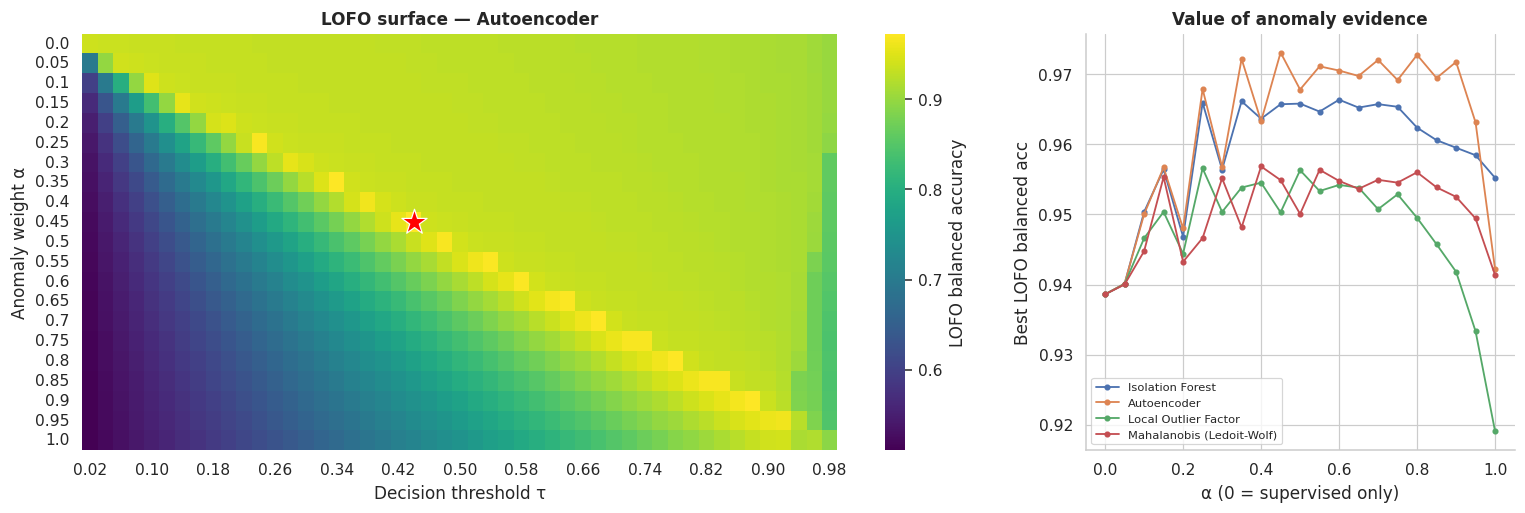

In [70]:
S = SURF[BEST_KIND]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [2.2, 1]})
sns.heatmap(S, xticklabels=[f'{t:.2f}' if k % 4 == 0 else '' for k, t in enumerate(TAUS)], yticklabels=ALPHAS,
            cmap='viridis', ax=ax[0], cbar_kws={'label': 'LOFO balanced accuracy'})
i, j = np.unravel_index(S.argmax(), S.shape)
ax[0].scatter(j + .5, i + .5, marker='*', s=300, c='red', edgecolor='w')
ax[0].set_xlabel('Decision threshold τ'); ax[0].set_ylabel('Anomaly weight α'); ax[0].set_title(f'LOFO surface — {BEST_KIND}')
for kind, S_ in SURF.items():
    ax[1].plot(ALPHAS, S_.max(1), marker='o', ms=3, label=kind)
ax[1].set_xlabel('α (0 = supervised only)'); ax[1].set_ylabel('Best LOFO balanced acc'); ax[1].legend(fontsize=7.5)
ax[1].set_title('Value of anomaly evidence')
savefig('fusion_surface')

### 63. Hybrid five-class decision rule evaluated on every split

In [71]:
CLF = REG[LOFO_MODEL]['model']
SCORE_FN = ANOM_FN[BEST_KIND]

def hybrid_from_X(X, clf=None, score_fn=None):
    clf = CLF if clf is None else clf
    score_fn = SCORE_FN if score_fn is None else score_fn
    P = proba_of(clf, X)
    fused = (1 - ALPHA) * (1 - P[:, 0]) + ALPHA * score_fn(X)
    att = fused > TAU
    pred = np.where(att, P[:, 1:].argmax(1) + 1, 0)
    Ph = np.column_stack([1 - fused, P[:, 1:] / P[:, 1:].sum(1, keepdims=True).clip(1e-12) * fused[:, None]])
    return Ph, pred

def hybrid_predict(df):
    return hybrid_from_X(FB.transform(df))

HY = {k: hybrid_from_X(XS[k]) for k in XS}
HYB = f'LOFO-Hybrid ({LOFO_MODEL} + {BEST_KIND})'
register(HYB, {k: v[0] for k, v in HY.items()}, pred={k: v[1] for k, v in HY.items()}, fit_s=REG[LOFO_MODEL]['fit_s'], kind='hybrid')
t = time.time(); hybrid_from_X(XS['te']); REG[HYB]['inf_ms'] = (time.time() - t) / len(Xte) * 1e6
REG[HYB]['size_kb'] = REG[LOFO_MODEL]['size_kb']
save_table(show([LOFO_MODEL, HYB]), 'T32_hybrid_tvt')
display(board([LOFO_MODEL, HYB], 'te')[['Acc', 'MacroF1', 'BinAcc', 'DR', 'FAR', 'ZeroDayDR']].round(4))

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,1.0000,1.0000,0.9994,0.9759,0.7811,0.5452,0.5836,0.4573,58.0517
LOFO-Hybrid (Tuned LightGBM + Autoencoder),0.9882,0.8763,0.9885,0.8708,0.8386,0.7112,0.6949,0.6279,58.0517


,Acc,MacroF1,BinAcc,DR,FAR,ZeroDayDR
Tuned LightGBM,0.7811,0.5452,0.7908,0.6532,0.0275,0.3664
LOFO-Hybrid (Tuned LightGBM + Autoencoder),0.8386,0.7112,0.9028,0.8946,0.0865,0.7827


### 64. Open-set recognition: rejecting low-confidence traffic as an unknown attack

In [72]:
P = REG[HYB]['P']
conf_va = P['va'].max(1)
correct = REG[HYB]['pred']['va'] == yva
Q = np.quantile(conf_va[correct], 0.01)
rows = []
for k in ('va', 'te', 't21'):
    unk = P[k].max(1) < Q
    pred_os = np.where(unk, 1, REG[HYB]['pred'][k])
    r = {'Split': SPL[k], 'Rejected as unknown (%)': 100 * unk.mean(),
         'Binary acc (closed set)': accuracy_score(YS[k] > 0, REG[HYB]['pred'][k] > 0),
         'Binary acc (open set)': accuracy_score(YS[k] > 0, pred_os > 0)}
    if k in NOVEL:
        r['Zero-day rows rejected (%)'] = 100 * unk[NOVEL[k]].mean()
        r['Seen rows rejected (%)'] = 100 * unk[~NOVEL[k]].mean()
    rows.append(r)
print(f'Confidence threshold (1st percentile of correct validation predictions) = {Q:.4f}')
display(save_table(pd.DataFrame(rows).set_index('Split').round(3), 'T33_open_set'))

Confidence threshold (1st percentile of correct validation predictions) = 0.5683


,Rejected as unknown (%),Binary acc (closed set),Binary acc (open set),Zero-day rows rejected (%),Seen rows rejected (%)
Split,,,,,
Validation,2.131,0.989,0.979,NaN,NaN
KDDTest+,16.856,0.903,0.912,38.720,12.493
KDDTest-21,31.688,0.817,0.837,38.824,28.397


### 65. Leave-one-family-out generalisation matrix

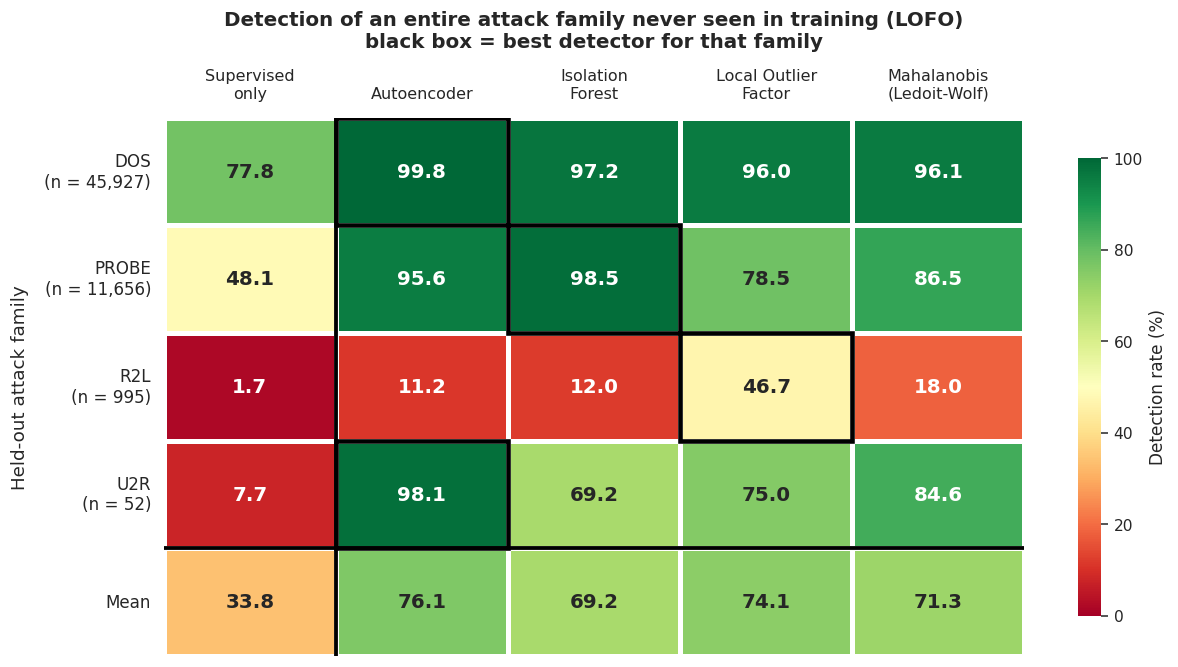

In [73]:
import textwrap
from matplotlib.patches import Rectangle

LD = pd.DataFrame(LOFO_DET)
M = LD.pivot_table(index='Held-out family', columns='Scorer', values='Anomaly-only DR on unseen family')
M.insert(0, 'Supervised only', LD.groupby('Held-out family')['Supervised-only DR on unseen family'].first())
M = M.reindex(LOFO_FAMS) * 100
M.loc['Mean'] = M.mean()
save_table(M.round(2), 'T34_lofo_matrix')

n_held = {f: int((LOFO[f][1]['cat'] == f).sum()) for f in LOFO_FAMS}
row_labels = [f'{f.upper()}\n(n = {n_held[f]:,})' for f in LOFO_FAMS] + ['Mean']
col_labels = ['\n'.join(textwrap.wrap(c, 14)) for c in M.columns]

fig, ax = plt.subplots(figsize=(11.5, 6.2))
sns.heatmap(M, annot=True, fmt='.1f', cmap='RdYlGn', vmin=0, vmax=100, linewidths=2, linecolor='white',
            annot_kws={'size': 13, 'weight': 'bold'}, cbar_kws={'label': 'Detection rate (%)', 'shrink': 0.85}, ax=ax)

for i, f in enumerate(LOFO_FAMS):
    j = int(np.argmax(M.loc[f].values))
    ax.add_patch(Rectangle((j, i), 1, 1, fill=False, ec='black', lw=3))

ax.axhline(len(LOFO_FAMS), color='black', lw=2.5)
ax.axvline(1, color='black', lw=2.5)

ax.set_yticklabels(row_labels, rotation=0, fontsize=11, va='center')
ax.set_xticklabels(col_labels, rotation=0, fontsize=10.5, ha='center')
ax.tick_params(axis='x', bottom=False, top=False, labelbottom=False, labeltop=True, pad=6)
ax.set_xlabel('')
ax.set_ylabel('Held-out attack family', fontsize=12, labelpad=10)
ax.set_title('Detection of an entire attack family never seen in training (LOFO)\n'
             'black box = best detector for that family', fontsize=13, fontweight='bold', pad=14)
savefig('lofo_generalisation_matrix')

### 66. Per zero-day attack-name detection breakdown

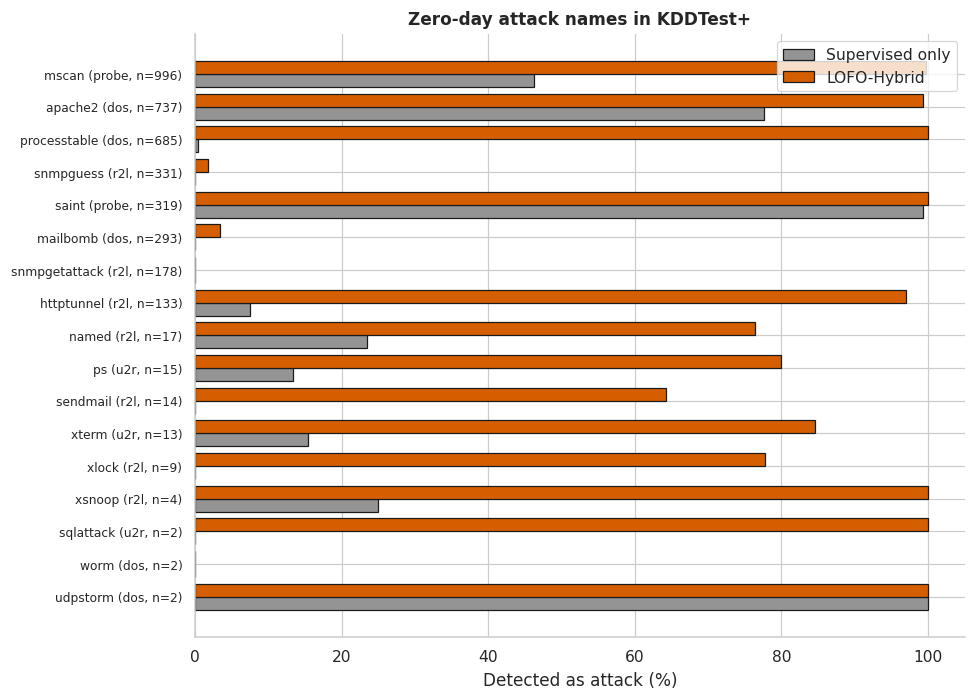

,Records,Zero-day,Nearest training neighbour is normal (%),Identical to a training normal row (%),Median distance to nearest training row,Detected by LOFO-Hybrid (%)
label,,,,,,
guess_passwd,1231,False,83.83,0.00,3.10,81.72
warezmaster,944,False,83.37,0.00,1.84,68.54
snmpguess,331,True,99.40,0.00,0.54,1.81
snmpgetattack,178,True,99.44,15.17,0.02,0.00
httptunnel,133,True,86.47,0.00,3.97,96.99
multihop,18,False,83.33,0.00,2.71,61.11
named,17,True,64.71,0.00,4.91,76.47
sendmail,14,True,92.86,0.00,3.95,64.29
xlock,9,True,88.89,0.00,1.58,77.78


86.4% of KDDTest+ R2L records have a normal record as their nearest training neighbour; 0.9% are feature-identical to a training normal record.


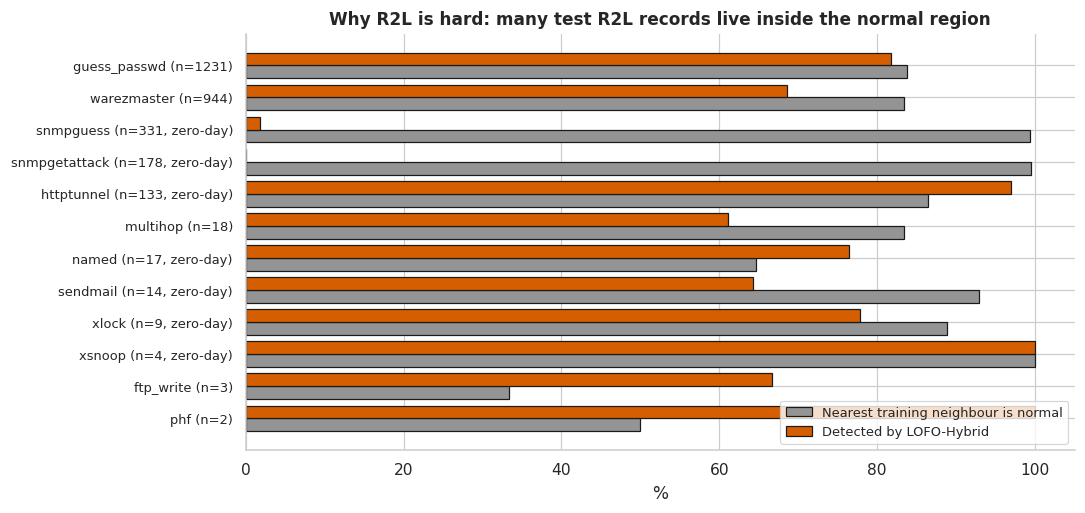

In [74]:
nv = tst[NOVEL['te']].copy()
nv['Supervised'] = REG[LOFO_MODEL]['pred']['te'][NOVEL['te']] > 0
nv['LOFO-Hybrid'] = REG[HYB]['pred']['te'][NOVEL['te']] > 0
ZD = nv.groupby(['label', 'cat'])[['Supervised', 'LOFO-Hybrid']].mean().mul(100)
ZD['Records'] = nv.groupby(['label', 'cat']).size()
ZD = ZD.sort_values('Records', ascending=True)
save_table(ZD.round(2), 'T35_zero_day_breakdown')
fig, ax = plt.subplots(figsize=(9, 6.5))
y = np.arange(len(ZD))
ax.barh(y - .2, ZD['Supervised'], .4, label='Supervised only', color=PAL[7], edgecolor='k')
ax.barh(y + .2, ZD['LOFO-Hybrid'], .4, label='LOFO-Hybrid', color=PAL[3], edgecolor='k')
ax.set_yticks(y); ax.set_yticklabels([f'{l} ({c}, n={n})' for (l, c), n in zip(ZD.index, ZD['Records'])], fontsize=8)
ax.set_xlabel('Detected as attack (%)'); ax.legend(); ax.set_title('Zero-day attack names in KDDTest+')
savefig('zero_day_breakdown')

r2l_te = tst[(tst['cat'] == 'r2l').values].copy()
nn_ = NearestNeighbors(n_neighbors=1).fit(Xtr)
d_, j_ = nn_.kneighbors(FB.transform(r2l_te))
r2l_te['nn_label'] = np.array(CLASSES)[ytr[j_[:, 0]]]
r2l_te['nn_dist'] = d_[:, 0]
r2l_te['identical_to_train_normal'] = np.isin(row_hash(r2l_te), row_hash(TR[TR['cat'] == 'normal']))
r2l_te['detected'] = REG[HYB]['pred']['te'][(tst['cat'] == 'r2l').values] > 0
R2LA = r2l_te.groupby('label').agg(**{'Records': ('label', 'size'),
    'Zero-day': ('label', lambda s: s.iloc[0] not in SEEN),
    'Nearest training neighbour is normal (%)': ('nn_label', lambda s: 100 * (s == 'normal').mean()),
    'Identical to a training normal row (%)': ('identical_to_train_normal', lambda s: 100 * s.mean()),
    'Median distance to nearest training row': ('nn_dist', 'median'),
    'Detected by LOFO-Hybrid (%)': ('detected', lambda s: 100 * s.mean())}).sort_values('Records', ascending=False)
display(save_table(R2LA.round(2), 'T35b_r2l_indistinguishability'))
share = (r2l_te['nn_label'] == 'normal').mean()
print(f'{100 * share:.1f}% of KDDTest+ R2L records have a normal record as their nearest training neighbour; '
      f'{100 * r2l_te["identical_to_train_normal"].mean():.1f}% are feature-identical to a training normal record.')
fig, ax = plt.subplots(figsize=(10, 4.8))
top = R2LA.head(12).iloc[::-1]
y_ = np.arange(len(top))
ax.barh(y_ - .2, top['Nearest training neighbour is normal (%)'], .4, color=PAL[7], edgecolor='k', label='Nearest training neighbour is normal')
ax.barh(y_ + .2, top['Detected by LOFO-Hybrid (%)'], .4, color=PAL[3], edgecolor='k', label='Detected by LOFO-Hybrid')
ax.set_yticks(y_); ax.set_yticklabels([f"{n} (n={int(r['Records'])}{', zero-day' if r['Zero-day'] else ''})" for n, r in top.iterrows()], fontsize=8.5)
ax.set_xlabel('%'); ax.legend(fontsize=8.5, loc='lower right'); ax.set_title('Why R2L is hard: many test R2L records live inside the normal region')
savefig('r2l_indistinguishability')

### 67. Mondrian (class-conditional) conformal prediction sets

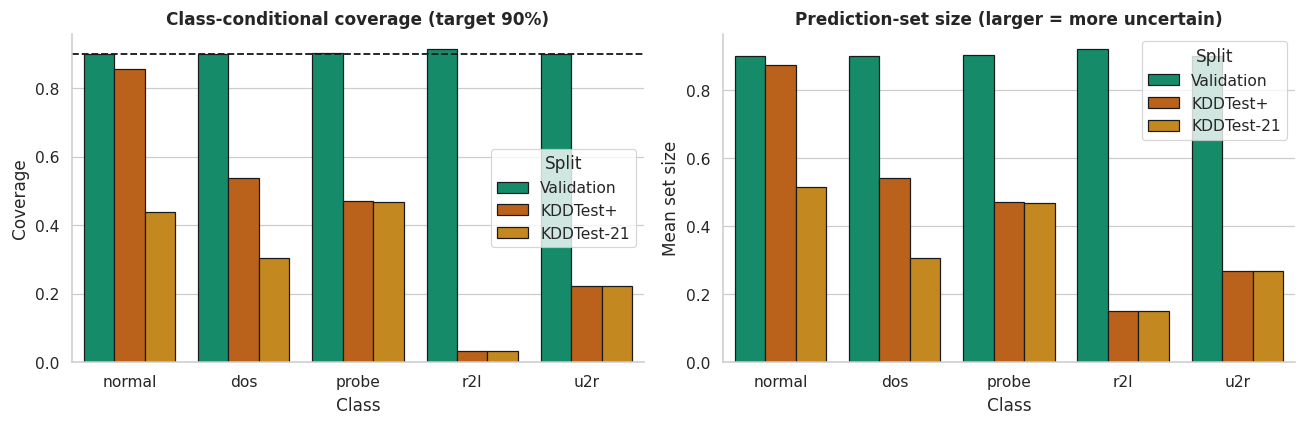

In [75]:
ALPHA_CP = 0.1
def mondrian_q(P, y):
    return np.array([np.quantile(1 - P[y == c, c], min(1, (1 - ALPHA_CP) * (1 + 1 / max((y == c).sum(), 1)))) if (y == c).any() else 1.0
                     for c in range(5)])
def cp_sets(P, q):
    return (1 - P) <= q
P = REG[BEST_SUP]['P']
cov_va = np.zeros(len(yva), bool); size_va = np.zeros(len(yva))
for a, b in StratifiedKFold(2, shuffle=True, random_state=SEED).split(P['va'], np.minimum(yva, 3)):
    S_ = cp_sets(P['va'][b], mondrian_q(P['va'][a], yva[a]))
    cov_va[b] = S_[np.arange(len(b)), yva[b]]; size_va[b] = S_.sum(1)
QCP = mondrian_q(P['va'], yva)
rows = []
for k, cov, size in [('va', cov_va, size_va)] + [(k, cp_sets(P[k], QCP)[np.arange(len(YS[k])), YS[k]], cp_sets(P[k], QCP).sum(1)) for k in ('te', 't21')]:
    for c in range(5):
        m = YS[k] == c
        rows.append({'Split': SPL[k], 'Class': CLASSES[c], 'Coverage': cov[m].mean() if m.any() else np.nan, 'Mean set size': size[m].mean() if m.any() else np.nan})
CP = save_table(pd.DataFrame(rows), 'T36_conformal')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=CP, x='Class', y='Coverage', hue='Split', ax=ax[0], palette=[PAL[2], PAL[3], PAL[1]], edgecolor='k')
ax[0].axhline(1 - ALPHA_CP, ls='--', c='k'); ax[0].set_title(f'Class-conditional coverage (target {1 - ALPHA_CP:.0%})')
sns.barplot(data=CP, x='Class', y='Mean set size', hue='Split', ax=ax[1], palette=[PAL[2], PAL[3], PAL[1]], edgecolor='k')
ax[1].set_title('Prediction-set size (larger = more uncertain)')
savefig('conformal_coverage')

### 68. Conformal anomaly p-values with Benjamini–Hochberg false-discovery control

In [76]:
def bh(p, q=0.1):
    o = np.argsort(p); n = len(p)
    thr = q * np.arange(1, n + 1) / n
    ok = p[o] <= thr
    k = np.where(ok)[0].max() + 1 if ok.any() else 0
    out = np.zeros(n, bool); out[o[:k]] = True
    return out
s = ANOM[BEST_KIND]
rows = []
cal_all = s['va'][yva == 0]
half = np.random.RandomState(SEED).permutation(np.where(yva == 0)[0])
cal_a, hold = half[: len(half) // 2], half[len(half) // 2:]
for k in ('va', 'te', 't21'):
    cal = np.sort(s['va'][cal_a]) if k == 'va' else np.sort(cal_all)
    mask = np.ones(len(YS[k]), bool)
    if k == 'va':
        mask[cal_a] = False
    sc = s[k][mask]
    pv = (1 + len(cal) - np.searchsorted(cal, sc, side='left')) / (len(cal) + 1)
    flag = bh(pv, 0.1)
    yb = YS[k][mask] > 0
    rows.append({'Split': SPL[k], 'Flagged (%)': 100 * flag.mean(), 'Detection rate': flag[yb].mean(), 'False alarm rate': flag[~yb].mean(),
                 'Realised FDR': (~yb[flag]).mean() if flag.any() else 0, 'Target FDR': 0.1})
display(save_table(pd.DataFrame(rows).set_index('Split').round(4), 'T37_conformal_anomaly_bh'))

,Flagged (%),Detection rate,False alarm rate,Realised FDR,Target FDR
Split,,,,,
Validation,65.0344,0.9834,0.0705,0.0396,0.1
KDDTest+,55.3673,0.8973,0.0996,0.0775,0.1
KDDTest-21,82.0506,0.8977,0.4726,0.1046,0.1


## Part I — Ensembles, validation-only model selection and official test results

### 69. Validation-optimised weighted soft voting (cross-fitted)

In [77]:
PROB_MODELS = [n for n in REG if REG[n]['kind'] in ('model', 'deep')]
MEMBERS = sorted(PROB_MODELS, key=lambda n: -scores(yva, REG[n]['P']['va'])['MacroF1'])[:5]
def wv_tune(Ps, y):
    def loss(v):
        w = softmax(v[None])[0]
        return log_loss(y, np.clip(sum(wi * P for wi, P in zip(w, Ps)), 1e-9, 1), labels=range(5))
    return softmax(minimize(loss, np.zeros(len(Ps)), method='Nelder-Mead', options={'maxiter': 400}).x[None])[0]
Pv = [REG[n]['P']['va'] for n in MEMBERS]
va_P = np.zeros_like(Pv[0])
for a, b in StratifiedKFold(2, shuffle=True, random_state=SEED).split(Pv[0], np.minimum(yva, 3)):
    w = wv_tune([P[a] for P in Pv], yva[a])
    va_P[b] = sum(wi * P[b] for wi, P in zip(w, Pv))
WV = wv_tune(Pv, yva)
P = {k: sum(wi * REG[n]['P'][k] for wi, n in zip(WV, MEMBERS)) for k in ('tr', 'te', 't21')}
P['va'] = va_P
register('Weighted soft voting', P, fit_s=sum(REG[n]['fit_s'] for n in MEMBERS), size_kb=sum(np.nan_to_num(REG[n]['size_kb']) for n in MEMBERS), kind='ensemble')
display(pd.Series(WV, index=MEMBERS).rename('Weight').to_frame().round(3))
show(MEMBERS + ['Weighted soft voting'])

,Weight
Tuned LightGBM,0.767
HGB class-weighted,0.000
XGBoost,0.055
Decision Tree,0.049
CatBoost,0.128


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,1.0000,1.0000,0.9994,0.9759,0.7811,0.5452,0.5836,0.4573,58.0517
HGB class-weighted,0.9999,0.9999,0.9991,0.9652,0.7897,0.6055,0.6006,0.5195,13.6699
XGBoost,1.0000,1.0000,0.9992,0.9525,0.7814,0.5727,0.5842,0.4848,49.1941
Decision Tree,1.0000,1.0000,0.9984,0.9518,0.7807,0.5776,0.5868,0.4908,1.4844
CatBoost,0.9999,0.9999,0.9990,0.9508,0.7837,0.5703,0.5885,0.4830,219.0677
Weighted soft voting,1.0000,1.0000,0.9994,0.9754,0.7814,0.5496,0.5842,0.4617,341.4677


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,0.99995,0.999977,0.999444,0.975897,0.781139,0.545213,0.583629,0.457299,58.051661
HGB class-weighted,0.99990,0.999907,0.999087,0.965228,0.789700,0.605487,0.600591,0.519498,13.669891
XGBoost,0.99995,0.999977,0.999206,0.952547,0.781450,0.572657,0.584219,0.484791,49.194127
Decision Tree,1.00000,1.000000,0.998412,0.951800,0.780696,0.577617,0.586835,0.490840,1.484362
CatBoost,0.99990,0.999911,0.998968,0.950819,0.783667,0.570282,0.588523,0.482982,219.067683
Weighted soft voting,0.99995,0.999977,0.999405,0.975378,0.781450,0.549627,0.584219,0.461748,341.467724


### 70. Out-of-fold stacking with a multinomial meta-learner

In [78]:
BASES = [n for n in ['Hist Gradient Boosting', 'Random Forest', 'Extra Trees', 'LightGBM', 'XGBoost'] if n in FACTORY][:3]
K = 5 if not FAST else 3
OOF = np.zeros((len(Xtr), 5 * len(BASES)))
for a, b in StratifiedKFold(K, shuffle=True, random_state=SEED).split(Xtr, ytr):
    for j, n in enumerate(BASES):
        OOF[b, 5 * j: 5 * j + 5] = proba_of(factory(n).fit(Xtr[a], ytr[a]), Xtr[b])
meta = LogisticRegression(max_iter=3000, C=0.5).fit(np.log(OOF + 1e-6), ytr)
LVL1 = {k: np.hstack([REG[n]['P'][k] for n in BASES]) for k in XS}
LVL1['tr'] = OOF[TRI]
P = {k: meta.predict_proba(np.log(v + 1e-6)) for k, v in LVL1.items()}
register('OOF stacking', P, fit_s=sum(REG[n]['fit_s'] for n in BASES) * (K + 1), kind='ensemble')
show(BASES + ['OOF stacking'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Hist Gradient Boosting,0.9962,0.8251,0.9948,0.7957,0.7814,0.5697,0.5842,0.4832,6.9638
Random Forest,1.0000,1.0000,0.9989,0.9290,0.7802,0.5335,0.5820,0.4452,22.1930
Extra Trees,1.0000,1.0000,0.9988,0.9270,0.7575,0.5272,0.5435,0.4288,20.9257
OOF stacking,0.9989,0.9549,0.9992,0.9304,0.7802,0.5520,0.5836,0.4553,300.4952


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Hist Gradient Boosting,0.99615,0.825097,0.994761,0.795698,0.781361,0.569676,0.584219,0.483155,6.963837
Random Forest,0.99995,0.999977,0.998889,0.928986,0.780163,0.533465,0.582025,0.445193,22.192972
Extra Trees,1.00000,1.000000,0.998809,0.926993,0.757541,0.527244,0.543460,0.428828,20.925725
OOF stacking,0.99890,0.954924,0.999246,0.930407,0.780163,0.552044,0.583629,0.455332,300.495207


### 71. Dynamic ensemble selection by local competence (KNORA-Eliminate)

In [79]:
pca = PCA(20, random_state=SEED).fit(Xtr)
ref = np.random.RandomState(SEED).choice(len(Xtr), min(len(Xtr), 30000), replace=False)
NNI = NearestNeighbors(n_neighbors=9).fit(pca.transform(Xtr[ref]))
correct = np.stack([OOF[ref, 5 * j: 5 * j + 5].argmax(1) == ytr[ref] for j in range(len(BASES))], 1)
def knora(X, Pbase):
    _, nb = NNI.kneighbors(pca.transform(X))
    out = np.zeros((len(X), 5))
    for k in (9, 7, 5, 3, 1):
        comp = correct[nb[:, :k]].all(1)
        todo = (out.sum(1) == 0) & comp.any(1)
        for i in np.where(todo)[0]:
            out[i] = np.mean([Pbase[j][i] for j in np.where(comp[i])[0]], 0)
    rest = out.sum(1) == 0
    out[rest] = np.mean([P[rest] for P in Pbase], 0)
    return out
P = {k: knora(XS[k], [REG[n]['P'][k] for n in BASES]) for k in XS}
register('KNORA-E dynamic selection', P, kind='ensemble')
show(BASES + ['KNORA-E dynamic selection'])

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Hist Gradient Boosting,0.9962,0.8251,0.9948,0.7957,0.7814,0.5697,0.5842,0.4832,6.9638
Random Forest,1.0000,1.0000,0.9989,0.9290,0.7802,0.5335,0.5820,0.4452,22.1930
Extra Trees,1.0000,1.0000,0.9988,0.9270,0.7575,0.5272,0.5435,0.4288,20.9257
KNORA-E dynamic selection,0.9998,0.9975,0.9990,0.9140,0.7763,0.5372,0.5743,0.4486,NaN


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Hist Gradient Boosting,0.99615,0.825097,0.994761,0.795698,0.781361,0.569676,0.584219,0.483155,6.963837
Random Forest,0.99995,0.999977,0.998889,0.928986,0.780163,0.533465,0.582025,0.445193,22.192972
Extra Trees,1.00000,1.000000,0.998809,0.926993,0.757541,0.527244,0.543460,0.428828,20.925725
KNORA-E dynamic selection,0.99975,0.997471,0.998968,0.913978,0.776260,0.537224,0.574346,0.448632,NaN


### 72. Validation-only model-selection leaderboard with a pre-declared rule

Selection rule (declared before looking at KDDTest+):
  1) category layer = tree model (factory or tuned) with the highest validation macro-F1;
  2) adopt anomaly fusion only if it raises leave-one-family-out balanced accuracy.
Selected final system: LOFO-Hybrid (Tuned LightGBM + Autoencoder)


,Acc,MacroF1,BalAcc,MCC,BinAcc,LOFO balanced acc
Cost-sensitive Tuned LightGBM,0.9994,0.9871,0.9766,0.9990,0.9994,NaN
Tuned LightGBM,0.9994,0.9759,0.9566,0.9990,0.9994,0.9386
Weighted soft voting,0.9994,0.9754,0.9555,0.9990,0.9994,NaN
Specialist-gated ensemble,0.9994,0.9660,0.9565,0.9989,0.9994,NaN
HGB class-weighted,0.9991,0.9652,0.9551,0.9984,0.9992,NaN
Tuned LightGBM + class scaling,0.9993,0.9627,0.9366,0.9988,0.9993,NaN
XGBoost,0.9992,0.9525,0.9344,0.9986,0.9992,NaN
Decision Tree,0.9984,0.9518,0.9519,0.9972,0.9987,NaN
CatBoost,0.9990,0.9508,0.9311,0.9982,0.9990,NaN
HGB + SMOTE,0.9992,0.9498,0.9553,0.9985,0.9992,NaN


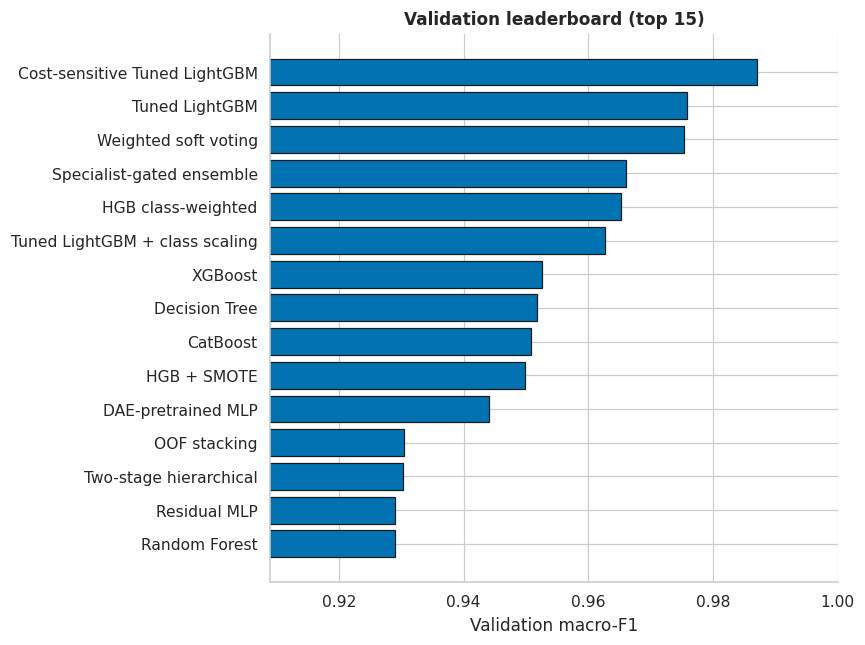

In [80]:
VB = board(list(REG), 'va').sort_values('MacroF1', ascending=False)
LOFO_SCORE = {HYB: LOFO_TAB.loc[BEST_KIND, 'LOFO balanced acc (hybrid)'], LOFO_MODEL: LOFO_TAB.loc[BEST_KIND, 'LOFO balanced acc (supervised only, tuned τ)']}
VB['LOFO balanced acc'] = pd.Series(LOFO_SCORE)
save_table(VB.round(4), 'T38_validation_leaderboard')
FINAL = HYB if LOFO_TAB.loc[BEST_KIND, 'Gain'] > 0 else best_by_val(PROB_MODELS)
print('Selection rule (declared before looking at KDDTest+):')
print('  1) category layer = tree model (factory or tuned) with the highest validation macro-F1;')
print('  2) adopt anomaly fusion only if it raises leave-one-family-out balanced accuracy.')
print('Selected final system:', FINAL)
display(VB.head(12)[['Acc', 'MacroF1', 'BalAcc', 'MCC', 'BinAcc', 'LOFO balanced acc']].round(4))
top = VB.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top['MacroF1'], color=[PAL[3] if n == FINAL else PAL[0] for n in top.index], edgecolor='k')
plt.xlim(top['MacroF1'].min() - .02, 1); plt.xlabel('Validation macro-F1'); plt.title('Validation leaderboard (top 15)')
savefig('validation_leaderboard')

### 73. Complete train / validation / test accuracy table for every model

,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Cost-sensitive Tuned LightGBM,1.0000,1.0000,0.9994,0.9871,0.7939,0.5928,0.6079,0.5059,NaN
Tuned LightGBM,1.0000,1.0000,0.9994,0.9759,0.7811,0.5452,0.5836,0.4573,58.0517
Weighted soft voting,1.0000,1.0000,0.9994,0.9754,0.7814,0.5496,0.5842,0.4617,341.4677
Specialist-gated ensemble,1.0000,1.0000,0.9994,0.9660,0.7876,0.5634,0.5959,0.4760,NaN
HGB class-weighted,0.9999,0.9999,0.9991,0.9652,0.7897,0.6055,0.6006,0.5195,13.6699
Tuned LightGBM + class scaling,1.0000,1.0000,0.9993,0.9627,0.7874,0.5741,0.5956,0.4861,NaN
XGBoost,1.0000,1.0000,0.9992,0.9525,0.7814,0.5727,0.5842,0.4848,49.1941
Decision Tree,1.0000,1.0000,0.9984,0.9518,0.7807,0.5776,0.5868,0.4908,1.4844
CatBoost,0.9999,0.9999,0.9990,0.9508,0.7837,0.5703,0.5885,0.4830,219.0677
HGB + SMOTE,1.0000,0.9999,0.9992,0.9498,0.7983,0.6345,0.6165,0.5466,40.3226


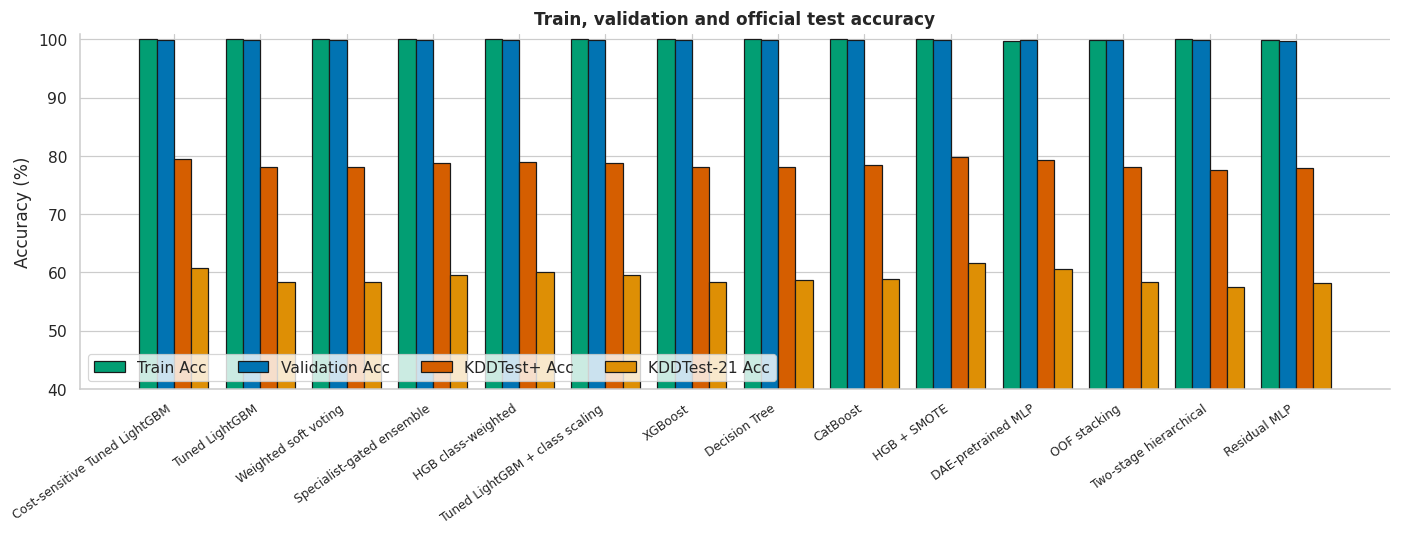

In [81]:
TVT = save_table(tvt(list(REG)).sort_values('Validation MacroF1', ascending=False), 'T39_train_val_test_all_models')
display(TVT.round(4))
top = TVT.head(14)
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(top)); w = .2
for i, (col, c) in enumerate([('Train Acc', PAL[2]), ('Validation Acc', PAL[0]), ('KDDTest+ Acc', PAL[3]), ('KDDTest-21 Acc', PAL[1])]):
    ax.bar(x + (i - 1.5) * w, 100 * top[col], w, label=col, color=c, edgecolor='k')
ax.set_xticks(x); ax.set_xticklabels(top.index, rotation=35, ha='right', fontsize=8); ax.set_ylim(40, 101)
ax.set_ylabel('Accuracy (%)'); ax.legend(ncol=4, loc='lower left'); ax.set_title('Train, validation and official test accuracy')
savefig('train_val_test_accuracy')

### 74. Official KDDTest+ and KDDTest-21 evaluation of the selected system

In [82]:
OFF = pd.DataFrame({SPL[k]: scores(YS[k], REG[FINAL]['P'][k], REG[FINAL]['pred'][k], k) for k in ('tr', 'va', 'te', 't21')}).T
display(save_table(OFF.round(4), 'T40_final_official'))
for k in ('te', 't21'):
    print(f'{SPL[k]} per-class report')
    print(classification_report(YS[k], REG[FINAL]['pred'][k], target_names=CLASSES, digits=4, zero_division=0))

,Acc,BalAcc,MacroF1,WeightedF1,MCC,BinAcc,DR,FAR,AUC,ZeroDayDR
Train,0.9882,0.9956,0.8763,0.9886,0.9795,0.9882,1.0000,0.0220,1.0000,NaN
Validation,0.9885,0.9927,0.8708,0.9888,0.9802,0.9885,0.9999,0.0214,1.0000,NaN
KDDTest+,0.8386,0.7061,0.7112,0.8319,0.7640,0.9028,0.8946,0.0865,0.9643,0.7827
KDDTest-21,0.6949,0.6295,0.6279,0.6890,0.5978,0.8170,0.8606,0.3796,0.8173,0.7821


KDDTest+ per-class report
              precision    recall  f1-score   support

      normal     0.8677    0.9135    0.8900      9711
         dos     0.8967    0.8755    0.8860      7460
       probe     0.6339    0.9203    0.7507      2421
         r2l     0.8469    0.4333    0.5733      2885
         u2r     0.5532    0.3881    0.4561        67

    accuracy                         0.8386     22544
   macro avg     0.7597    0.7061    0.7112     22544
weighted avg     0.8486    0.8386    0.8319     22544

KDDTest-21 per-class report
              precision    recall  f1-score   support

      normal     0.4968    0.6204    0.5518      2152
         dos     0.8199    0.7861    0.8027      4344
       probe     0.6351    0.9197    0.7514      2402
         r2l     0.8480    0.4333    0.5735      2885
         u2r     0.5652    0.3881    0.4602        67

    accuracy                         0.6949     11850
   macro avg     0.6730    0.6295    0.6279     11850
weighted avg     0.7292

### 75. Normalised five-class and binary confusion matrices

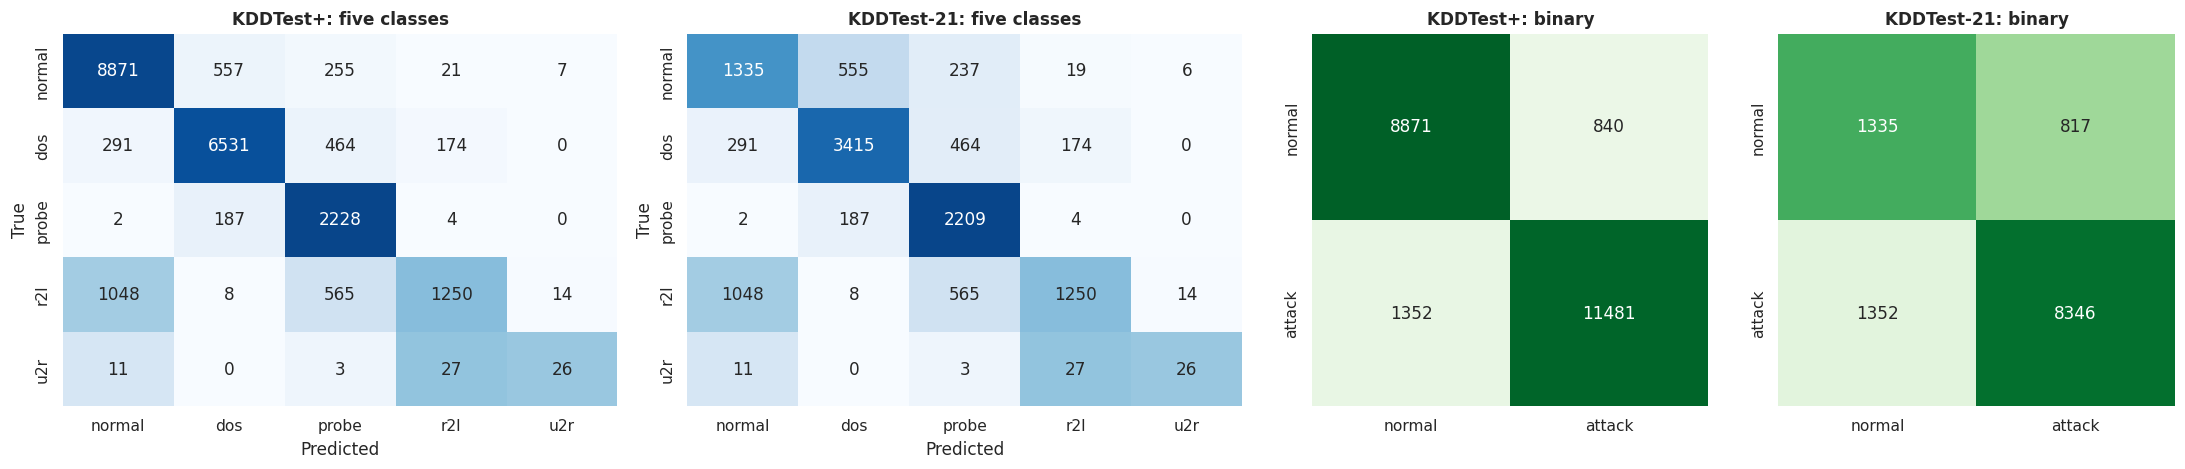

In [83]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.4), gridspec_kw={'width_ratios': [1.4, 1.4, 1, 1]})
for i, k in enumerate(['te', 't21']):
    cm = confusion_matrix(YS[k], REG[FINAL]['pred'][k], labels=range(5))
    sns.heatmap(cm / cm.sum(1, keepdims=True).clip(1), annot=cm, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES,
                ax=ax[i], cbar=False, vmin=0, vmax=1)
    ax[i].set_title(f'{SPL[k]}: five classes'); ax[i].set_xlabel('Predicted'); ax[i].set_ylabel('True')
    cb_ = confusion_matrix(YS[k] > 0, REG[FINAL]['pred'][k] > 0)
    sns.heatmap(cb_ / cb_.sum(1, keepdims=True), annot=cb_, fmt='d', cmap='Greens', xticklabels=['normal', 'attack'],
                yticklabels=['normal', 'attack'], ax=ax[2 + i], cbar=False, vmin=0, vmax=1)
    ax[2 + i].set_title(f'{SPL[k]}: binary')
savefig('final_confusion_matrices')

### 76. One-vs-rest ROC and precision–recall curves

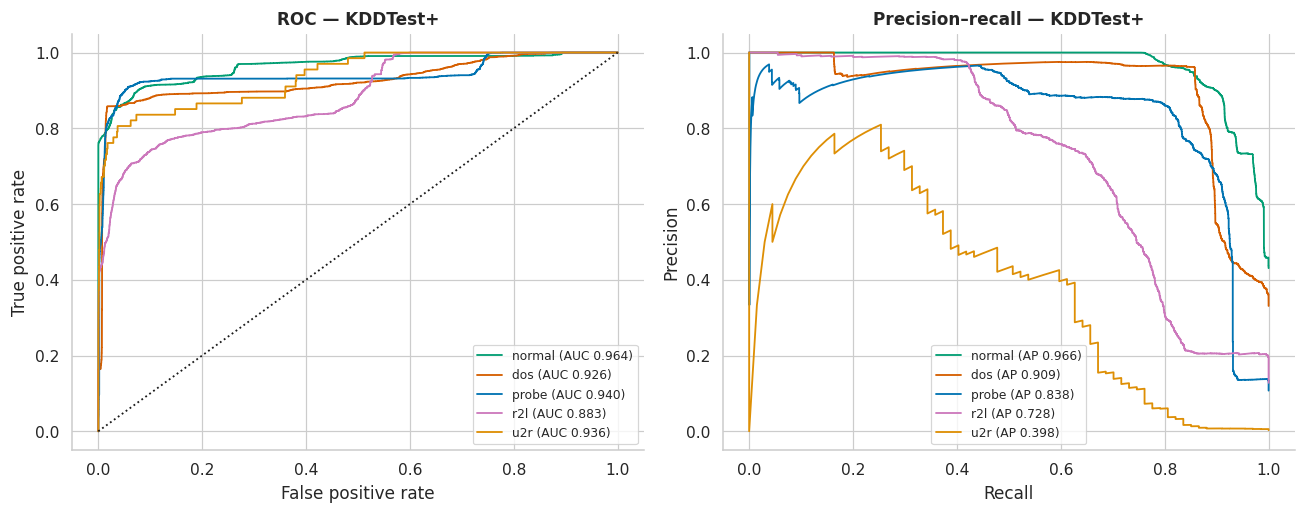

In [84]:
P = REG[FINAL]['P']['te']
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for c in range(5):
    yb = (yte == c).astype(int)
    fpr, tpr, _ = roc_curve(yb, P[:, c]); pr, rc, _ = precision_recall_curve(yb, P[:, c])
    ax[0].plot(fpr, tpr, color=CCOL[CLASSES[c]], label=f'{CLASSES[c]} (AUC {roc_auc_score(yb, P[:, c]):.3f})')
    ax[1].plot(rc, pr, color=CCOL[CLASSES[c]], label=f'{CLASSES[c]} (AP {average_precision_score(yb, P[:, c]):.3f})')
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].legend(fontsize=8)
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(fontsize=8)
ax[0].set_title('ROC — KDDTest+'); ax[1].set_title('Precision–recall — KDDTest+')
savefig('final_roc_pr')

### 77. Calibration: reliability diagrams, ECE and validation-fitted temperature scaling

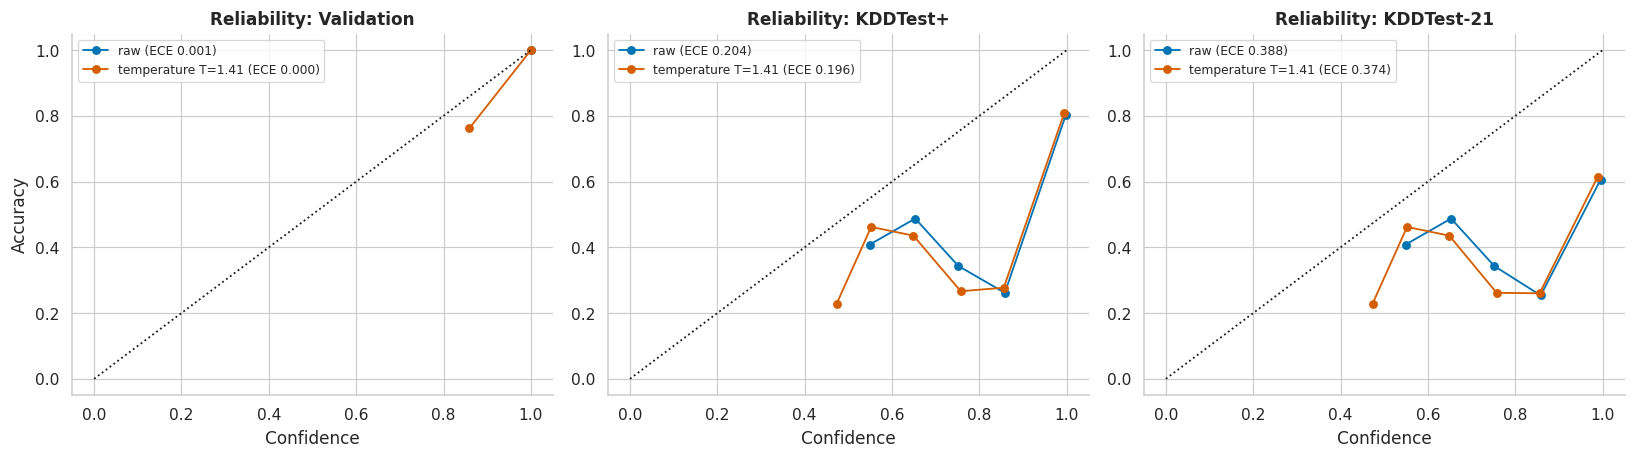

,Split,Variant,ECE,Log-loss
0,Validation,raw,0.0005,0.0027
1,Validation,temperature T=1.41,0.0003,0.0023
2,KDDTest+,raw,0.2041,1.9986
3,KDDTest+,temperature T=1.41,0.1962,1.4285
4,KDDTest-21,raw,0.3884,3.8021
5,KDDTest-21,temperature T=1.41,0.3737,2.7172


Calibration error grows 381x from validation to KDDTest+: confidence learned in-distribution does not transfer under shift.
Temperature scaling fitted on validation cannot repair shift-induced miscalibration; conformal and anomaly evidence are needed instead.


In [85]:
def ece(P, y, bins=15):
    c = P.max(1); acc = P.argmax(1) == y
    e = np.linspace(0, 1, bins + 1); out = 0
    for lo, hi in zip(e[:-1], e[1:]):
        m = (c > lo) & (c <= hi)
        out += m.mean() * abs(acc[m].mean() - c[m].mean()) if m.any() else 0
    return out
def temp(P, T):
    return softmax(np.log(P + 1e-12) / T)
def fit_T(P, y):
    return minimize(lambda t: log_loss(y, temp(P, t[0]), labels=range(5)), [1.0], bounds=[(0.05, 20)], method='L-BFGS-B').x[0]
P = REG[BEST_SUP]['P']
TEMP = fit_T(P['va'], yva)
rows = []
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a_, k in zip(ax, ['va', 'te', 't21']):
    for lab, PP, c in [('raw', P[k], PAL[0]), (f'temperature T={TEMP:.2f}', temp(P[k], TEMP), PAL[3])]:
        conf, acc = PP.max(1), PP.argmax(1) == YS[k]
        e = np.linspace(0, 1, 11); mids, accs = [], []
        for lo, hi in zip(e[:-1], e[1:]):
            m = (conf > lo) & (conf <= hi)
            if m.sum() > 20:
                mids.append(conf[m].mean()); accs.append(acc[m].mean())
        a_.plot(mids, accs, 'o-', color=c, label=f'{lab} (ECE {ece(PP, YS[k]):.3f})')
        rows.append({'Split': SPL[k], 'Variant': lab, 'ECE': ece(PP, YS[k]), 'Log-loss': log_loss(YS[k], np.clip(PP, 1e-9, 1), labels=range(5))})
    a_.plot([0, 1], [0, 1], 'k:'); a_.set_title(f'Reliability: {SPL[k]}'); a_.set_xlabel('Confidence'); a_.legend(fontsize=8)
ax[0].set_ylabel('Accuracy')
savefig('calibration')
display(save_table(pd.DataFrame(rows).round(4), 'T41_calibration'))
e_va, e_te = ece(P['va'], yva), ece(P['te'], yte)
print(f'Calibration error grows {e_te / max(e_va, 1e-9):.0f}x from validation to KDDTest+: confidence learned in-distribution does not transfer under shift.')
print('Temperature scaling fitted on validation cannot repair shift-induced miscalibration; conformal and anomaly evidence are needed instead.')

### 78. Accuracy as a function of record difficulty level

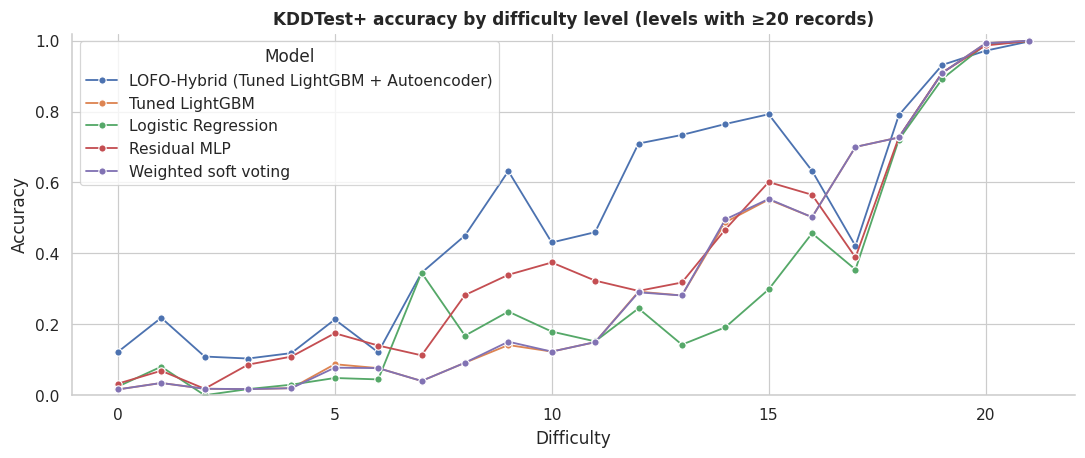

Normal records  False alarm rate (%)
File       Difficulty band                                      
KDDTest+   0–10 (hardest)              252                 98.81
           11–15                       163                 51.53
           16–18                      1248                 35.66
           19–21 (easiest)            8048                  0.77
KDDTest-21 0–10 (hardest)              252                 98.81
           11–15                       163                 51.53
           16–18                      1248                 35.66
           19–21 (easiest)             489                  7.98

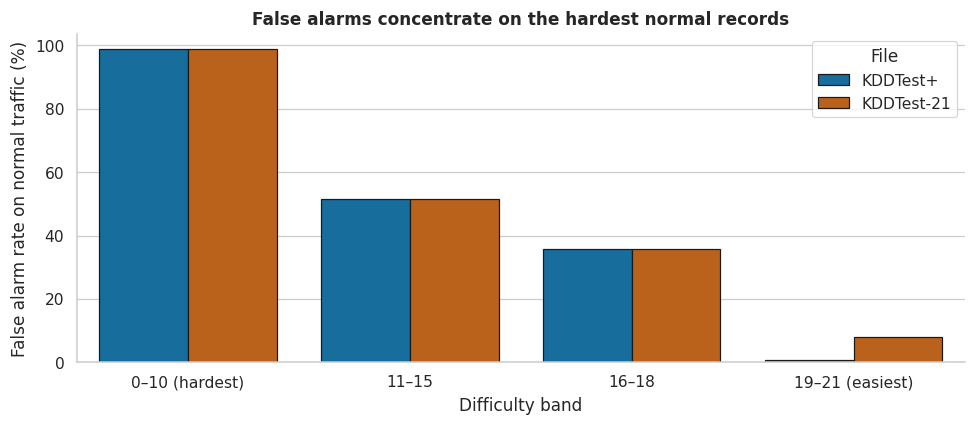

KDDTest-21 removes the easiest records, so its normal traffic is dominated by hard records; this explains its higher false-alarm rate.


In [86]:
show_names = [FINAL, LOFO_MODEL, 'Logistic Regression'] + [n for n in ['Residual MLP', 'Weighted soft voting'] if n in REG]
rows = []
for n in dict.fromkeys(show_names):
    for d_, g in tst.groupby('difficulty'):
        i = g.index.values
        rows.append({'Model': n, 'Difficulty': d_, 'Accuracy': accuracy_score(yte[i], REG[n]['pred']['te'][i]), 'Records': len(i)})
DF_ = save_table(pd.DataFrame(rows), 'T42_difficulty_accuracy')
plt.figure(figsize=(10, 4.3))
sns.lineplot(data=DF_[DF_.Records >= 20], x='Difficulty', y='Accuracy', hue='Model', marker='o')
plt.title('KDDTest+ accuracy by difficulty level (levels with ≥20 records)'); plt.ylim(0, 1.02)
savefig('difficulty_accuracy')

rows = []
for nm, d, yy, kk in [('KDDTest+', tst, yte, 'te'), ('KDDTest-21', t21, y21, 't21')]:
    pr = REG[FINAL]['pred'][kk]
    for band, (lo, hi) in {'0–10 (hardest)': (0, 10), '11–15': (11, 15), '16–18': (16, 18), '19–21 (easiest)': (19, 21)}.items():
        m = (yy == 0) & d['difficulty'].between(lo, hi).values
        if m.sum():
            rows.append({'File': nm, 'Difficulty band': band, 'Normal records': int(m.sum()), 'False alarm rate (%)': 100 * (pr[m] > 0).mean()})
FARD = save_table(pd.DataFrame(rows), 'T42b_false_alarms_by_difficulty')
display(FARD.set_index(['File', 'Difficulty band']).round(2))
plt.figure(figsize=(9, 4))
sns.barplot(data=FARD, x='Difficulty band', y='False alarm rate (%)', hue='File', palette=[PAL[0], PAL[3]], edgecolor='k')
plt.title('False alarms concentrate on the hardest normal records'); plt.ylabel('False alarm rate on normal traffic (%)')
savefig('false_alarms_by_difficulty')
print('KDDTest-21 removes the easiest records, so its normal traffic is dominated by hard records; this explains its higher false-alarm rate.')

### 79. Protocol-aware comparison with the 15 related works

,Dataset,Protocol,5-class accuracy (%),Macro-F1,Binary accuracy (%),Directly comparable
Work,,,,,,
P1 Jain et al. 2026: CNN-LSTM,NSL-KDD,B (official KDDTest+),77.610000,0.606800,79.360000,Yes
P1 Jain et al. 2026: SVM (RBF),NSL-KDD,B (official KDDTest+),NaN,NaN,81.050000,Yes
P1 Jain et al. 2026: Gradient Boosting,NSL-KDD,B (official KDDTest+),NaN,NaN,80.730000,Yes
P1 Jain et al. 2026: CNN-LSTM,NSL-KDD,A (70/15/15 of KDDTrain+),NaN,NaN,99.280000,Protocol A only
P2 Suresh Kumar et al. 2026: DNN,NSL-KDD,A (80:20 of KDDTrain+),99.960000,NaN,NaN,Protocol A only
P3 Ghosh et al. 2026: MLA-DRMCNN,NSL-KDD (augmented),A (random split),99.990000,NaN,NaN,Protocol A only
P4 Al Khulayf et al. 2026: KNN+RF ensemble,CICIDS2017,random split,NaN,NaN,NaN,No (other dataset)
P5 Antony et al. 2026: optimised SVM,NSL-KDD,A (80:20 of KDDTrain+),99.100000,NaN,NaN,Protocol A only
P6 Dardouri 2026: optimised LSTM,CICIDS2017,random split,NaN,NaN,NaN,No (other dataset)


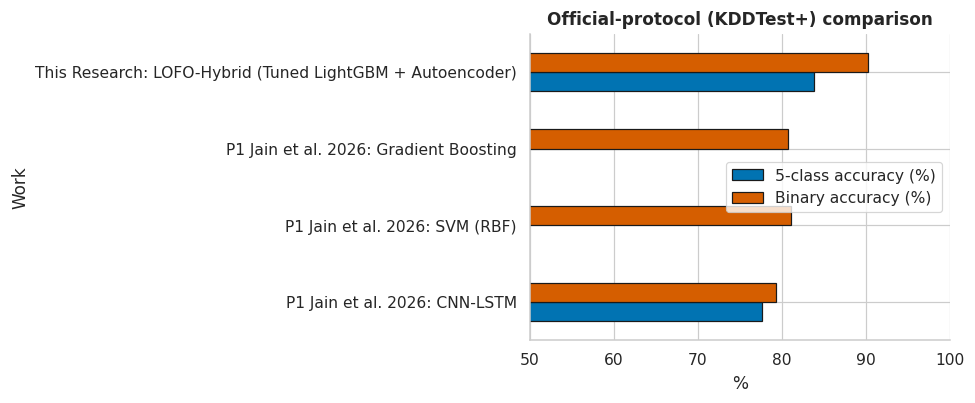

In [87]:
fin = scores(yte, REG[FINAL]['P']['te'], REG[FINAL]['pred']['te'], 'te')
bestA = PA[PA.index.str.startswith('Ours')]['Accuracy (%)'].max()
RW = pd.DataFrame([
 ['P1 Jain et al. 2026: CNN-LSTM', 'NSL-KDD', 'B (official KDDTest+)', 77.61, 0.6068, 79.36, 'Yes'],
 ['P1 Jain et al. 2026: SVM (RBF)', 'NSL-KDD', 'B (official KDDTest+)', np.nan, np.nan, 81.05, 'Yes'],
 ['P1 Jain et al. 2026: Gradient Boosting', 'NSL-KDD', 'B (official KDDTest+)', np.nan, np.nan, 80.73, 'Yes'],
 ['P1 Jain et al. 2026: CNN-LSTM', 'NSL-KDD', 'A (70/15/15 of KDDTrain+)', np.nan, np.nan, 99.28, 'Protocol A only'],
 ['P2 Suresh Kumar et al. 2026: DNN', 'NSL-KDD', 'A (80:20 of KDDTrain+)', 99.96, np.nan, np.nan, 'Protocol A only'],
 ['P3 Ghosh et al. 2026: MLA-DRMCNN', 'NSL-KDD (augmented)', 'A (random split)', 99.99, np.nan, np.nan, 'Protocol A only'],
 ['P4 Al Khulayf et al. 2026: KNN+RF ensemble', 'CICIDS2017', 'random split', np.nan, np.nan, np.nan, 'No (other dataset)'],
 ['P5 Antony et al. 2026: optimised SVM', 'NSL-KDD', 'A (80:20 of KDDTrain+)', 99.10, np.nan, np.nan, 'Protocol A only'],
 ['P6 Dardouri 2026: optimised LSTM', 'CICIDS2017', 'random split', np.nan, np.nan, np.nan, 'No (other dataset)'],
 ['P7 Jyoti et al. 2026: CatBoost/LightGBM', 'NSL-KDD', 'A (80:20 split)', np.nan, np.nan, np.nan, 'Class-wise only'],
 ['P8 Hora et al. 2026: transfer learning', 'EmuIoT-VT', 'cross-domain', np.nan, np.nan, np.nan, 'No (other dataset)'],
 ['P9 FI-AE 2026: autoencoder + RF', 'NSL-KDD, UNSW, CIC', 'random split', np.nan, np.nan, np.nan, 'Protocol A only'],
 ['P10 Blali et al. 2026: HFXL', 'CIC-IoT2023', 'random split', np.nan, np.nan, 99.42, 'No (other dataset)'],
 ['P11 Diao et al. 2026: SSGMHAN', 'NF-BoT-IoT', 'self-supervised', np.nan, np.nan, np.nan, 'No (other dataset)'],
 ['P12 Gökstorp et al. 2026: review', '—', 'survey', np.nan, np.nan, np.nan, 'Survey'],
 ['P13 Phalaagae et al. 2025: CNN-LSTM-Attention', 'WSN dataset', 'random split', np.nan, np.nan, 98.04, 'No (other dataset)'],
 ['P14 Hölbl & Rotovnik 2026: review', '—', 'survey', np.nan, np.nan, np.nan, 'Survey'],
 ['P15 Rehman et al. 2025: review', '—', 'survey', np.nan, np.nan, np.nan, 'Survey'],
 ['This Research: best single model, Protocol A', 'NSL-KDD', 'A (80:20 of KDDTrain+)', bestA, np.nan, np.nan, 'Yes'],
 [f'This Research: {FINAL}', 'NSL-KDD', 'B (official KDDTest+)', 100 * fin['Acc'], fin['MacroF1'], 100 * fin['BinAcc'], 'Yes']],
 columns=['Work', 'Dataset', 'Protocol', '5-class accuracy (%)', 'Macro-F1', 'Binary accuracy (%)', 'Directly comparable'])
display(save_table(RW.set_index('Work'), 'T43_related_work_comparison'))
B_ = RW[RW['Protocol'].str.startswith('B')].set_index('Work')[['5-class accuracy (%)', 'Binary accuracy (%)']]
B_.plot.barh(figsize=(9, 3.8), color=[PAL[0], PAL[3]], edgecolor='k'); plt.xlim(50, 100)
plt.title('Official-protocol (KDDTest+) comparison'); plt.xlabel('%')
savefig('related_work_protocolB')

### 80. Radar profile of the strongest systems on KDDTest+

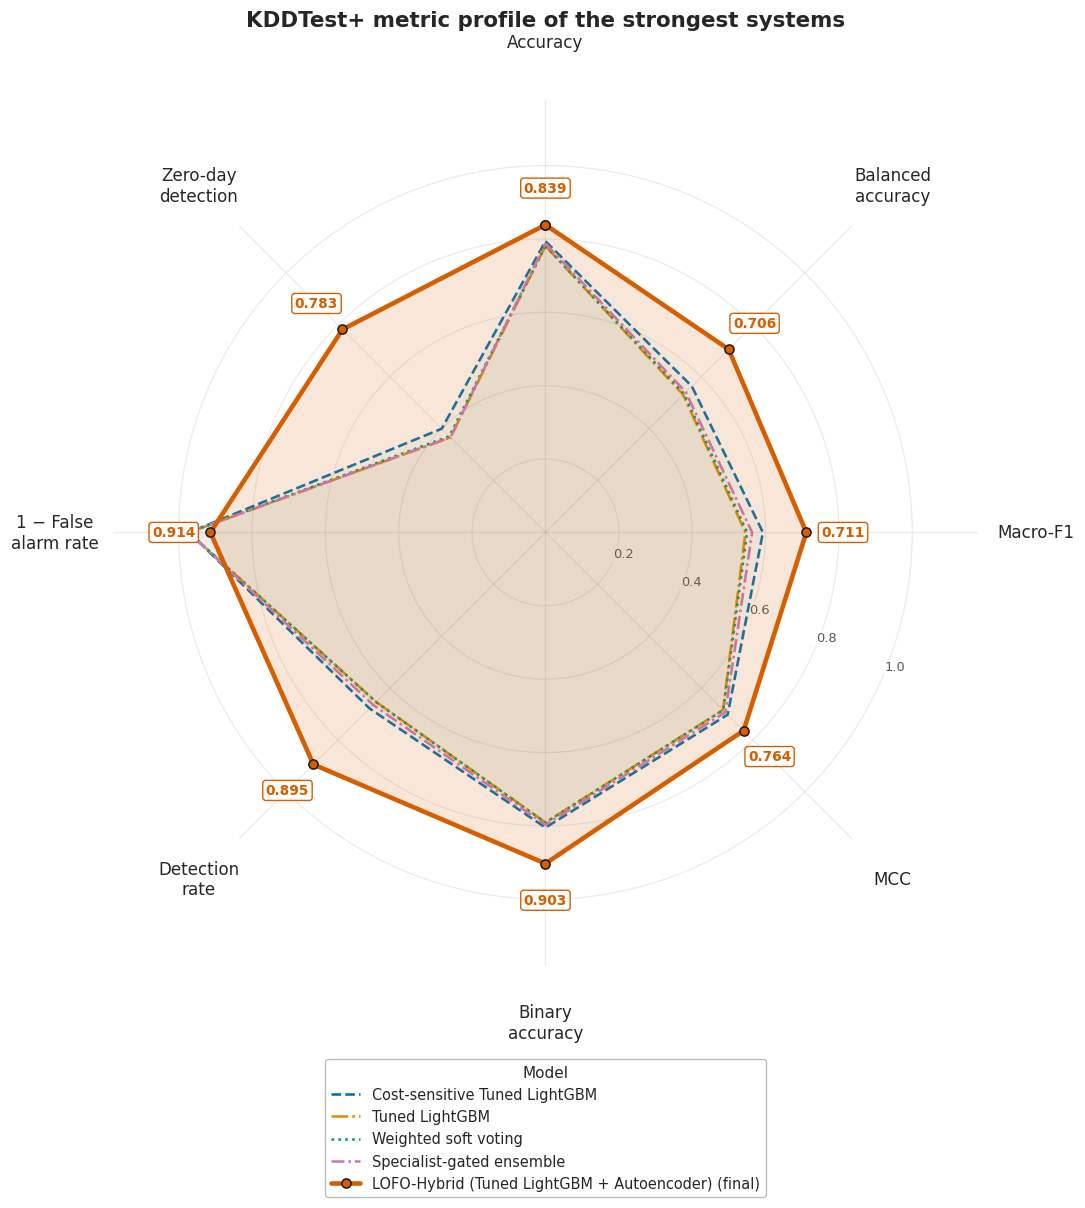

In [88]:
cands = [FINAL] + [n for n in VB.index if n != FINAL][:4]
mets = ['Acc', 'BalAcc', 'MacroF1', 'MCC', 'BinAcc', 'DR', '1-FAR', 'ZeroDayDR']
pretty = ['Accuracy', 'Balanced\naccuracy', 'Macro-F1', 'MCC', 'Binary\naccuracy',
          'Detection\nrate', '1 − False\nalarm rate', 'Zero-day\ndetection']
vals = {}
for n in cands:
    s = scores(yte, REG[n]['P']['te'], REG[n]['pred']['te'], 'te')
    s['1-FAR'] = 1 - s['FAR']
    vals[n] = [s[m] for m in mets]

ang = np.linspace(0, 2 * np.pi, len(mets), endpoint=False).tolist()
ang_c = ang + ang[:1]
FINAL_COL = PAL[3]
CMP_COLS = [PAL[0], PAL[1], PAL[2], PAL[4]]
styles = ['--', '-.', ':', (0, (5, 1.5, 1, 1.5))]
R_MAX = 1.18

fig, ax = plt.subplots(figsize=(10, 10.8), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

others = [n for n in cands if n != FINAL]
for k, n in enumerate(others):
    v = vals[n] + vals[n][:1]
    ax.plot(ang_c, v, lw=1.7, color=CMP_COLS[k % len(CMP_COLS)], ls=styles[k % len(styles)], label=n, zorder=3)
    ax.fill(ang_c, v, alpha=0.03, color=CMP_COLS[k % len(CMP_COLS)])

v = vals[FINAL] + vals[FINAL][:1]
ax.plot(ang_c, v, lw=3, color=FINAL_COL, label=f'{FINAL} (final)', zorder=5,
        marker='o', markersize=6, markeredgecolor='k')
ax.fill(ang_c, v, alpha=0.15, color=FINAL_COL, zorder=4)

for a, val in zip(ang, vals[FINAL]):
    r_lab = min(val + 0.10, 1.08)
    ax.text(a, r_lab, f'{val:.3f}', ha='center', va='center', fontsize=9, fontweight='bold', color=FINAL_COL,
            bbox=dict(boxstyle='round,pad=0.22', fc='white', ec=FINAL_COL, lw=0.9), zorder=7)

ax.set_xticks(ang)
ax.set_xticklabels(pretty, fontsize=11)
ax.tick_params(axis='x', pad=26)
ax.set_ylim(0, R_MAX)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=8.5, color='0.35')
ax.set_rlabel_position(360 / len(mets) * 2.5)
for lbl in ax.get_yticklabels():
    lbl.set_bbox(dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=0.85))
    lbl.set_zorder(8)
ax.grid(alpha=0.4)
ax.spines['polar'].set_visible(False)

ax.set_title('KDDTest+ metric profile of the strongest systems', fontsize=14, fontweight='bold', pad=48)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=1, fontsize=9.5,
          frameon=True, framealpha=0.95, edgecolor='0.7', title='Model', title_fontsize=10)
savefig('radar_profile')

## Part J — Statistical validity

### 81. Multi-seed repeatability of the supervised core and the hybrid system

Accuracy         Macro-F1         Binary acc        
                              mean     std     mean     std       mean     std
Split      Model                                                              
KDDTest+   LOFO-Hybrid      0.8343  0.0042   0.7215  0.0074     0.8852  0.0099
           Tuned LightGBM   0.7809  0.0008   0.5712  0.0070     0.7904  0.0010
KDDTest-21 LOFO-Hybrid      0.6866  0.0080   0.6329  0.0077     0.7833  0.0190
           Tuned LightGBM   0.5832  0.0016   0.4833  0.0070     0.6012  0.0019
Validation LOFO-Hybrid      0.9890  0.0003   0.8797  0.0090     0.9891  0.0002
           Tuned LightGBM   0.9994  0.0000   0.9618  0.0097     0.9994  0.0000

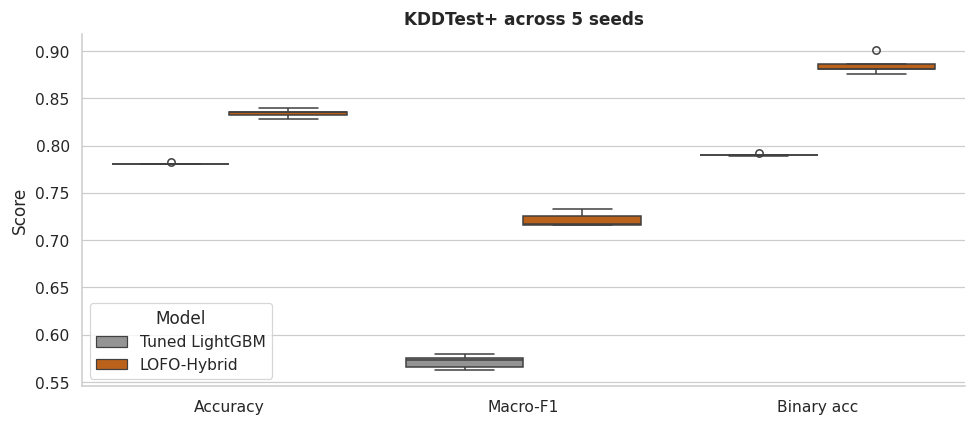

In [89]:
SEEDS = [0, 1, 2, 3, 4] if not FAST else [0, 1]
rows = []
for s in SEEDS:
    clf = factory(LOFO_MODEL, seed=s).fit(Xtr, ytr)
    sf = fit_scorer(BEST_KIND, Xtr[ytr == 0], seed=s)
    for k in ('va', 'te', 't21'):
        P_ = proba_of(clf, XS[k])
        _, ph = hybrid_from_X(XS[k], clf, sf)
        for n, pr in [(LOFO_MODEL, P_.argmax(1)), ('LOFO-Hybrid', ph)]:
            rows.append({'Seed': s, 'Model': n, 'Split': SPL[k], 'Accuracy': accuracy_score(YS[k], pr),
                         'Macro-F1': f1_score(YS[k], pr, average='macro'), 'Binary acc': accuracy_score(YS[k] > 0, pr > 0)})
MS = pd.DataFrame(rows)
MSS = MS.groupby(['Split', 'Model'])[['Accuracy', 'Macro-F1', 'Binary acc']].agg(['mean', 'std'])
display(save_table(MSS.round(4), 'T44_multi_seed'))
plt.figure(figsize=(9, 4))
sns.boxplot(data=MS[MS.Split == 'KDDTest+'].melt(id_vars=['Seed', 'Model', 'Split']), x='variable', y='value', hue='Model', palette=[PAL[7], PAL[3]])
plt.title(f'KDDTest+ across {len(SEEDS)} seeds'); plt.xlabel(''); plt.ylabel('Score')
savefig('multi_seed')

### 82. Bootstrap 95% confidence intervals on the official test sets

Split  Estimate  \
Model                                      Metric                           
LOFO-Hybrid (Tuned LightGBM + Autoencoder) Accuracy    KDDTest+    0.8386   
                                           Macro-F1    KDDTest+    0.7112   
                                           Binary acc  KDDTest+    0.9028   
Tuned LightGBM                             Accuracy    KDDTest+    0.7811   
                                           Macro-F1    KDDTest+    0.5452   
                                           Binary acc  KDDTest+    0.7908   
Cost-sensitive Tuned LightGBM              Accuracy    KDDTest+    0.7939   
                                           Macro-F1    KDDTest+    0.5928   
                                           Binary acc  KDDTest+    0.8046   
Weighted soft voting                       Accuracy    KDDTest+    0.7814   
                                           Macro-F1    KDDTest+    0.5496   
                                           Binary acc  KDDTest+    0.7910   
Specialist-gated ensemble                  Accuracy    KDDTest+    0.7876   
                                           Macro-F1    KDDTest+    0.5634   
                                           Binary acc  KDDTest+    0.7972   

                                                       CI low  CI high  
Model                                      Metric                       
LOFO-Hybrid (Tuned LightGBM + Autoencoder) Accuracy    0.8342   0.8434  
                                           Macro-F1    0.6872   0.7339  
                                           Binary acc  0.8994   0.9069  
Tuned LightGBM                             Accuracy    0.7762   0.7863  
                                           Macro-F1    0.5248   0.5665  
                                           Binary acc  0.7860   0.7961  
Cost-sensitive Tuned LightGBM              Accuracy    0.7892   0.7989  
                                           Macro-F1    0.5690   0.6180  
                                           Binary acc  0.7999   0.8097  
Weighted soft voting                       Accuracy    0.7764   0.7867  
                                           Macro-F1    0.5272   0.5716  
                                           Binary acc  0.7861   0.7962  
Specialist-gated ensemble                  Accuracy    0.7825   0.7927  
                                           Macro-F1    0.5424   0.5854  
                                           Binary acc  0.7924   0.8023

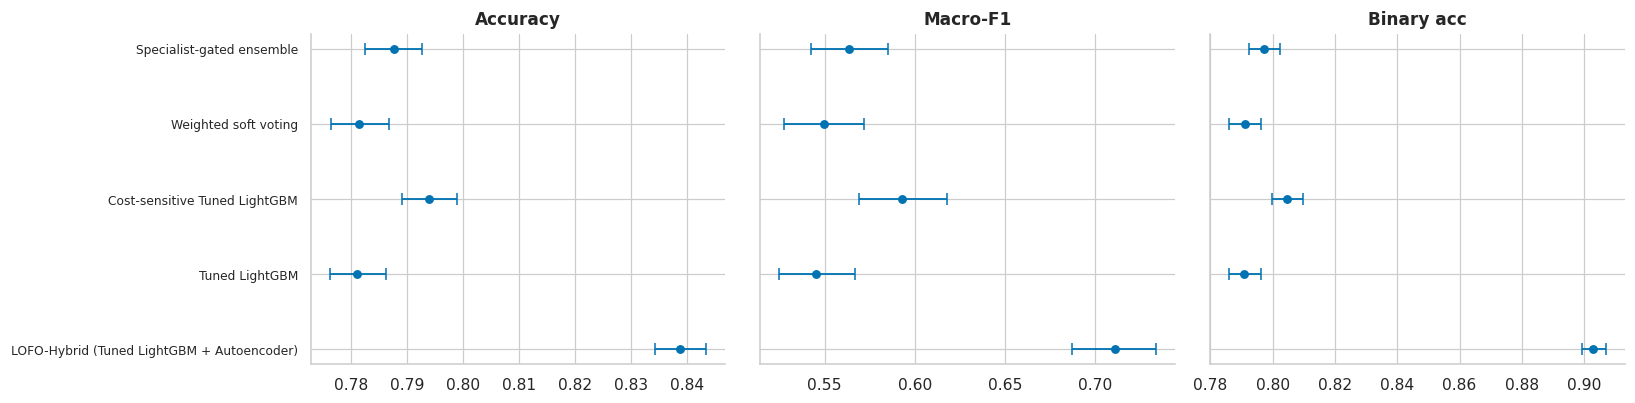

In [90]:
NB = 1000 if not FAST else 100
rng = np.random.RandomState(SEED)
cmp_names = list(dict.fromkeys([FINAL, LOFO_MODEL] + list(VB.index[:4])))
rows = []
for k in ('te', 't21'):
    idx = [rng.randint(0, len(YS[k]), len(YS[k])) for _ in range(NB)]
    for n in cmp_names:
        pr = REG[n]['pred'][k]
        for met, fn in [('Accuracy', lambda y, p: accuracy_score(y, p)), ('Macro-F1', lambda y, p: f1_score(y, p, average='macro')),
                        ('Binary acc', lambda y, p: accuracy_score(y > 0, p > 0))]:
            bs = np.array([fn(YS[k][i], pr[i]) for i in idx])
            rows.append({'Split': SPL[k], 'Model': n, 'Metric': met, 'Estimate': fn(YS[k], pr), 'CI low': np.percentile(bs, 2.5), 'CI high': np.percentile(bs, 97.5)})
CI = save_table(pd.DataFrame(rows), 'T45_bootstrap_ci')
display(CI[CI.Split == 'KDDTest+'].set_index(['Model', 'Metric']).round(4))
sub = CI[(CI.Split == 'KDDTest+')]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a_, met in zip(ax, ['Accuracy', 'Macro-F1', 'Binary acc']):
    d = sub[sub.Metric == met].reset_index(drop=True)
    a_.errorbar(d['Estimate'], range(len(d)), xerr=[d['Estimate'] - d['CI low'], d['CI high'] - d['Estimate']], fmt='o', capsize=4, color=PAL[0])
    a_.set_yticks(range(len(d))); a_.set_yticklabels(d['Model'], fontsize=8); a_.set_title(met)
savefig('bootstrap_ci')

### 83. Exact McNemar tests with Holm correction

In [91]:
rows = []
others = [n for n in VB.index if n != FINAL][:8]
for k in ('te', 't21'):
    for n in others:
        a, b = REG[FINAL]['pred'][k] == YS[k], REG[n]['pred'][k] == YS[k]
        n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
        p = stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
        rows.append({'Split': SPL[k], 'Comparator': n, 'Final right / comparator wrong': n10, 'Final wrong / comparator right': n01, 'p': p})
MC = pd.DataFrame(rows)
for sp, g in MC.groupby('Split'):
    o = g['p'].sort_values().index
    m = len(o)
    MC.loc[o, 'Holm p'] = np.minimum(1, np.maximum.accumulate(g.loc[o, 'p'].values * (m - np.arange(m))))
MC['Significant (α=0.05)'] = MC['Holm p'] < 0.05
display(save_table(MC.set_index(['Split', 'Comparator']).round(6), 'T46_mcnemar'))

Final right / comparator wrong  \
Split      Comparator                                                       
KDDTest+   Cost-sensitive Tuned LightGBM                             1571   
           Tuned LightGBM                                            1869   
           Weighted soft voting                                      1865   
           Specialist-gated ensemble                                 1724   
           HGB class-weighted                                        1666   
           Tuned LightGBM + class scaling                            1735   
           XGBoost                                                   1854   
           Decision Tree                                             1893   
KDDTest-21 Cost-sensitive Tuned LightGBM                             1571   
           Tuned LightGBM                                            1869   
           Weighted soft voting                                      1865   
           Specialist-gated ensemble                                 1724   
           HGB class-weighted                                        1658   
           Tuned LightGBM + class scaling                            1735   
           XGBoost                                                   1854   
           Decision Tree                                             1856   

                                           Final wrong / comparator right  \
Split      Comparator                                                       
KDDTest+   Cost-sensitive Tuned LightGBM                              563   
           Tuned LightGBM                                             573   
           Weighted soft voting                                       576   
           Specialist-gated ensemble                                  573   
           HGB class-weighted                                         563   
           Tuned LightGBM + class scaling                             581   
           XGBoost                                                    565   
           Decision Tree                                              587   
KDDTest-21 Cost-sensitive Tuned LightGBM                              540   
           Tuned LightGBM                                             550   
           Weighted soft voting                                       553   
           Specialist-gated ensemble                                  550   
           HGB class-weighted                                         540   
           Tuned LightGBM + class scaling                             558   
           XGBoost                                                    542   
           Decision Tree                                              575   

                                             p  Holm p  Significant (α=0.05)  
Split      Comparator                                                         
KDDTest+   Cost-sensitive Tuned LightGBM   0.0     0.0                  True  
           Tuned LightGBM                  0.0     0.0                  True  
           Weighted soft voting            0.0     0.0                  True  
           Specialist-gated ensemble       0.0     0.0                  True  
           HGB class-weighted              0.0     0.0                  True  
           Tuned LightGBM + class scaling  0.0     0.0                  True  
           XGBoost                         0.0     0.0                  True  
           Decision Tree                   0.0     0.0                  True  
KDDTest-21 Cost-sensitive Tuned LightGBM   0.0     0.0                  True  
           Tuned LightGBM                  0.0     0.0                  True  
           Weighted soft voting            0.0     0.0                  True  
           Specialist-gated ensemble       0.0     0.0                  True  
           HGB class-weighted              0.0     0.0                  True  
           Tuned LightGBM + class scaling  0.0     0.0                  True  
     

### 84. Friedman test and Nemenyi critical-difference diagram over test blocks

Friedman χ² = 108.04, p = 2.34e-20; Nemenyi CD = 2.348


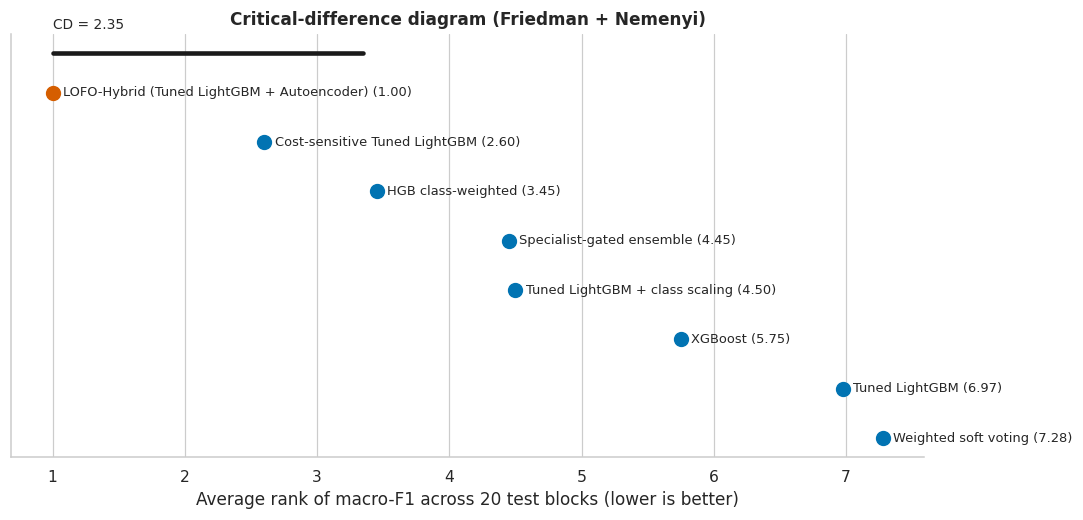

,Average rank
LOFO-Hybrid (Tuned LightGBM + Autoencoder),1.000
Cost-sensitive Tuned LightGBM,2.600
HGB class-weighted,3.450
Specialist-gated ensemble,4.450
Tuned LightGBM + class scaling,4.500
XGBoost,5.750
Tuned LightGBM,6.975
Weighted soft voting,7.275


In [92]:
blk_names = list(dict.fromkeys([FINAL] + list(VB.index[:7])))
NBLK = 20
blocks = np.array_split(np.random.RandomState(SEED).permutation(len(yte)), NBLK)
Mf = np.array([[f1_score(yte[b], REG[n]['pred']['te'][b], average='macro') for n in blk_names] for b in blocks])
fr = stats.friedmanchisquare(*Mf.T)
ranks = stats.rankdata(-Mf, axis=1).mean(0)
qa = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}[len(blk_names)]
CD = qa * np.sqrt(len(blk_names) * (len(blk_names) + 1) / (6 * NBLK))
print(f'Friedman χ² = {fr.statistic:.2f}, p = {fr.pvalue:.2e}; Nemenyi CD = {CD:.3f}')
order = np.argsort(ranks)
fig, ax = plt.subplots(figsize=(10, 0.42 * len(blk_names) + 1.5))
for i, j in enumerate(order):
    ax.plot(ranks[j], i, 'o', ms=9, color=PAL[3] if blk_names[j] == FINAL else PAL[0])
    ax.text(ranks[j] + .08, i, f'{blk_names[j]} ({ranks[j]:.2f})', va='center', fontsize=8.5)
ax.plot([ranks[order[0]], ranks[order[0]] + CD], [-0.8, -0.8], 'k-', lw=3)
ax.text(ranks[order[0]], -1.3, f'CD = {CD:.2f}', fontsize=9)
ax.set_yticks([]); ax.set_xlabel('Average rank of macro-F1 across 20 test blocks (lower is better)'); ax.invert_yaxis()
ax.set_title('Critical-difference diagram (Friedman + Nemenyi)')
savefig('critical_difference')
save_table(pd.DataFrame({'Average rank': ranks}, index=blk_names).sort_values('Average rank'), 'T47_friedman_ranks')

### 85. Paired bootstrap test on the macro-F1 improvement

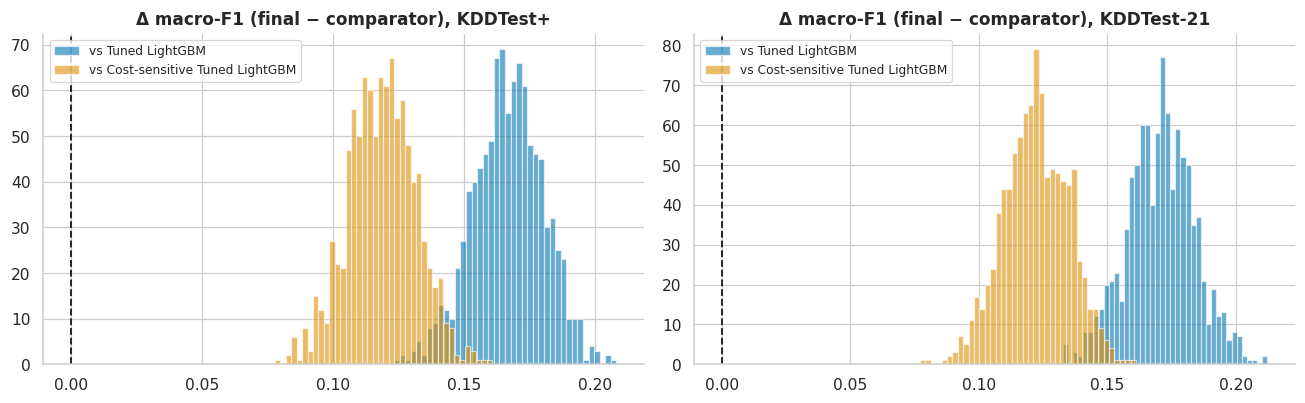

,Split,Versus,Mean Δ macro-F1,CI low,CI high,One-sided p (Δ ≤ 0)
0,KDDTest+,Tuned LightGBM,0.1666,0.1386,0.1921,0.0
1,KDDTest+,Cost-sensitive Tuned LightGBM,0.1186,0.0929,0.1431,0.0
2,KDDTest-21,Tuned LightGBM,0.1706,0.1442,0.1966,0.0
3,KDDTest-21,Cost-sensitive Tuned LightGBM,0.1221,0.0973,0.1458,0.0


In [93]:
rng = np.random.RandomState(SEED)
rows = []
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a_, k in zip(ax, ['te', 't21']):
    for n, c in [(LOFO_MODEL, PAL[0]), (VB.index[1] if VB.index[0] == FINAL else VB.index[0], PAL[1])]:
        if n == FINAL:
            continue
        d = np.array([(lambda i: f1_score(YS[k][i], REG[FINAL]['pred'][k][i], average='macro') -
                                 f1_score(YS[k][i], REG[n]['pred'][k][i], average='macro'))(rng.randint(0, len(YS[k]), len(YS[k]))) for _ in range(NB)])
        rows.append({'Split': SPL[k], 'Versus': n, 'Mean Δ macro-F1': d.mean(), 'CI low': np.percentile(d, 2.5), 'CI high': np.percentile(d, 97.5),
                     'One-sided p (Δ ≤ 0)': (d <= 0).mean()})
        a_.hist(d, bins=40, alpha=.6, color=c, label=f'vs {n}')
    a_.axvline(0, c='k', ls='--'); a_.set_title(f'Δ macro-F1 (final − comparator), {SPL[k]}'); a_.legend(fontsize=8)
savefig('paired_bootstrap')
display(save_table(pd.DataFrame(rows).round(4), 'T48_paired_bootstrap'))

## Part K — Explainability

### 86. Global SHAP attribution per attack family

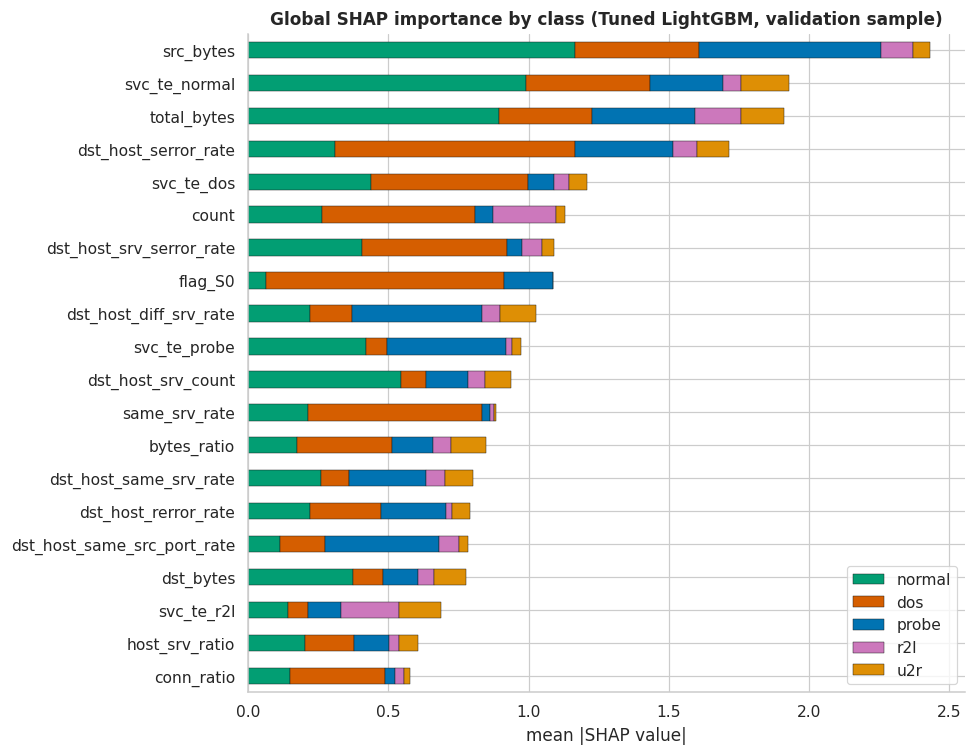

In [94]:
XAI_MODEL = REG[LOFO_MODEL]['model']
XSAMP = Xva[np.random.RandomState(SEED).choice(len(Xva), min(len(Xva), 800 if not FAST else 200), replace=False)]
SHAP_ARR = None
if shap is not None:
    try:
        sv = shap.TreeExplainer(XAI_MODEL).shap_values(XSAMP)
        SHAP_ARR = np.stack(sv, 0) if isinstance(sv, list) else np.moveaxis(np.asarray(sv), -1, 0)
    except Exception as e:
        print('TreeExplainer unavailable for', LOFO_MODEL, '→ using a model-agnostic explainer:', str(e)[:80])
        try:
            bg = shap.sample(Xtr, 100, random_state=SEED)
            ex = shap.Explainer(lambda X: proba_of(XAI_MODEL, X), shap.maskers.Independent(bg))
            SHAP_ARR = np.moveaxis(ex(XSAMP[:200], max_evals=2 * Xtr.shape[1] + 1).values, -1, 0)
            XSAMP = XSAMP[:200]
        except Exception as e2:
            print('SHAP failed:', str(e2)[:120])
if SHAP_ARR is not None:
    SH = pd.DataFrame(np.abs(SHAP_ARR).mean(1).T, index=FN, columns=CLASSES)
    SH = SH.loc[SH.sum(1).sort_values(ascending=False).index]
    save_table(SH.round(5), 'T49_shap_global')
    SH.head(20).iloc[::-1].plot.barh(stacked=True, figsize=(9, 7), color=[CCOL[c] for c in CLASSES], edgecolor='k', linewidth=.3)
    plt.xlabel('mean |SHAP value|'); plt.title(f'Global SHAP importance by class ({LOFO_MODEL}, validation sample)')
    savefig('shap_global')
else:
    print('SHAP not available in this runtime.')

### 87. SHAP beeswarm plots for the minority families (R2L and U2R)

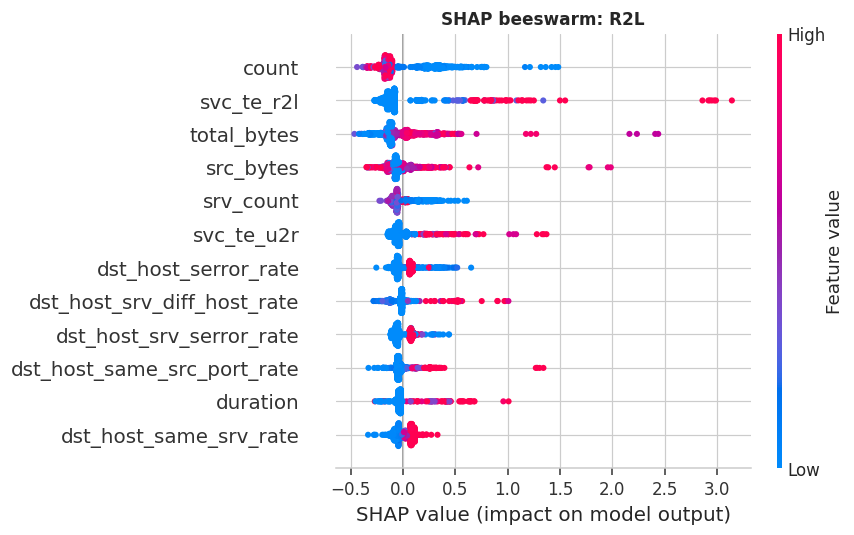

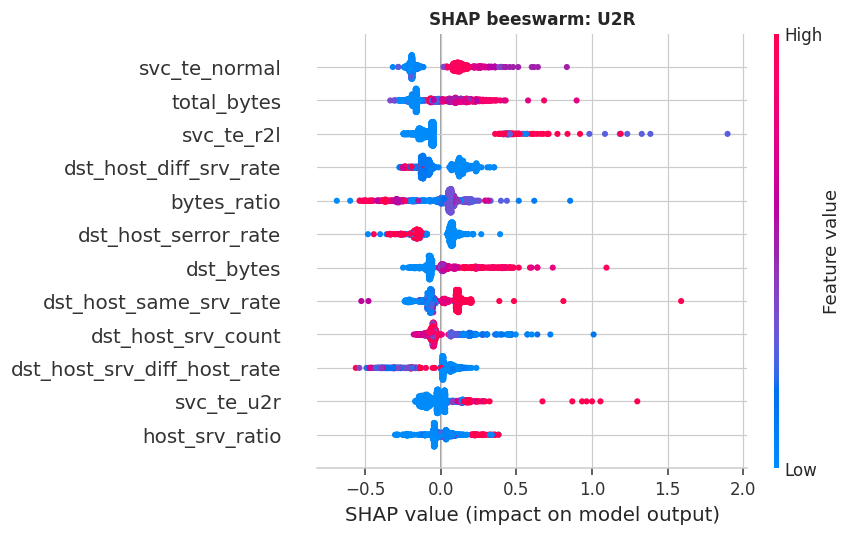

In [95]:
if SHAP_ARR is not None:
    for c in (3, 4):
        plt.figure()
        shap.summary_plot(SHAP_ARR[c], XSAMP, feature_names=FN, max_display=12, show=False, plot_size=(8, 5))
        plt.title(f'SHAP beeswarm: {CLASSES[c].upper()}')
        savefig(f'shap_beeswarm_{CLASSES[c]}')

### 88. Permutation importance with confidence intervals on validation

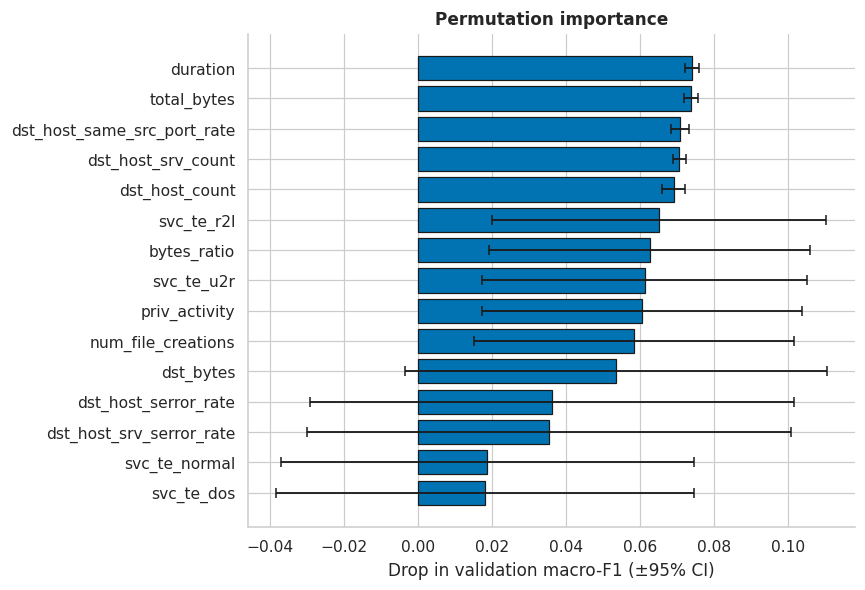

In [96]:
I = np.random.RandomState(SEED).choice(len(Xva), min(len(Xva), 6000), replace=False)
pi = permutation_importance(XAI_MODEL, Xva[I], yva[I], scoring='f1_macro', n_repeats=8 if not FAST else 2, random_state=SEED, n_jobs=N_JOBS)
PI = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std}, index=FN).sort_values('mean', ascending=False)
save_table(PI.round(5), 'T50_permutation_importance')
top = PI.head(15).iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top.index, top['mean'], xerr=1.96 * top['std'], color=PAL[0], edgecolor='k', capsize=3)
plt.xlabel('Drop in validation macro-F1 (±95% CI)'); plt.title('Permutation importance')
savefig('permutation_importance')

### 89. Explanation stability across bootstrap refits (Kendall τ)

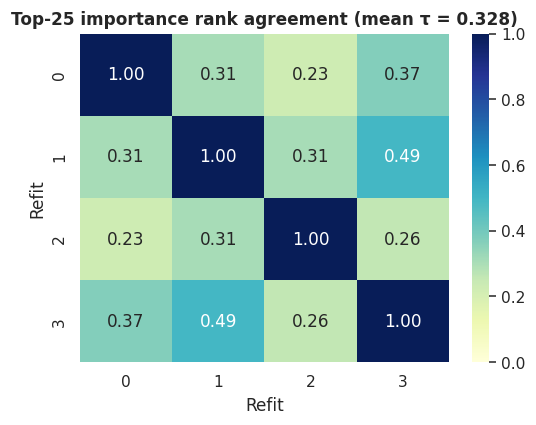

In [101]:
B = 4 if not FAST else 2
rk = []
I = np.random.RandomState(SEED).choice(len(Xva), min(len(Xva), 3000), replace=False)
for b in range(B):
    i = np.random.RandomState(100 + b).choice(len(Xtr), len(Xtr), replace=True)
    m = factory(LOFO_MODEL, seed=b).fit(Xtr[i], ytr[i])
    rk.append(permutation_importance(m, Xva[I], yva[I], scoring='f1_macro', n_repeats=2, random_state=b, n_jobs=N_JOBS).importances_mean)
top = np.argsort(-np.mean(rk, 0))[:25]
K = np.array([[stats.kendalltau(rk[a][top], rk[b][top])[0] for b in range(B)] for a in range(B)])
plt.figure(figsize=(5, 4))
sns.heatmap(K, annot=True, fmt='.2f', vmin=0, vmax=1, cmap='YlGnBu')
plt.title(f'Top-25 importance rank agreement (mean τ = {K[np.triu_indices(B, 1)].mean():.3f})'); plt.xlabel('Refit'); plt.ylabel('Refit')
savefig('explanation_stability')

### 90. Global surrogate decision rules with measured fidelity

,Leaves,Fidelity (validation),Accuracy (validation)
Depth,,,
3,8,0.9643,0.9639
4,14,0.9804,0.9800
5,24,0.9861,0.9856
6,36,0.9903,0.9899
8,73,0.9950,0.9945


|--- total_bytes <= -0.17
|   |--- dst_host_same_src_port_rate <= -0.40
|   |   |--- dst_host_diff_srv_rate <= 0.43
|   |   |   |--- dst_host_same_srv_rate <= 0.24
|   |   |   |   |--- class: 1
|   |   |   |--- dst_host_same_srv_rate >  0.24
|   |   |   |   |--- class: 0
|   |   |--- dst_host_diff_srv_rate >  0.43
|   |   |   |--- dst_host_rerror_rate <= -0.24
|   |   |   |   |--- class: 0
|   |   |   |--- dst_host_rerror_rate >  -0.24
|   |   |   |   |--- class: 2
|   |--- dst_host_same_src_port_rate >  -0.40
|   |   |--- svc_te_normal <= 0.42
|   |   |   |--- bytes_ratio <= 1.19
|   |   |   |   |--- class: 2
|   |   |   |--- bytes_ratio >  1.19
|   |   |   |   |--- class: 1
|   |   |--- svc_te_normal >  0.42
|   |   |   |--- dst_host_srv_serror_rate <= -0.41
|   |   |   |   |--- class: 0
|   |   |   |--- dst_host_srv_serror_rate >  -0.41
|   |   |   |   |--- class: 1
|--- total_bytes >  -0.17
|   |--- svc_ecr_i <= 3.08
|   |   |--- num_compromised <= 2.10
|   |   |   |--- hot <= 12.2

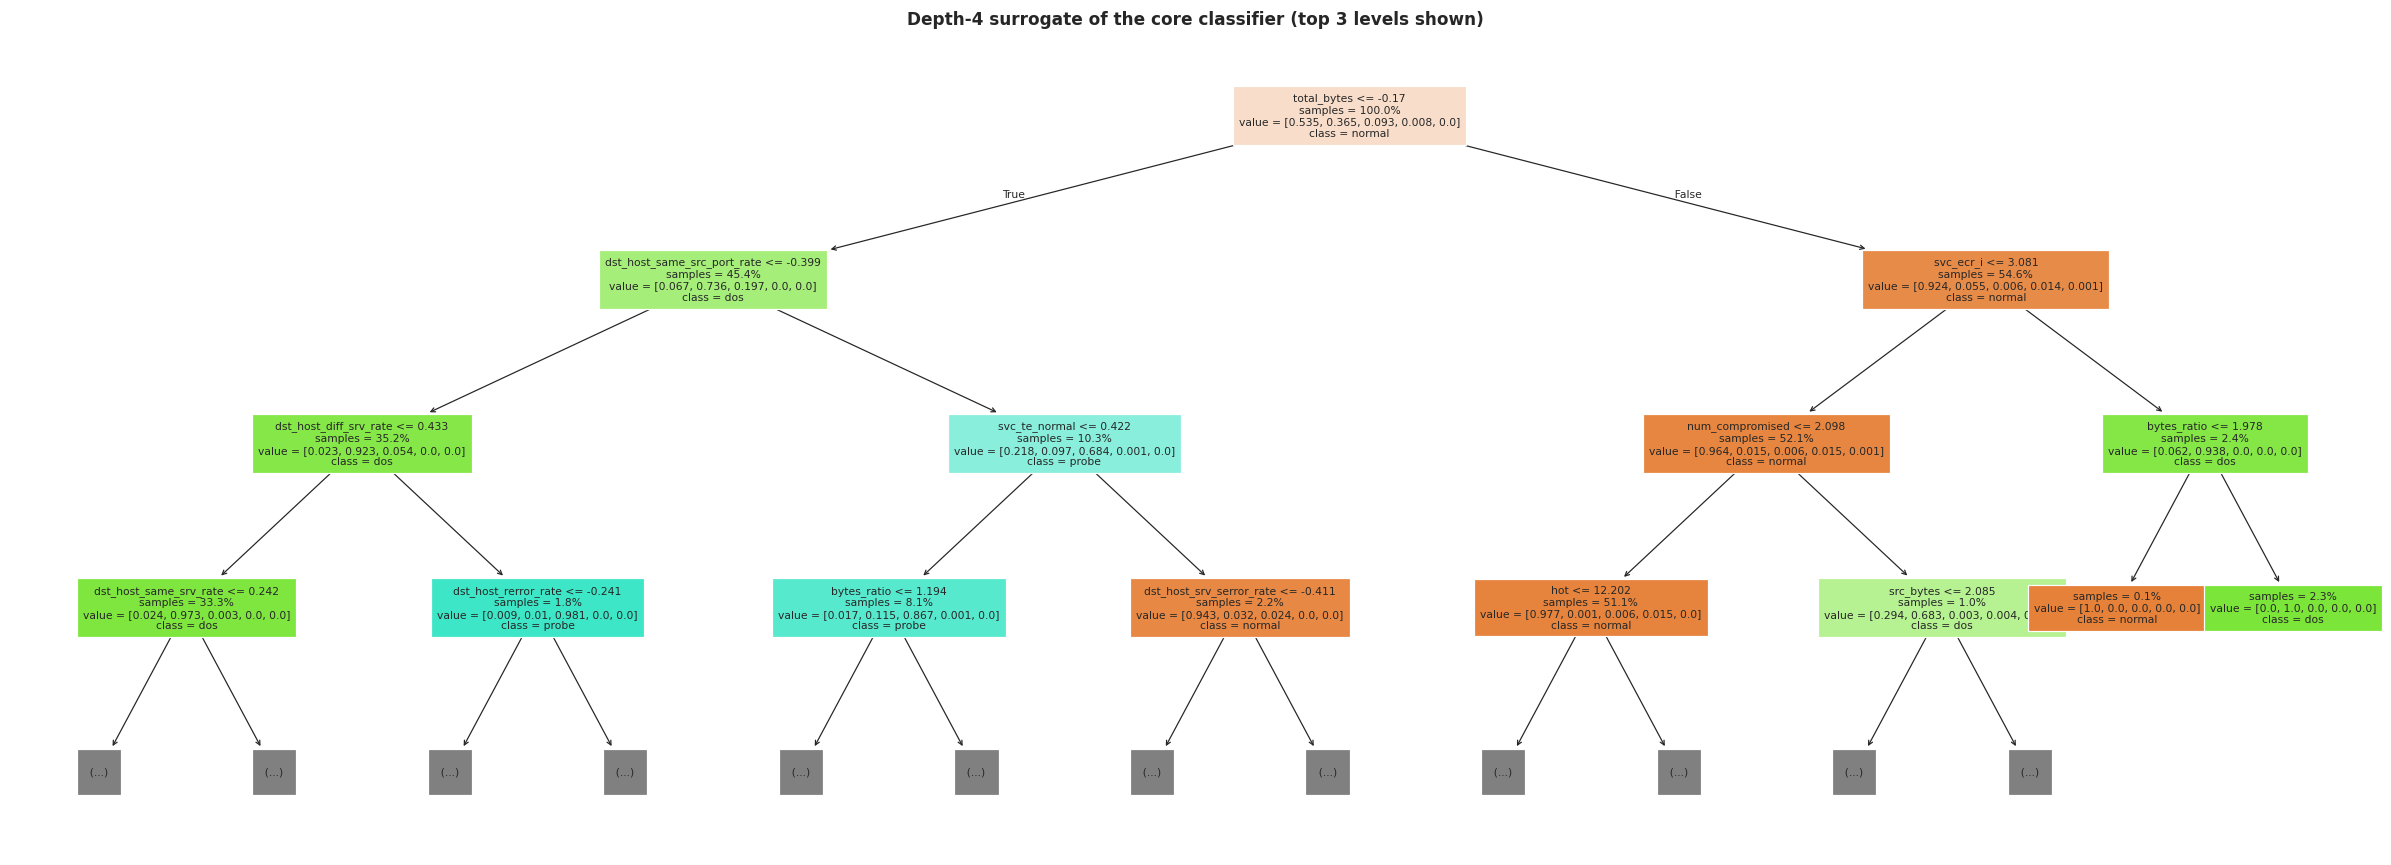

In [102]:
teacher_tr = proba_of(XAI_MODEL, Xtr).argmax(1)
rows = []
for depth in (3, 4, 5, 6, 8):
    sur = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(Xtr, teacher_tr)
    rows.append({'Depth': depth, 'Leaves': sur.get_n_leaves(),
                 'Fidelity (validation)': accuracy_score(REG[LOFO_MODEL]['P']['va'].argmax(1), sur.predict(Xva)),
                 'Accuracy (validation)': accuracy_score(yva, sur.predict(Xva))})
display(save_table(pd.DataFrame(rows).set_index('Depth').round(4), 'T51_surrogate_fidelity'))
SUR = DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(Xtr, teacher_tr)
print(export_text(SUR, feature_names=FN, max_depth=4)[:3000])
plt.figure(figsize=(22, 8))
plot_tree(SUR, feature_names=FN, class_names=CLASSES, filled=True, impurity=False, proportion=True, fontsize=7, max_depth=3)
plt.title('Depth-4 surrogate of the core classifier (top 3 levels shown)')
savefig('surrogate_tree')

### 91. Counterfactual explanations: minimal feature edits that turn a detected attack into 'normal'

,Cases,Flip rate,Median edits
Family,,,
dos,12,0.083,12.0
probe,12,0.417,8.0
r2l,12,1.000,4.0
u2r,8,1.000,5.0


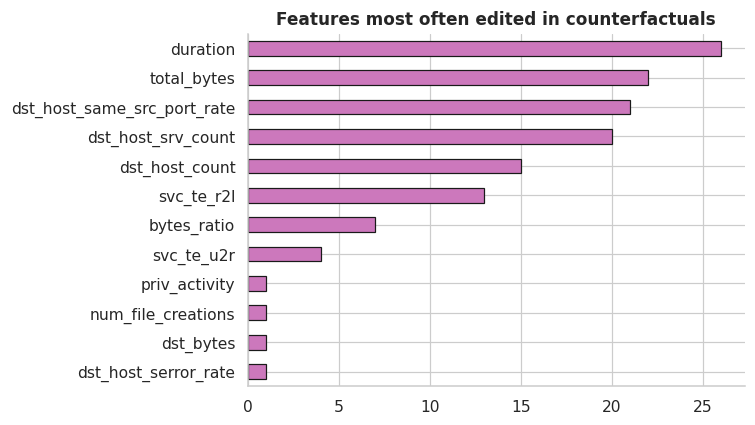

In [103]:
imp_order = [FN.index(f) for f in PI.index[:12]]
normal_med = np.median(Xtr[ytr == 0], 0)
rows = []
for c in range(1, 5):
    cand = np.where((yva == c) & (REG[LOFO_MODEL]['pred']['va'] == c))[0][:12]
    for i in cand:
        x = Xva[i].copy(); changed = []
        for j in imp_order:
            x[j] = normal_med[j]; changed.append(FN[j])
            if proba_of(XAI_MODEL, x[None]).argmax(1)[0] == 0:
                break
        flipped = proba_of(XAI_MODEL, x[None]).argmax(1)[0] == 0
        rows.append({'Family': CLASSES[c], 'Flipped to normal': flipped, 'Features edited': len(changed) if flipped else np.nan,
                     'Edited features': ', '.join(changed) if flipped else '—'})
CFX = pd.DataFrame(rows)
display(save_table(CFX.groupby('Family').agg(**{'Cases': ('Flipped to normal', 'size'), 'Flip rate': ('Flipped to normal', 'mean'),
                                                'Median edits': ('Features edited', 'median')}).round(3), 'T52_counterfactual_summary'))
fe = pd.Series([f for s in CFX['Edited features'] if s != '—' for f in s.split(', ')]).value_counts().head(12)
fe.iloc[::-1].plot.barh(figsize=(7, 4), color=PAL[4], edgecolor='k'); plt.title('Features most often edited in counterfactuals')
savefig('counterfactual_features')

## Part L — Robustness, drift monitoring and deployment

### 92. Problem-space constrained evasion attack on attacker-controllable features

,Tuned LightGBM evasion (%),LOFO-Hybrid evasion (%)
ε (fraction moved toward normal median),,
0.00,0.00,0.00
0.10,10.40,0.36
0.25,13.79,2.69
0.50,17.40,3.81
0.75,26.28,5.64
1.00,35.23,8.68


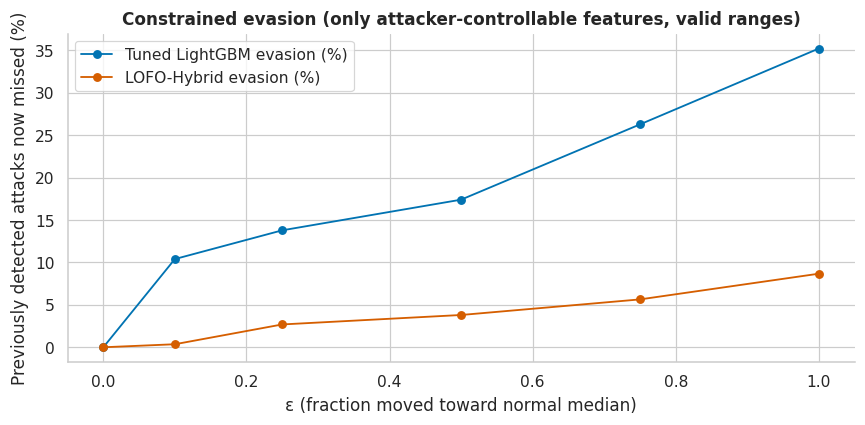

In [104]:
CTRL = ['duration', 'src_bytes', 'dst_bytes', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'count', 'srv_count']
MED_N = TR.loc[TR.cat == 'normal', CTRL].median()
LO, HI = TR[CTRL].min(), TR[CTRL].max()
def evade(df, eps):
    d = df.copy()
    for c in CTRL:
        d[c] = np.clip(np.round(d[c] + eps * (MED_N[c] - d[c])), LO[c], HI[c]).astype(df[c].dtype)
    return d
ATK = tst[(tst['y'] > 0).values].copy()
base_sup = REG[LOFO_MODEL]['pred']['te'][(tst['y'] > 0).values] > 0
base_hyb = REG[HYB]['pred']['te'][(tst['y'] > 0).values] > 0
EPS = [0, 0.1, 0.25, 0.5, 0.75, 1.0] if not FAST else [0, 0.5, 1.0]
rows = []
for e in EPS:
    Xe = FB.transform(evade(ATK, e))
    ps = proba_of(CLF, Xe).argmax(1) > 0
    _, ph = hybrid_from_X(Xe)
    rows.append({'ε (fraction moved toward normal median)': e, f'{LOFO_MODEL} evasion (%)': 100 * (base_sup & ~ps).sum() / max(base_sup.sum(), 1),
                 'LOFO-Hybrid evasion (%)': 100 * (base_hyb & ~(ph > 0)).sum() / max(base_hyb.sum(), 1)})
EV = save_table(pd.DataFrame(rows).set_index('ε (fraction moved toward normal median)'), 'T53_constrained_evasion')
display(EV.round(2))
EV.plot(marker='o', figsize=(8, 4), color=[PAL[0], PAL[3]]); plt.ylabel('Previously detected attacks now missed (%)')
plt.title('Constrained evasion (only attacker-controllable features, valid ranges)')
savefig('constrained_evasion')

### 93. Constrained adversarial training with a validation-selected augmentation weight

,Val macro-F1,Val accuracy,Val false alarm rate,Val robust DR (evaded validation attacks)
Augmented-row weight,,,,
0.00,0.9759,0.9994,0.0002,0.8707
0.02,0.9582,0.9994,0.0004,0.9929
0.05,0.9666,0.9994,0.0003,0.9935
0.10,0.9666,0.9994,0.0004,0.9941
0.30,0.9505,0.9994,0.0005,0.9943
1.00,0.9500,0.9993,0.0008,0.9945


Selection on validation only: keep macro-F1 within 1 pp and false alarms within 0.5 pp of the standard model, then maximise robustness on evaded validation attacks → weight = 0.1


,Standard model DR (%),Adversarially trained DR (%),LOFO-Hybrid DR (%)
ε,,,
0.00,65.32,69.24,89.46
0.10,59.31,70.97,89.41
0.25,56.52,72.77,87.24
0.50,54.41,82.81,86.22
0.75,48.16,78.64,84.54
1.00,42.32,65.38,82.12


,Train Acc,Train MacroF1,Validation Acc,Validation MacroF1,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest-21 Acc,KDDTest-21 MacroF1,Train time (s)
Tuned LightGBM,1.0,1.0,0.9994,0.9759,0.7811,0.5452,0.5836,0.4573,58.0517
Tuned LightGBM (adversarially trained),1.0,1.0,0.9994,0.9666,0.7815,0.6210,0.5843,0.5177,NaN


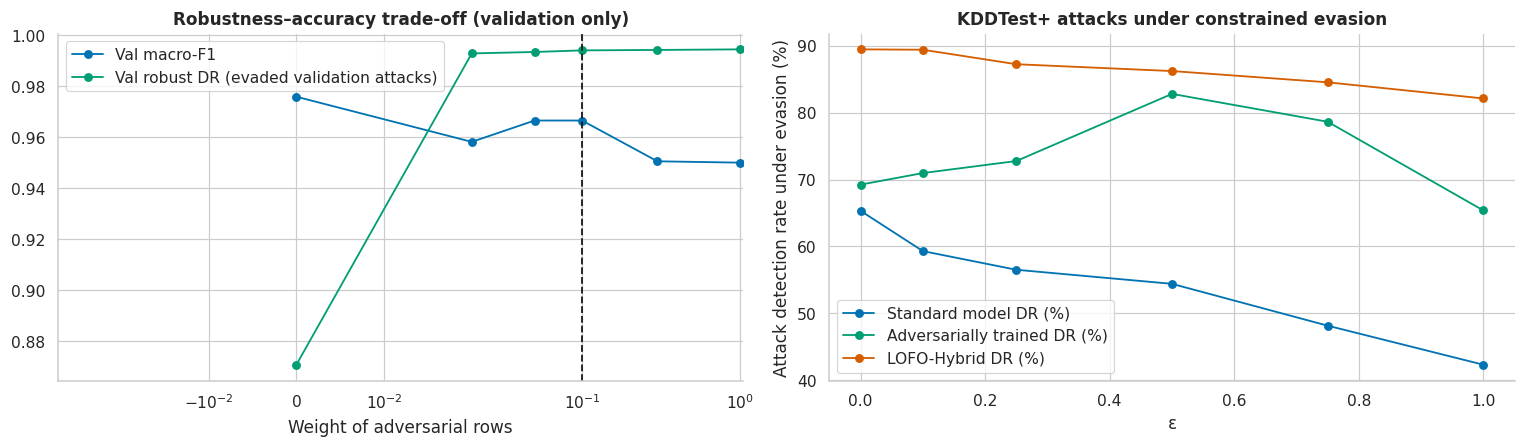

In [105]:
atk_tr = TR[TR['y'] > 0]
aug = pd.concat([evade(atk_tr, e) for e in (0.1, 0.25, 0.5)], ignore_index=True)
Xaug_only, yaug_only = FB.transform(aug), aug['y'].values
VA_ATK = VA[VA['y'] > 0]
VA_EVADED = [FB.transform(evade(VA_ATK, e)) for e in (0.25, 0.5, 1.0)]
def val_profile(m):
    pv = proba_of(m, Xva).argmax(1)
    return {'Val macro-F1': f1_score(yva, pv, average='macro'), 'Val accuracy': accuracy_score(yva, pv),
            'Val false alarm rate': (pv[yva == 0] > 0).mean(),
            'Val robust DR (evaded validation attacks)': np.mean([(proba_of(m, Xe).argmax(1) > 0).mean() for Xe in VA_EVADED])}
base = val_profile(CLF)
rows = [{'Augmented-row weight': 0.0, **base}]
CAND = {0.0: CLF}
for w in [0.02, 0.05, 0.1, 0.3, 1.0]:
    sw = np.r_[np.ones(len(ytr)), np.full(len(yaug_only), w)]
    m = factory(LOFO_MODEL).fit(np.vstack([Xtr, Xaug_only]), np.r_[ytr, yaug_only], sample_weight=sw)
    CAND[w] = m
    rows.append({'Augmented-row weight': w, **val_profile(m)})
ATW = save_table(pd.DataFrame(rows).set_index('Augmented-row weight'), 'T54a_adversarial_weight_selection')
ok = ATW[(ATW['Val macro-F1'] >= base['Val macro-F1'] - 0.01) & (ATW['Val false alarm rate'] <= base['Val false alarm rate'] + 0.005)]
W_ADV = float(ok['Val robust DR (evaded validation attacks)'].idxmax())
display(ATW.round(4))
print(f'Selection on validation only: keep macro-F1 within 1 pp and false alarms within 0.5 pp of the standard model, '
      f'then maximise robustness on evaded validation attacks → weight = {W_ADV}')
ADV = CAND[W_ADV]
P_, _ = predict_sets(ADV)
register(f'{LOFO_MODEL} (adversarially trained)', P_, model=ADV, fit_s=np.nan)
rows = []
for e in EPS:
    Xe = FB.transform(evade(ATK, e))
    rows.append({'ε': e, 'Standard model DR (%)': 100 * (proba_of(CLF, Xe).argmax(1) > 0).mean(),
                 'Adversarially trained DR (%)': 100 * (proba_of(ADV, Xe).argmax(1) > 0).mean(),
                 'LOFO-Hybrid DR (%)': 100 * (hybrid_from_X(Xe)[1] > 0).mean()})
AT = save_table(pd.DataFrame(rows).set_index('ε'), 'T54_adversarial_training')
display(AT.round(2))
TRADE = tvt([LOFO_MODEL, f'{LOFO_MODEL} (adversarially trained)'])
display(save_table(TRADE, 'T54b_adversarial_tradeoff').round(4))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ATW[['Val macro-F1', 'Val robust DR (evaded validation attacks)']].plot(marker='o', ax=ax[0], color=[PAL[0], PAL[2]])
ax[0].axvline(W_ADV, ls='--', c='k'); ax[0].set_xscale('symlog', linthresh=0.02)
ax[0].set_title('Robustness–accuracy trade-off (validation only)'); ax[0].set_xlabel('Weight of adversarial rows')
AT.plot(marker='o', ax=ax[1], color=[PAL[0], PAL[2], PAL[3]])
ax[1].set_ylabel('Attack detection rate under evasion (%)'); ax[1].set_title('KDDTest+ attacks under constrained evasion')
savefig('adversarial_training')

### 94. Robustness to Gaussian measurement noise

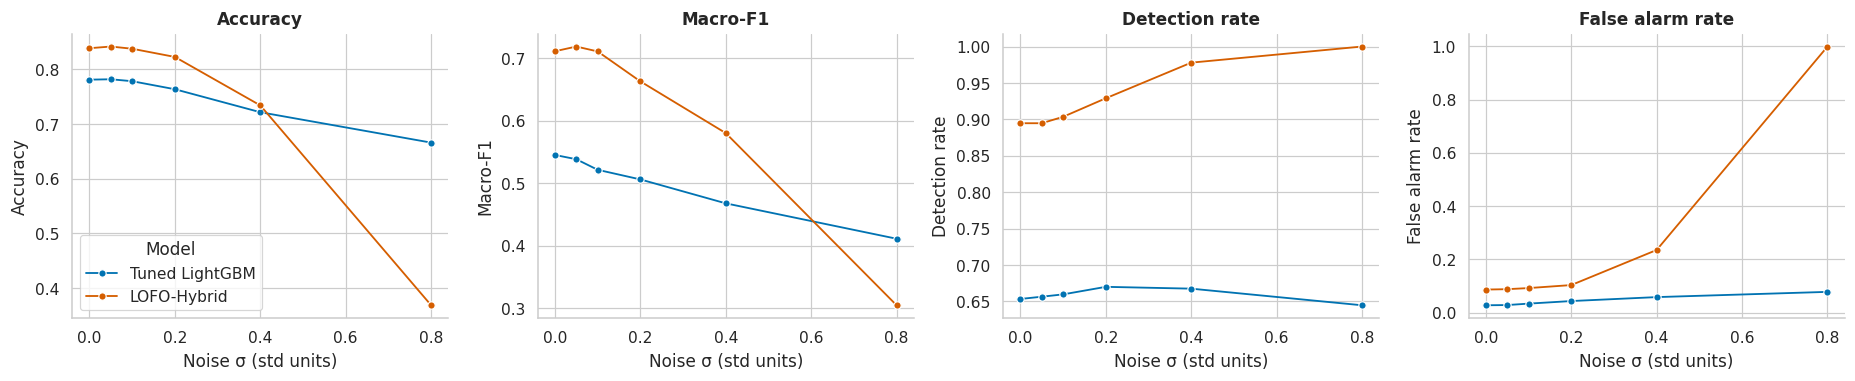

In [106]:
rng = np.random.RandomState(SEED)
rows = []
for sd in [0, 0.05, 0.1, 0.2, 0.4, 0.8]:
    Xn = Xte.copy(); Xn[:, CONT] += rng.normal(0, sd, (len(Xte), len(CONT))).astype(np.float32)
    for n, pr in [(LOFO_MODEL, proba_of(CLF, Xn).argmax(1)), ('LOFO-Hybrid', hybrid_from_X(Xn)[1])]:
        rows.append({'Noise σ (std units)': sd, 'Model': n, 'Accuracy': accuracy_score(yte, pr), 'Macro-F1': f1_score(yte, pr, average='macro'),
                     'Detection rate': (pr[yte > 0] > 0).mean(), 'False alarm rate': (pr[yte == 0] > 0).mean()})
NZ = save_table(pd.DataFrame(rows), 'T55_noise_robustness')
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a_, met in zip(ax, ['Accuracy', 'Macro-F1', 'Detection rate', 'False alarm rate']):
    sns.lineplot(data=NZ, x='Noise σ (std units)', y=met, hue='Model', marker='o', ax=a_, palette=[PAL[0], PAL[3]], legend=a_ is ax[0])
    a_.set_title(met)
savefig('noise_robustness')

### 95. Robustness to missing features (sensor or exporter failure)

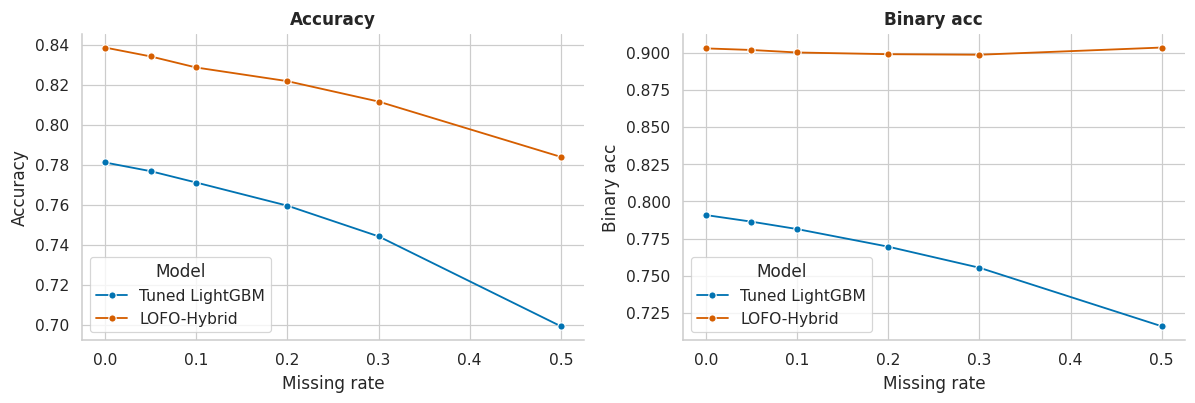

In [107]:
rng = np.random.RandomState(SEED)
rows = []
for r in [0, 0.05, 0.1, 0.2, 0.3, 0.5]:
    Xm = Xte.copy()
    mask = rng.rand(len(Xte), len(CONT)) < r
    sub = Xm[:, CONT]; sub[mask] = 0.0; Xm[:, CONT] = sub
    for n, pr in [(LOFO_MODEL, proba_of(CLF, Xm).argmax(1)), ('LOFO-Hybrid', hybrid_from_X(Xm)[1])]:
        rows.append({'Missing rate': r, 'Model': n, 'Accuracy': accuracy_score(yte, pr), 'Binary acc': accuracy_score(yte > 0, pr > 0)})
MSG = save_table(pd.DataFrame(rows), 'T56_missing_features')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a_, met in zip(ax, ['Accuracy', 'Binary acc']):
    sns.lineplot(data=MSG, x='Missing rate', y=met, hue='Model', marker='o', ax=a_, palette=[PAL[0], PAL[3]]); a_.set_title(met)
savefig('missing_feature_robustness')

### 96. Label-free drift detection with windowed KS tests and a calibrated Page-Hinkley monitor

,False alarms before shift,Detected the shift,Detection delay (records)
Detector,,,
"Windowed KS test (W=500, Bonferroni, 2 consecutive windows)",0,True,1402.0
"Page-Hinkley (λ calibrated on validation, λ=129.0)",0,False,NaN


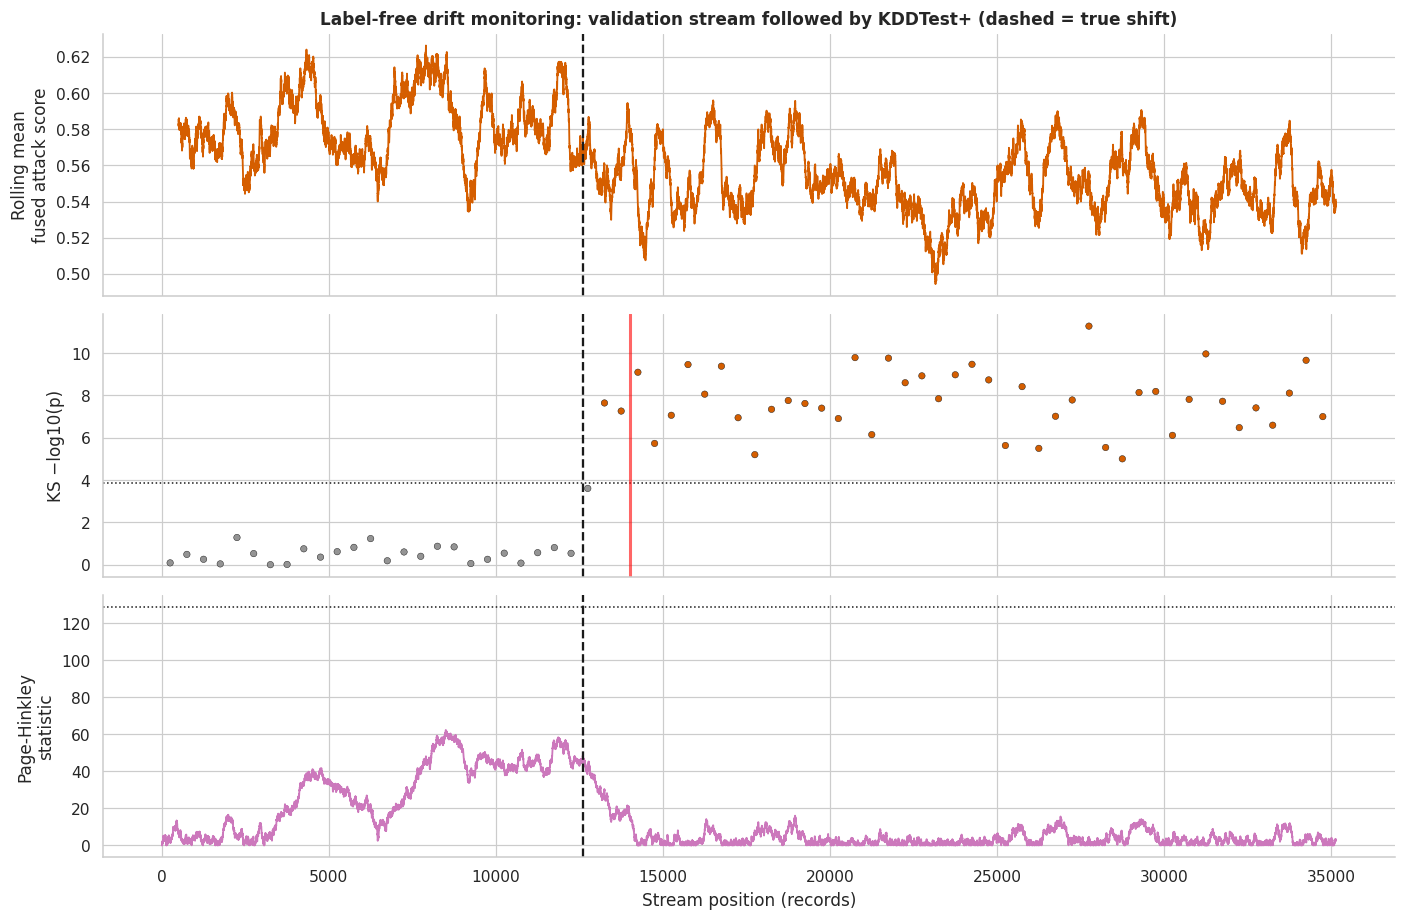

In [108]:
def page_hinkley(x, lam, delta=0.0):
    mean, cum, mn, alarms, stat = 0.0, 0.0, 0.0, [], []
    for t, v in enumerate(x, 1):
        mean += (v - mean) / t
        cum += v - mean - delta
        mn = min(mn, cum)
        stat.append(cum - mn)
        if cum - mn > lam:
            alarms.append(t - 1); mean, cum, mn = 0.0, 0.0, 0.0
    return np.array(stat), alarms

rng = np.random.RandomState(SEED)
perm = rng.permutation(len(Xva))
half = len(perm) // 2
ref_idx, mon_idx = perm[:half], perm[half:]
sig_ref = 1 - hybrid_from_X(Xva[ref_idx])[0][:, 0]
sig_mon_va = 1 - hybrid_from_X(Xva[mon_idx])[0][:, 0]
sig_te = 1 - hybrid_from_X(Xte)[0][:, 0]
stream = np.r_[sig_mon_va, sig_te]
SHIFT = len(sig_mon_va)
W = 500
n_win = len(stream) // W
ALPHA_D = 0.01 / n_win
pv = np.array([stats.ks_2samp(sig_ref, stream[k * W:(k + 1) * W]).pvalue for k in range(n_win)])
hit = pv < ALPHA_D
confirmed = [k for k in range(1, n_win) if hit[k] and hit[k - 1]]
ks_alarms = [(k + 1) * W for k in confirmed]

null_max = []
for b in range(50):
    s_ = rng.choice(sig_ref, len(sig_ref), replace=True)
    null_max.append(page_hinkley(s_, np.inf)[0].max())
LAM = float(np.quantile(null_max, 0.99))
ph_stat, ph_alarms = page_hinkley(stream, LAM)

def summarise(alarms, name):
    pre = [a for a in alarms if a < SHIFT]
    post = [a for a in alarms if a >= SHIFT]
    return {'Detector': name, 'False alarms before shift': len(pre),
            'Detected the shift': bool(post), 'Detection delay (records)': (post[0] - SHIFT) if post else np.nan}
DRIFT = save_table(pd.DataFrame([summarise(ks_alarms, f'Windowed KS test (W={W}, Bonferroni, 2 consecutive windows)'),
                                 summarise(ph_alarms, f'Page-Hinkley (λ calibrated on validation, λ={LAM:.1f})')]).set_index('Detector'), 'T59_drift_detection')
display(DRIFT)

fig, ax = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True)
ax[0].plot(pd.Series(stream).rolling(W).mean(), color=PAL[3])
ax[0].set_ylabel('Rolling mean\nfused attack score'); ax[0].set_title('Label-free drift monitoring: validation stream followed by KDDTest+ (dashed = true shift)')
ax[1].scatter(np.arange(n_win) * W + W / 2, -np.log10(pv + 1e-300), c=[PAL[3] if h else PAL[7] for h in hit], s=18, edgecolor='k', lw=.3)
ax[1].axhline(-np.log10(ALPHA_D), color='k', ls=':', lw=1)
ax[1].set_ylabel('KS −log10(p)')
ax[2].plot(ph_stat, color=PAL[4]); ax[2].axhline(LAM, color='k', ls=':', lw=1)
ax[2].set_ylabel('Page-Hinkley\nstatistic'); ax[2].set_xlabel('Stream position (records)')
for a_ in ax:
    a_.axvline(SHIFT, color='k', ls='--', lw=1.5)
for a in ks_alarms[:1]:
    ax[1].axvline(a, color='red', lw=2, alpha=.6)
for a in ph_alarms[:1]:
    ax[2].axvline(a, color='red', lw=2, alpha=.6)
savefig('drift_monitor')

### 97. Latency–accuracy–size Pareto frontier

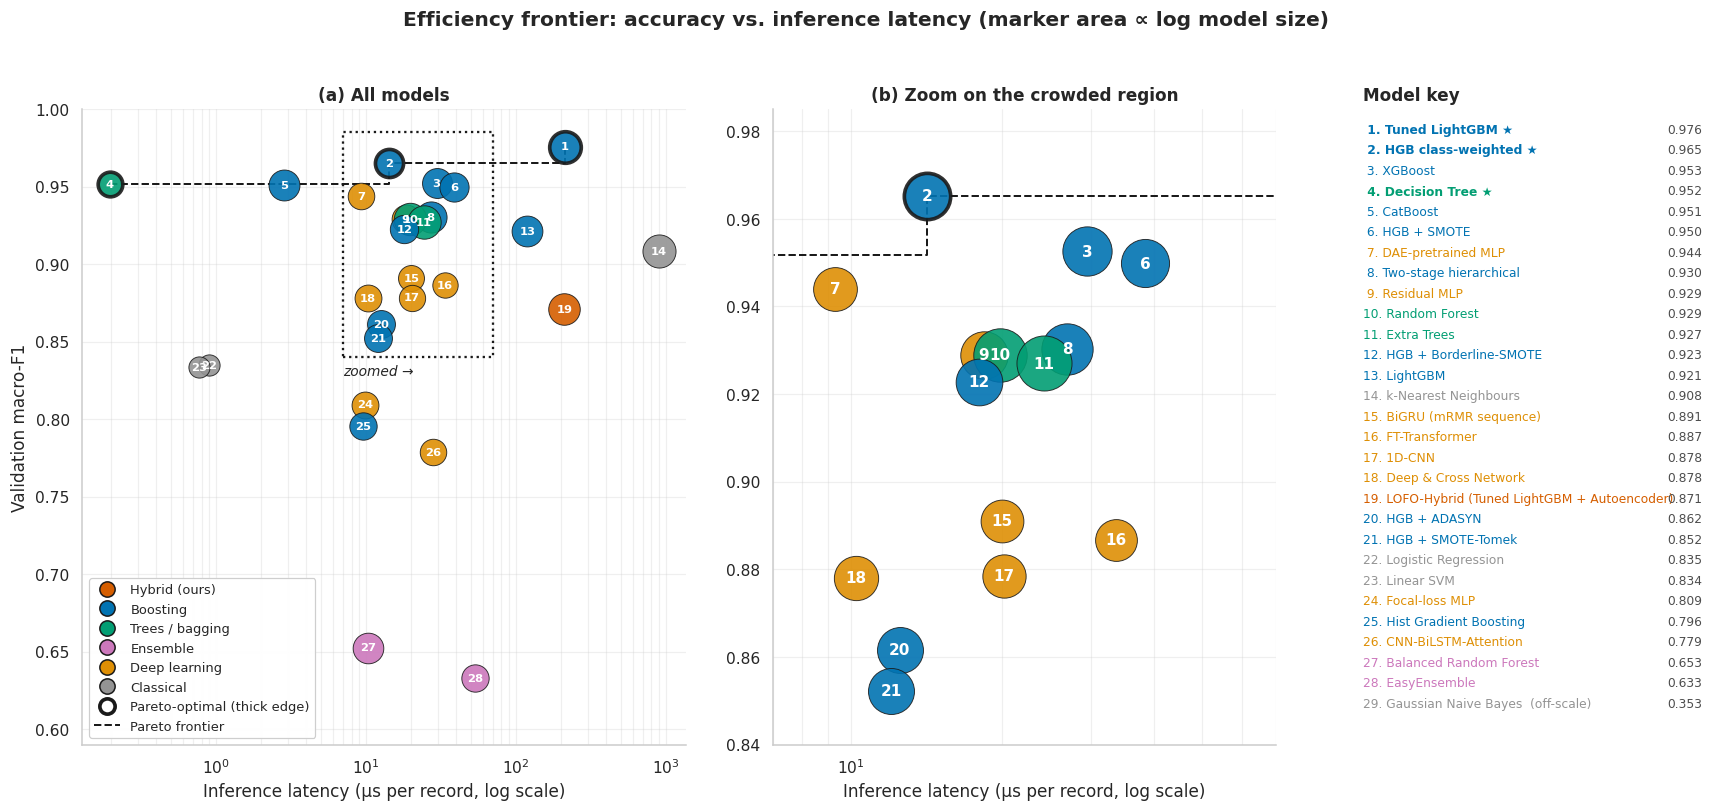

,ID,Family,Val macro-F1,Latency (µs/record),Size (KB)
Tuned LightGBM,1,Boosting,0.9759,212.5290,12424.4766
HGB class-weighted,2,Boosting,0.9652,14.1692,679.3301
Decision Tree,4,Trees / bagging,0.9518,0.1955,51.0107


In [109]:
LAT, F1 = 'Latency (µs/record)', 'Val macro-F1'
eff = pd.DataFrame({n: {F1: scores(yva, REG[n]['P']['va'], REG[n]['pred']['va'])['MacroF1'],
                        LAT: REG[n]['inf_ms'], 'Size (KB)': REG[n]['size_kb']} for n in REG}).T.dropna()
eff = eff.astype(float).sort_values(LAT)
eff['Pareto-optimal'] = eff[F1] >= eff[F1].cummax()
eff = eff.sort_values(F1, ascending=False)
eff['ID'] = np.arange(1, len(eff) + 1)
save_table(eff.round(4), 'T57_efficiency_pareto')

def family(n):
    if 'Hybrid' in n:
        return 'Hybrid (ours)'
    if any(k in n for k in ['voting', 'stacking', 'KNORA', 'EasyEnsemble', 'Balanced Random']):
        return 'Ensemble'
    if any(k in n for k in ['MLP', 'CNN', 'GRU', 'LSTM', 'Transformer', 'Cross Network']):
        return 'Deep learning'
    if any(k in n for k in ['Gradient', 'HGB', 'XGBoost', 'LightGBM', 'CatBoost', 'Two-stage', 'student']):
        return 'Boosting'
    if any(k in n for k in ['Forest', 'Trees', 'Decision']):
        return 'Trees / bagging'
    return 'Classical'

FAM_COL = {'Hybrid (ours)': PAL[3], 'Boosting': PAL[0], 'Trees / bagging': PAL[2],
           'Ensemble': PAL[4], 'Deep learning': PAL[1], 'Classical': PAL[7]}
eff['Family'] = [family(n) for n in eff.index]

YMIN = 0.60
ZOOM_X, ZOOM_Y = (7, 70), (0.84, 0.985)
main = eff[eff[F1] >= YMIN]
pf = eff[eff['Pareto-optimal']].sort_values(LAT)

def draw(ax, d, base, fs):
    ax.step(pf[LAT], pf[F1], where='post', color='k', lw=1.3, ls='--', zorder=1)
    for n, r in d.iterrows():
        s = base * (1 + np.log10(max(r['Size (KB)'], 1)) / 2)
        ax.scatter(r[LAT], r[F1], s=s, color=FAM_COL[r['Family']], edgecolor='k',
                   linewidth=2.4 if r['Pareto-optimal'] else 0.6, alpha=0.9, zorder=3)
        ax.text(r[LAT], r[F1], str(int(r['ID'])), ha='center', va='center', fontsize=fs,
                fontweight='bold', color='white', zorder=4, clip_on=True)
    ax.set_xscale('log')
    ax.grid(True, which='both', alpha=0.3)

fig = plt.figure(figsize=(19, 7.5))
gs = fig.add_gridspec(1, 3, width_ratios=[2.4, 2.0, 1.35], wspace=0.18)
ax1, ax2, ax3 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])

draw(ax1, main, 140, 7.5)
ax1.set_ylim(YMIN - 0.01, 1.0)
ax1.add_patch(plt.Rectangle((ZOOM_X[0], ZOOM_Y[0]), ZOOM_X[1] - ZOOM_X[0], ZOOM_Y[1] - ZOOM_Y[0],
                            fill=False, ls=':', lw=1.5, ec='k', zorder=5))
ax1.text(ZOOM_X[0], ZOOM_Y[0] - 0.012, 'zoomed →', fontsize=9, style='italic')
ax1.set_xlabel('Inference latency (µs per record, log scale)')
ax1.set_ylabel('Validation macro-F1')
ax1.set_title('(a) All models')

draw(ax2, main, 380, 10)
ax2.set_xlim(*ZOOM_X)
ax2.set_ylim(*ZOOM_Y)
ax2.set_xlabel('Inference latency (µs per record, log scale)')
ax2.set_title('(b) Zoom on the crowded region')

fam_handles = [plt.Line2D([0], [0], marker='o', ls='', markersize=10, markerfacecolor=c, markeredgecolor='k', label=f)
               for f, c in FAM_COL.items() if f in set(eff['Family'])]
extra = [plt.Line2D([0], [0], marker='o', ls='', markersize=10, markerfacecolor='w', markeredgecolor='k',
                    markeredgewidth=2.4, label='Pareto-optimal (thick edge)'),
         plt.Line2D([0], [0], color='k', ls='--', lw=1.3, label='Pareto frontier')]
ax1.legend(handles=fam_handles + extra, loc='lower left', fontsize=8.5, framealpha=0.95)

ax3.axis('off')
ax3.set_title('Model key', loc='left')
step = 1 / (len(eff) + 2)
for i, (n, r) in enumerate(eff.iterrows()):
    star = ' ★' if r['Pareto-optimal'] else ''
    off = '  (off-scale)' if r[F1] < YMIN else ''
    ax3.text(0.0, 1 - (i + 1) * step, f"{int(r['ID']):>2}. {n}{star}{off}",
             fontsize=8, color=FAM_COL[r['Family']], fontweight='bold' if star else 'normal',
             transform=ax3.transAxes, va='center')
    ax3.text(1.0, 1 - (i + 1) * step, f"{r[F1]:.3f}", fontsize=8, ha='right',
             transform=ax3.transAxes, va='center', color='0.3')

fig.suptitle('Efficiency frontier: accuracy vs. inference latency (marker area ∝ log model size)',
             fontweight='bold', y=1.0)
savefig('pareto_frontier')

display(eff[eff['Pareto-optimal']][['ID', 'Family', F1, LAT, 'Size (KB)']].round(4))

### 98. Knowledge distillation into a lightweight student

In [110]:
TEACHER = 'Weighted soft voting'
tm = [n for n in MEMBERS if REG[n]['kind'] != 'deep'] or [LOFO_MODEL]
tw = np.array([WV[MEMBERS.index(n)] if n in MEMBERS else 1.0 for n in tm]); tw = tw / tw.sum()
teacher = lambda X: sum(w * proba_of(REG[n]['model'], X) for w, n in zip(tw, tm))
rng = np.random.RandomState(SEED)
Xjit = Xtr + rng.normal(0, 0.05, Xtr.shape).astype(np.float32)
Xj = np.vstack([Xtr, Xjit])
yj = np.r_[teacher(Xtr).argmax(1), teacher(Xjit).argmax(1)]
student = HistGradientBoostingClassifier(max_iter=80, max_leaf_nodes=15, random_state=SEED)
fit_register('Distilled student (small GBM)', student, Xfit=Xj, yfit=yj)
cmp = ['Distilled student (small GBM)', LOFO_MODEL, TEACHER]
display(pd.concat([tvt(cmp)[['Validation Acc', 'KDDTest+ Acc', 'Validation MacroF1', 'KDDTest+ MacroF1']],
                   pd.DataFrame({n: {'Size (KB)': REG[n]['size_kb'], 'Latency (µs/record)': REG[n]['inf_ms']} for n in cmp}).T], axis=1).round(3))

,Validation Acc,KDDTest+ Acc,Validation MacroF1,KDDTest+ MacroF1,Size (KB),Latency (µs/record)
Distilled student (small GBM),0.996,0.771,0.798,0.513,354.113,3.805
Tuned LightGBM,0.999,0.781,0.976,0.545,12424.477,212.529
Weighted soft voting,0.999,0.781,0.975,0.550,23261.332,NaN


### 99. Edge-deployment study: lite forests over feature budget and tree count

,Features,Trees,Val macro-F1,Test accuracy,Size (KB),"Latency (µs/record, 1 core)"
0,10,10,0.942,0.774,1007.096,0.692
1,10,30,0.941,0.764,3087.053,1.924
2,10,60,0.958,0.777,6102.684,3.615
3,20,10,0.925,0.771,732.064,0.875
4,20,30,0.907,0.771,2208.740,1.771
5,20,60,0.926,0.769,4476.050,3.752
6,40,10,0.925,0.789,725.361,0.723
7,40,30,0.928,0.763,2228.435,1.985
8,40,60,0.909,0.763,4478.487,4.014


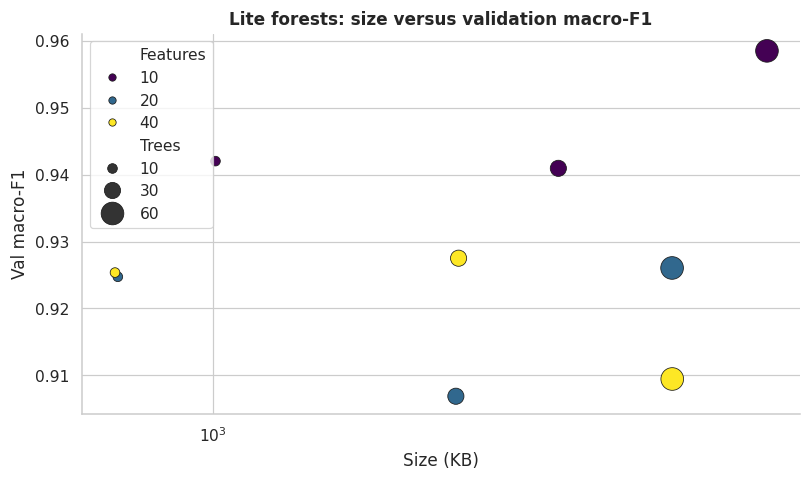

In [111]:
rows = []
for k in ((10, 20, 40) if not FAST else (10, 20)):
    ix = MRMR[:k]
    for nt in (10, 30, 60):
        m = RandomForestClassifier(nt, max_depth=16, n_jobs=1, random_state=SEED).fit(Xtr[:, ix], ytr)
        t = time.time(); p = m.predict(Xte[:, ix]); lat = (time.time() - t) / len(Xte) * 1e6
        rows.append({'Features': k, 'Trees': nt, 'Val macro-F1': f1_score(yva, m.predict(Xva[:, ix]), average='macro'),
                     'Test accuracy': accuracy_score(yte, p), 'Size (KB)': len(pickle.dumps(m)) / 1024, 'Latency (µs/record, 1 core)': lat})
LITE = save_table(pd.DataFrame(rows), 'T58_lite_forests')
display(LITE.round(3))
plt.figure(figsize=(7.5, 4.5))
sns.scatterplot(data=LITE, x='Size (KB)', y='Val macro-F1', hue='Features', size='Trees', sizes=(40, 220), palette='viridis', edgecolor='k')
plt.xscale('log'); plt.title('Lite forests: size versus validation macro-F1')
savefig('lite_forests')

### 100. Reproducibility manifest, model card and artefact export

In [112]:
import joblib
FINAL_ART = {'feature_builder': FB, 'classifier': CLF, 'anomaly_kind': BEST_KIND, 'alpha': ALPHA, 'tau': TAU, 'classes': CLASSES}
try:
    joblib.dump(FINAL_ART, os.path.join(OUT_DIR, 'final_hybrid_ids.joblib'))
except Exception as e:
    print('Full pipeline could not be pickled in this runtime:', str(e)[:80])
    joblib.dump({'classifier': CLF, 'alpha': ALPHA, 'tau': TAU, 'anomaly_kind': BEST_KIND}, os.path.join(OUT_DIR, 'final_hybrid_core.joblib'))
fin_te = scores(yte, REG[FINAL]['P']['te'], REG[FINAL]['pred']['te'], 'te')
fin_21 = scores(y21, REG[FINAL]['P']['t21'], REG[FINAL]['pred']['t21'], 't21')
manifest = {'created': time.strftime('%Y-%m-%d %H:%M:%S'), 'seed': SEED, 'fast_mode': FAST, 'python': platform.python_version(),
            'packages': {m.__name__: getattr(m, '__version__', None) for m in [np, pd, xgb, lgb, cb, shap, optuna, tf] if m is not None},
            'dataset_md5': INTEGRITY['MD5 (root)'].to_dict(), 'split': {'train': len(TR), 'validation': len(VA), 'test': len(tst), 'test21': len(t21)},
            'leakage_checks': LEAK, 'selection_rule': 'validation macro-F1 for the category layer; LOFO balanced accuracy for anomaly fusion',
            'final_system': FINAL, 'fusion': {'scorer': BEST_KIND, 'alpha': ALPHA, 'tau': TAU, 'classifier': LOFO_MODEL},
            'KDDTest+': {k: float(v) for k, v in fin_te.items()}, 'KDDTest-21': {k: float(v) for k, v in fin_21.items()}}
with open(os.path.join(OUT_DIR, 'run_manifest.json'), 'w') as f:
    json.dump(manifest, f, indent=2, default=str)
card = {'model': FINAL, 'intended_use': 'research benchmark of network intrusion detection on NSL-KDD',
        'limitations': ['NSL-KDD reflects 1998-era traffic', 'about 17% of KDDTest+ records are zero-day attack names',
                        'operating point chosen by LOFO validation, not tuned to any test file'],
        'metrics': manifest['KDDTest+']}
with open(os.path.join(OUT_DIR, 'model_card.json'), 'w') as f:
    json.dump(card, f, indent=2)
tvt(list(REG)).to_csv(os.path.join(TAB_DIR, 'ALL_models_train_val_test.csv'))
print('Saved to', OUT_DIR)
print(f'{len(os.listdir(FIG_DIR))} figures, {len(os.listdir(TAB_DIR))} tables, model, manifest and model card.')

Saved to /content/drive/MyDrive/ICEEICT/Paper 2/outputs
54 figures, 65 tables, model, manifest and model card.


### Headline results

In [113]:
H = pd.DataFrame({
    'Train Acc': [scores(YS['tr'], REG[n]['P']['tr'], REG[n]['pred']['tr'])['Acc'] for n in [FINAL, LOFO_MODEL]],
    'Validation Acc': [scores(yva, REG[n]['P']['va'], REG[n]['pred']['va'])['Acc'] for n in [FINAL, LOFO_MODEL]],
    'KDDTest+ Acc': [scores(yte, REG[n]['P']['te'], REG[n]['pred']['te'])['Acc'] for n in [FINAL, LOFO_MODEL]],
    'KDDTest+ MacroF1': [scores(yte, REG[n]['P']['te'], REG[n]['pred']['te'])['MacroF1'] for n in [FINAL, LOFO_MODEL]],
    'KDDTest+ Binary Acc': [scores(yte, REG[n]['P']['te'], REG[n]['pred']['te'])['BinAcc'] for n in [FINAL, LOFO_MODEL]],
    'KDDTest-21 Acc': [scores(y21, REG[n]['P']['t21'], REG[n]['pred']['t21'])['Acc'] for n in [FINAL, LOFO_MODEL]],
    'Zero-day DR': [scores(yte, REG[n]['P']['te'], REG[n]['pred']['te'], 'te')['ZeroDayDR'] for n in [FINAL, LOFO_MODEL]]},
    index=[f'Final: {FINAL}', f'Supervised core: {LOFO_MODEL}'])
H.loc['Jain et al. 2026 (P1) CNN-LSTM, same protocol'] = [np.nan, np.nan, 0.7761, 0.6068, 0.7936, np.nan, np.nan]
display(save_table((100 * H).round(2), 'T00_headline'))

,Train Acc,Validation Acc,KDDTest+ Acc,KDDTest+ MacroF1,KDDTest+ Binary Acc,KDDTest-21 Acc,Zero-day DR
Final: LOFO-Hybrid (Tuned LightGBM + Autoencoder),98.82,98.85,83.86,71.12,90.28,69.49,78.27
Supervised core: Tuned LightGBM,100.00,99.94,78.11,54.52,79.08,58.36,36.64
"Jain et al. 2026 (P1) CNN-LSTM, same protocol",NaN,NaN,77.61,60.68,79.36,NaN,NaN
